In [1]:
!pip install scikit-learn statsmodels prophet xgboost openpyxl

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from datetime import datetime

In [3]:
stations = pd.read_excel("ev_charging_dataset.xlsx", sheet_name="stations")
stations.head()

,station_id,station_name,region,activation_year,n_chargers
0,STN_001,EV FastCharge 1,North West,2022,4
1,STN_002,EV FastCharge 2,London,2022,5
2,STN_003,EV FastCharge 3,Midlands,2022,5
3,STN_004,EV FastCharge 4,North West,2022,8
4,STN_005,EV FastCharge 5,North West,2022,8


In [4]:
chargers = pd.read_excel("ev_charging_dataset.xlsx", sheet_name="chargers")
chargers.head()

,charger_id,station_id,charger_type,max_power_kW,installation_date
0,STN_001_CH_01,STN_001,DC_50kW,50,2022-06-07
1,STN_001_CH_02,STN_001,DC_150kW,150,2022-12-22
2,STN_001_CH_03,STN_001,DC_150kW,150,2022-10-21
3,STN_001_CH_04,STN_001,DC_50kW,50,2022-12-08
4,STN_002_CH_01,STN_002,DC_50kW,50,2022-07-09


In [5]:
sessions = pd.read_excel("ev_charging_dataset.xlsx", sheet_name="sessions")
sessions.head()

,session_id,station_id,charger_id,charger_type,start_timestamp,end_timestamp,session_duration_minutes,energy_kwh,price_per_kwh,total_cost,payment_method,user_type,customer_id,station_region,year
0,S_00000001,STN_001,STN_001_CH_02,DC_150kW,2022-01-01 08:30:00,2022-01-01 08:56:00,26,56.9,0.47,26.74,app,fleet,CUST_00134,North West,2022
1,S_00000002,STN_001,STN_001_CH_02,DC_150kW,2022-01-01 09:20:00,2022-01-01 09:41:00,21,40.7,0.46,18.72,app,delivery,CUST_00195,North West,2022
2,S_00000003,STN_001,STN_001_CH_04,DC_50kW,2022-01-01 09:00:00,2022-01-01 09:48:00,48,30.9,0.47,14.52,rfid,public,CUST_01935,North West,2022
3,S_00000004,STN_001,STN_001_CH_01,DC_50kW,2022-01-01 23:20:00,2022-01-02 00:01:00,41,28.4,0.45,12.78,rfid,public,CUST_00036,North West,2022
4,S_00000005,STN_001,STN_001_CH_01,DC_50kW,2022-01-01 16:10:00,2022-01-01 17:00:00,50,31.7,0.56,17.75,rfid,taxi,CUST_00011,North West,2022


In [6]:
sessions.shape

(294024, 15)

In [7]:
sessions.info()

<class 'pandas.DataFrame'>
RangeIndex: 294024 entries, 0 to 294023
Data columns (total 15 columns):
 #   Column                    Non-Null Count   Dtype         
---  ------                    --------------   -----         
 0   session_id                294024 non-null  str           
 1   station_id                294024 non-null  str           
 2   charger_id                294024 non-null  str           
 3   charger_type              294024 non-null  str           
 4   start_timestamp           294024 non-null  datetime64[us]
 5   end_timestamp             294024 non-null  datetime64[us]
 6   session_duration_minutes  294024 non-null  int64         
 7   energy_kwh                294024 non-null  float64       
 8   price_per_kwh             294024 non-null  float64       
 9   total_cost                294024 non-null  float64       
 10  payment_method            294024 non-null  str           
 11  user_type                 294024 non-null  str           
 12  customer_id  

In [8]:
sessions.isnull().sum()

session_id                  0
station_id                  0
charger_id                  0
charger_type                0
start_timestamp             0
end_timestamp               0
session_duration_minutes    0
energy_kwh                  0
price_per_kwh               0
total_cost                  0
payment_method              0
user_type                   0
customer_id                 0
station_region              0
year                        0
dtype: int64

In [9]:
sessions.duplicated().sum()

np.int64(0)

In [10]:
sessions.describe()

,start_timestamp,end_timestamp,session_duration_minutes,energy_kwh,price_per_kwh,total_cost,year
count,294024,294024,294024.000000,294024.000000,294024.000000,294024.000000,294024.000000
mean,2023-12-06 21:39:31.539058,2023-12-06 22:14:37.224715,35.094761,46.964689,0.592319,27.790589,2023.430618
min,2022-01-01 01:30:00,2022-01-01 01:54:00,15.000000,21.700000,0.450000,11.450000,2022.000000
25%,2023-05-20 05:25:00,2023-05-20 06:00:15,23.000000,33.200000,0.540000,19.700000,2023.000000
50%,2024-02-13 20:25:00,2024-02-13 21:04:00,27.000000,43.300000,0.590000,24.770000,2024.000000
75%,2024-07-24 06:42:30,2024-07-24 07:06:45,49.000000,54.000000,0.640000,33.250000,2024.000000
max,2024-12-31 23:50:00,2025-01-01 00:42:00,60.000000,80.000000,0.800000,64.000000,2024.000000
std,NaN,NaN,13.779933,16.631671,0.063600,10.268567,0.722238


In [11]:
sessions["session_id"].duplicated().sum()

np.int64(0)

In [12]:
(sessions["energy_kwh"] <= 0).sum()

np.int64(0)

In [13]:
(sessions["session_duration_minutes"] <= 0).sum()

np.int64(0)

In [14]:
(sessions["end_timestamp"] <= sessions["start_timestamp"]).sum()

np.int64(0)

In [15]:
sessions.groupby("year")["energy_kwh"].sum()

year
2022    2011828.0
2023    4049124.5
2024    7747793.3
Name: energy_kwh, dtype: float64

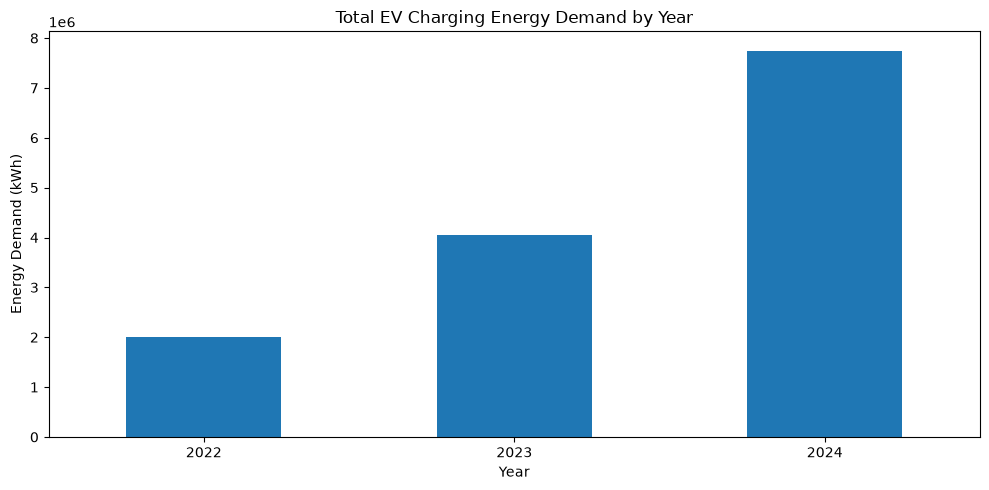

In [16]:
yearly_demand = sessions.groupby("year")["energy_kwh"].sum()

plt.figure(figsize=(10, 5))
yearly_demand.plot(kind="bar")
plt.title("Total EV Charging Energy Demand by Year")
plt.xlabel("Year")
plt.ylabel("Energy Demand (kWh)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

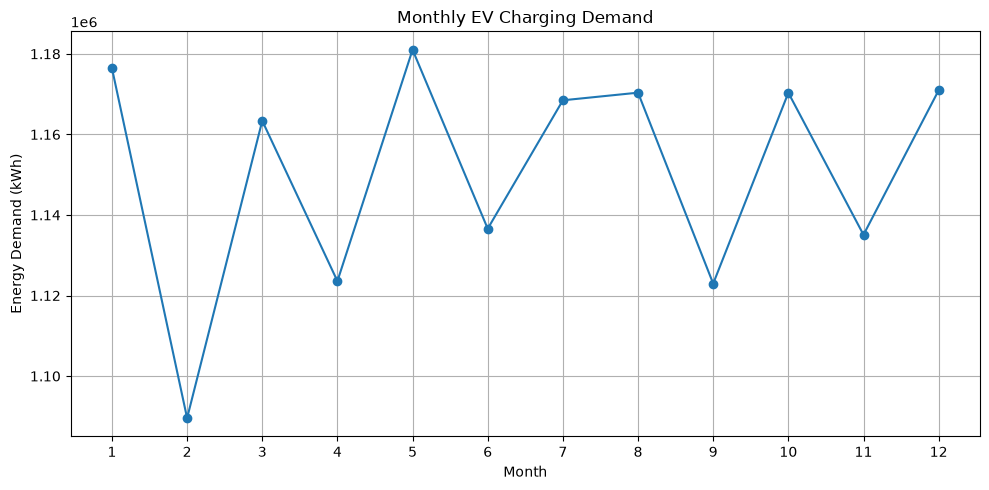

In [17]:
sessions["month"] = sessions["start_timestamp"].dt.month

monthly_demand = sessions.groupby("month")["energy_kwh"].sum()

plt.figure(figsize=(10, 5))
monthly_demand.plot(kind="line", marker="o")
plt.title("Monthly EV Charging Demand")
plt.xlabel("Month")
plt.ylabel("Energy Demand (kWh)")
plt.xticks(range(1, 13))
plt.grid(True)
plt.tight_layout()
plt.show()

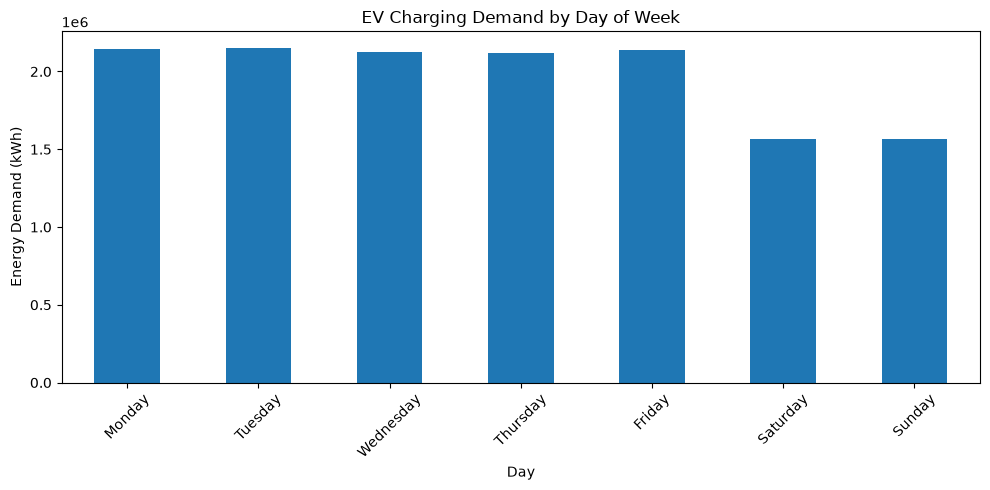

In [18]:
sessions["day_name"] = sessions["start_timestamp"].dt.day_name()

weekly_demand = sessions.groupby("day_name")["energy_kwh"].sum()

weekly_demand = weekly_demand.reindex([
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
])

plt.figure(figsize=(10, 5))
weekly_demand.plot(kind="bar")
plt.title("EV Charging Demand by Day of Week")
plt.xlabel("Day")
plt.ylabel("Energy Demand (kWh)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

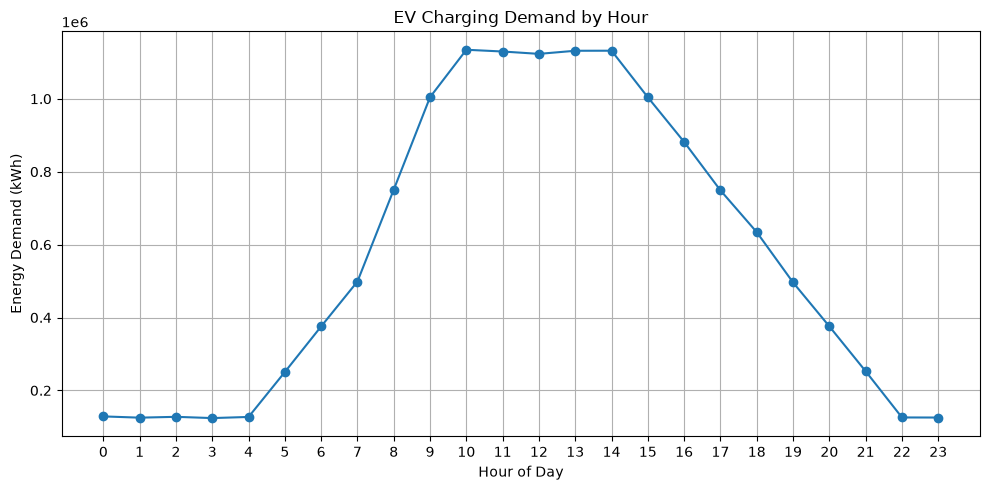

In [19]:
sessions["hour"] = sessions["start_timestamp"].dt.hour

hourly_demand = sessions.groupby("hour")["energy_kwh"].sum()

plt.figure(figsize=(10, 5))
hourly_demand.plot(kind="line", marker="o")
plt.title("EV Charging Demand by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Energy Demand (kWh)")
plt.xticks(range(24))
plt.grid(True)
plt.tight_layout()
plt.show()

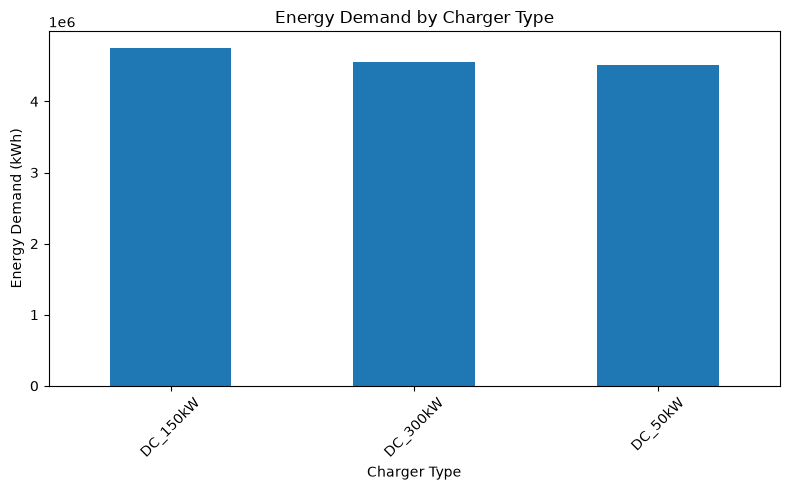

In [20]:
charger_demand = sessions.groupby("charger_type")["energy_kwh"].sum()

plt.figure(figsize=(8, 5))
charger_demand.plot(kind="bar")
plt.title("Energy Demand by Charger Type")
plt.xlabel("Charger Type")
plt.ylabel("Energy Demand (kWh)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [21]:
hourly_data = sessions.set_index("start_timestamp")["energy_kwh"].resample("h").sum()

hourly_data = hourly_data.reset_index()

hourly_data.columns = ["timestamp", "demand_kwh"]

hourly_data.head()

,timestamp,demand_kwh
0,2022-01-01 01:00:00,47.2
1,2022-01-01 02:00:00,37.4
2,2022-01-01 03:00:00,158.0
3,2022-01-01 04:00:00,0.0
4,2022-01-01 05:00:00,0.0


In [22]:
hourly_data.shape

(26303, 2)

In [23]:
hourly_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 26303 entries, 0 to 26302
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   timestamp   26303 non-null  datetime64[us]
 1   demand_kwh  26303 non-null  float64       
dtypes: datetime64[us](1), float64(1)
memory usage: 411.1 KB


In [24]:
hourly_data.isnull().sum()

timestamp     0
demand_kwh    0
dtype: int64

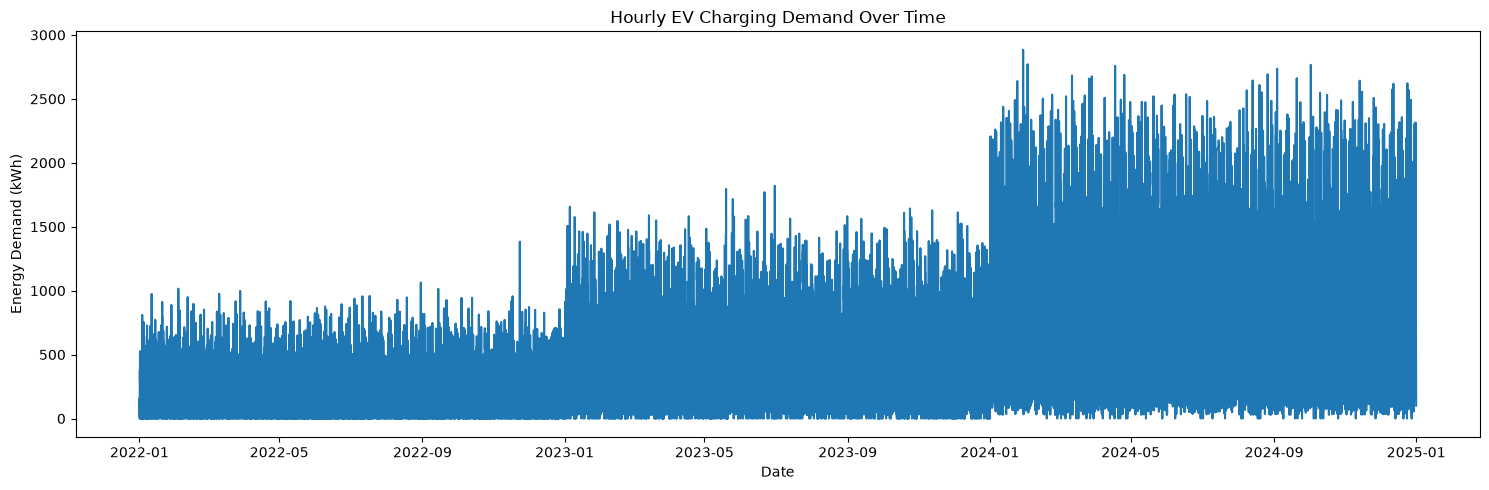

In [25]:
plt.figure(figsize=(15, 5))
plt.plot(hourly_data["timestamp"], hourly_data["demand_kwh"])
plt.title("Hourly EV Charging Demand Over Time")
plt.xlabel("Date")
plt.ylabel("Energy Demand (kWh)")
plt.tight_layout()
plt.show()

In [26]:
hourly_data.head(10)

,timestamp,demand_kwh
0,2022-01-01 01:00:00,47.2
1,2022-01-01 02:00:00,37.4
2,2022-01-01 03:00:00,158.0
3,2022-01-01 04:00:00,0.0
4,2022-01-01 05:00:00,0.0
5,2022-01-01 06:00:00,114.5
6,2022-01-01 07:00:00,213.4
7,2022-01-01 08:00:00,213.5
8,2022-01-01 09:00:00,380.3
9,2022-01-01 10:00:00,377.6


In [27]:
hourly_data.tail(10)

,timestamp,demand_kwh
26293,2024-12-31 14:00:00,2060.1
26294,2024-12-31 15:00:00,1646.3
26295,2024-12-31 16:00:00,1512.2
26296,2024-12-31 17:00:00,1590.9
26297,2024-12-31 18:00:00,1003.8
26298,2024-12-31 19:00:00,842.4
26299,2024-12-31 20:00:00,561.9
26300,2024-12-31 21:00:00,230.9
26301,2024-12-31 22:00:00,231.7
26302,2024-12-31 23:00:00,100.8


In [28]:
daily_data = sessions.set_index("start_timestamp")["energy_kwh"].resample("D").sum()

daily_data = daily_data.reset_index()

daily_data.columns = ["date", "demand_kwh"]

daily_data.head()

,date,demand_kwh
0,2022-01-01,5024.4
1,2022-01-02,3861.3
2,2022-01-03,6250.3
3,2022-01-04,5620.4
4,2022-01-05,6104.1


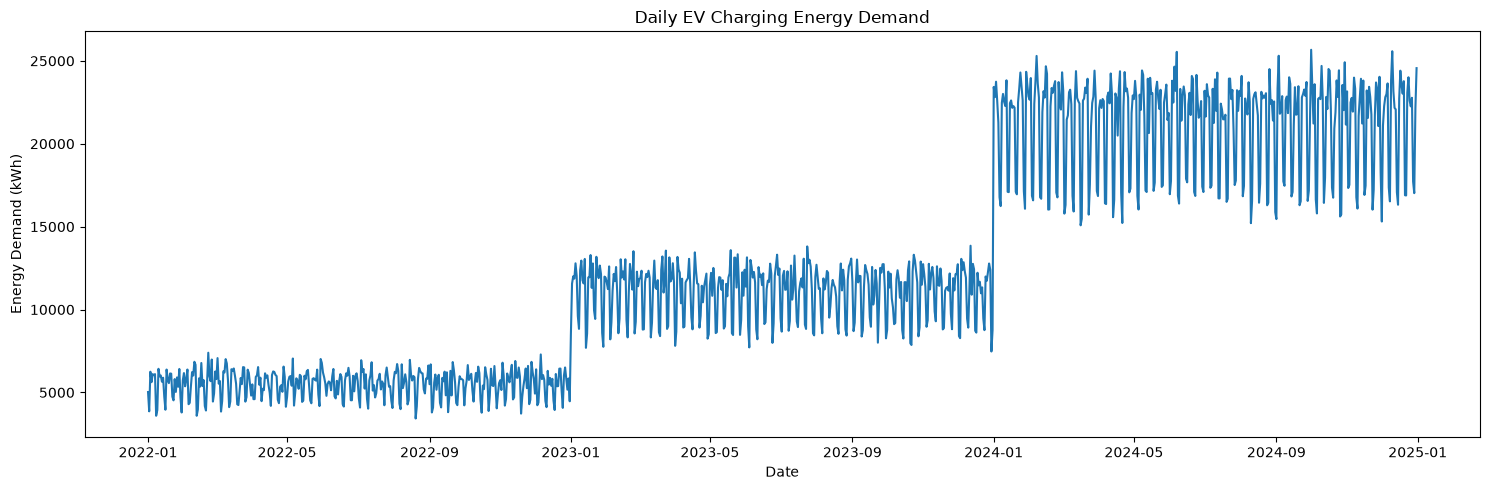

In [29]:
plt.figure(figsize=(15, 5))
plt.plot(daily_data["date"], daily_data["demand_kwh"])
plt.title("Daily EV Charging Energy Demand")
plt.xlabel("Date")
plt.ylabel("Energy Demand (kWh)")
plt.tight_layout()
plt.show()

In [30]:
hourly_data.to_csv("hourly_demand.csv", index=False)
daily_data.to_csv("daily_demand.csv", index=False)

print("Time-series datasets saved successfully!")

Time-series datasets saved successfully!


In [31]:
print("Start Date:", daily_data["date"].min())
print("End Date:", daily_data["date"].max())
print("Total Days:", len(daily_data))

Start Date: 2022-01-01 00:00:00
End Date: 2024-12-31 00:00:00
Total Days: 1096


In [32]:
daily_data["date"] = pd.to_datetime(daily_data["date"])

expected_dates = pd.date_range(
    start=daily_data["date"].min(),
    end=daily_data["date"].max(),
    freq="D"
)

missing_dates = expected_dates.difference(daily_data["date"])

print("Missing dates:", len(missing_dates))

Missing dates: 0


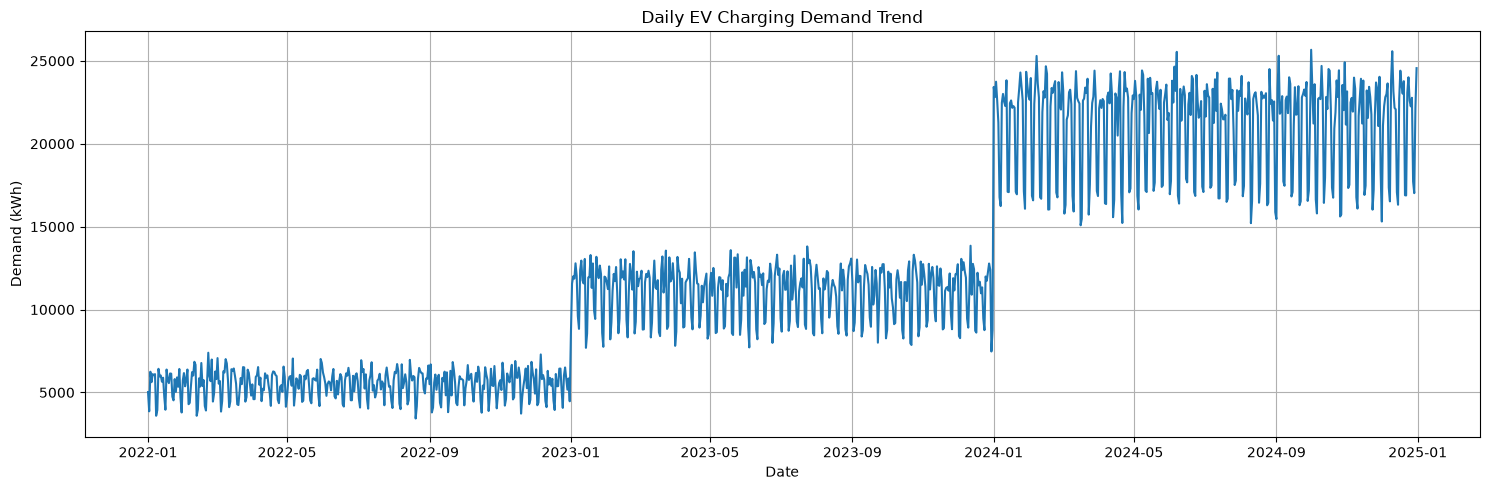

In [33]:
plt.figure(figsize=(15, 5))
plt.plot(daily_data["date"], daily_data["demand_kwh"])
plt.title("Daily EV Charging Demand Trend")
plt.xlabel("Date")
plt.ylabel("Demand (kWh)")
plt.grid(True)
plt.tight_layout()
plt.show()

In [34]:
daily_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1096 entries, 0 to 1095
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   date        1096 non-null   datetime64[us]
 1   demand_kwh  1096 non-null   float64       
dtypes: datetime64[us](1), float64(1)
memory usage: 17.3 KB


In [35]:
daily_data.isnull().sum()

date          0
demand_kwh    0
dtype: int64

In [36]:
(daily_data["demand_kwh"] == 0).sum()

np.int64(0)

In [37]:
daily_data["demand_kwh"].describe()

count     1096.000000
mean     12599.220620
std       6778.440236
min       3428.000000
25%       6111.725000
50%      11611.550000
75%      17513.500000
max      25668.700000
Name: demand_kwh, dtype: float64

In [38]:
train = daily_data.iloc[:-90]
test = daily_data.iloc[-90:]

print("Training data:", len(train))
print("Testing data:", len(test))

Training data: 1006
Testing data: 90


In [39]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

In [40]:
model = SARIMAX(
    train["demand_kwh"],
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 7)
)

sarima_model = model.fit()

print(sarima_model.summary())

                                     SARIMAX Results                                     
Dep. Variable:                        demand_kwh   No. Observations:                 1006
Model:             SARIMAX(1, 1, 1)x(1, 1, 1, 7)   Log Likelihood               -8261.706
Date:                           Sat, 28 Nov 2026   AIC                          16533.411
Time:                                   17:29:32   BIC                          16557.940
Sample:                                        0   HQIC                         16542.735
                                          - 1006                                         
Covariance Type:                             opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.1654      0.033      5.071      0.000       0.101       0.229
ma.L1         -0.6917      0.025    -27.405

In [41]:
sarima_predictions = sarima_model.forecast(steps=90)

print(sarima_predictions.head())

1006    23415.807284
1007    23874.903518
1008    17393.771498
1009    17660.519130
1010    23361.040876
Name: predicted_mean, dtype: float64


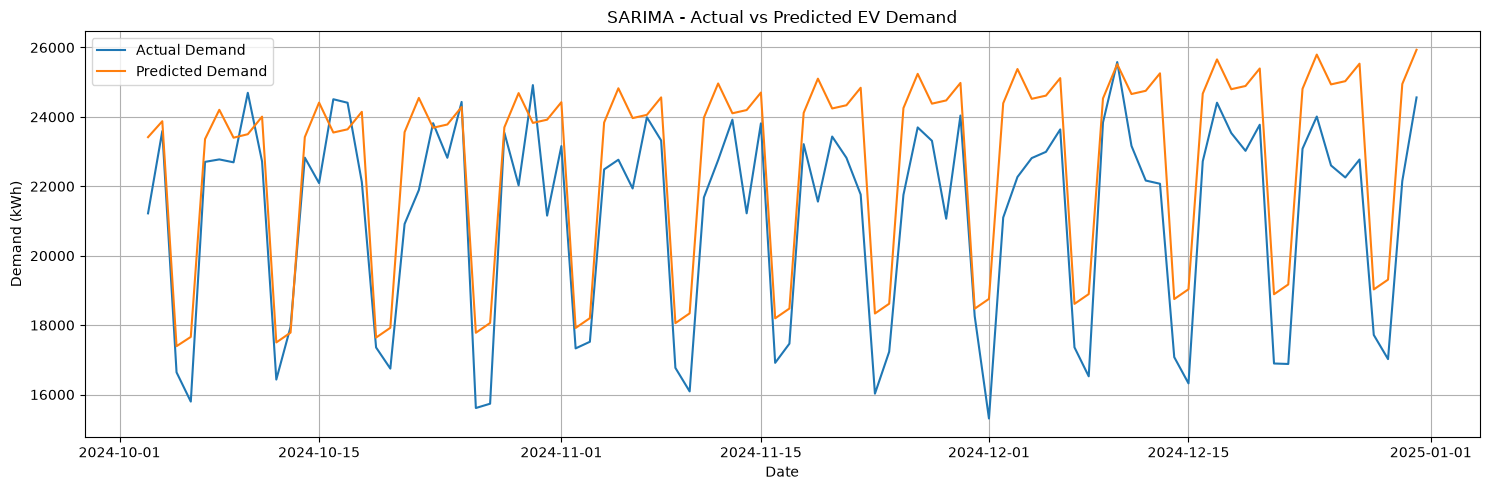

In [42]:
plt.figure(figsize=(15,5))

plt.plot(test["date"], test["demand_kwh"], label="Actual Demand")
plt.plot(test["date"], sarima_predictions.values, label="Predicted Demand")

plt.title("SARIMA - Actual vs Predicted EV Demand")
plt.xlabel("Date")
plt.ylabel("Demand (kWh)")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [43]:
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_percentage_error

rmse = np.sqrt(mean_squared_error(test["demand_kwh"], sarima_predictions))

mape = mean_absolute_percentage_error(test["demand_kwh"], sarima_predictions) * 100

print("SARIMA RMSE:", rmse)
print("SARIMA MAPE:", mape, "%")

SARIMA RMSE: 1860.6099589773014
SARIMA MAPE: 7.968334173434928 %


In [44]:
sarima_results = pd.DataFrame({
    "date": test["date"].values,
    "actual_demand": test["demand_kwh"].values,
    "predicted_demand": sarima_predictions.values
})

sarima_results.head()

,date,actual_demand,predicted_demand
0,2024-10-03,21220.4,23415.807284
1,2024-10-04,23590.9,23874.903518
2,2024-10-05,16640.2,17393.771498
3,2024-10-06,15796.8,17660.519130
4,2024-10-07,22704.1,23361.040876


In [45]:
sarima_results.to_csv("sarima_results.csv", index=False)

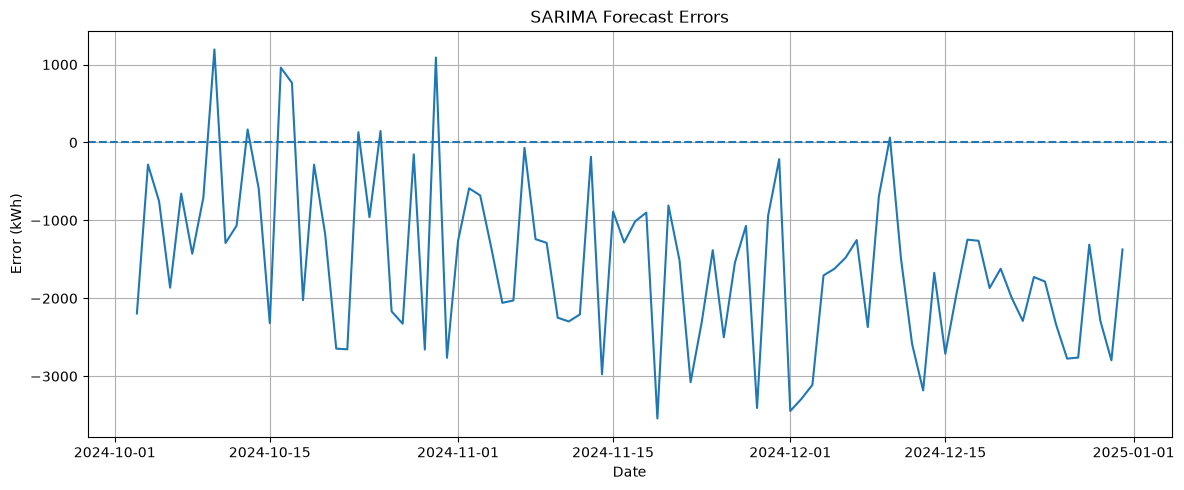

In [46]:
sarima_results["error"] = (
    sarima_results["actual_demand"] -
    sarima_results["predicted_demand"]
)

plt.figure(figsize=(12, 5))
plt.plot(sarima_results["date"], sarima_results["error"])
plt.axhline(y=0, linestyle="--")
plt.title("SARIMA Forecast Errors")
plt.xlabel("Date")
plt.ylabel("Error (kWh)")
plt.grid(True)
plt.tight_layout()
plt.show()

In [47]:
prophet_data = daily_data.rename(columns={
    "date": "ds",
    "demand_kwh": "y"
})

prophet_data.head()

,ds,y
0,2022-01-01,5024.4
1,2022-01-02,3861.3
2,2022-01-03,6250.3
3,2022-01-04,5620.4
4,2022-01-05,6104.1


In [48]:
prophet_train = prophet_data.iloc[:-90]
prophet_test = prophet_data.iloc[-90:]

In [49]:
from prophet import Prophet

prophet_model = Prophet(
    weekly_seasonality=True,
    yearly_seasonality=True,
    daily_seasonality=False
)

prophet_model.fit(prophet_train)

17:29:35 - cmdstanpy - INFO - Chain [1] start processing
17:29:36 - cmdstanpy - INFO - Chain [1] done processing


In [50]:
from prophet import Prophet

prophet_model = Prophet(
    weekly_seasonality=True,
    yearly_seasonality=True,
    daily_seasonality=False
)

prophet_model.fit(prophet_train)

17:29:36 - cmdstanpy - INFO - Chain [1] start processing
17:29:36 - cmdstanpy - INFO - Chain [1] done processing


In [51]:
prophet_forecast = prophet_model.predict(prophet_test[["ds"]])

prophet_predictions = prophet_forecast["yhat"]

print(prophet_predictions.head())

0    22089.705232
1    22123.151651
2    18684.797431
3    18738.232894
4    22194.338930
Name: yhat, dtype: float64


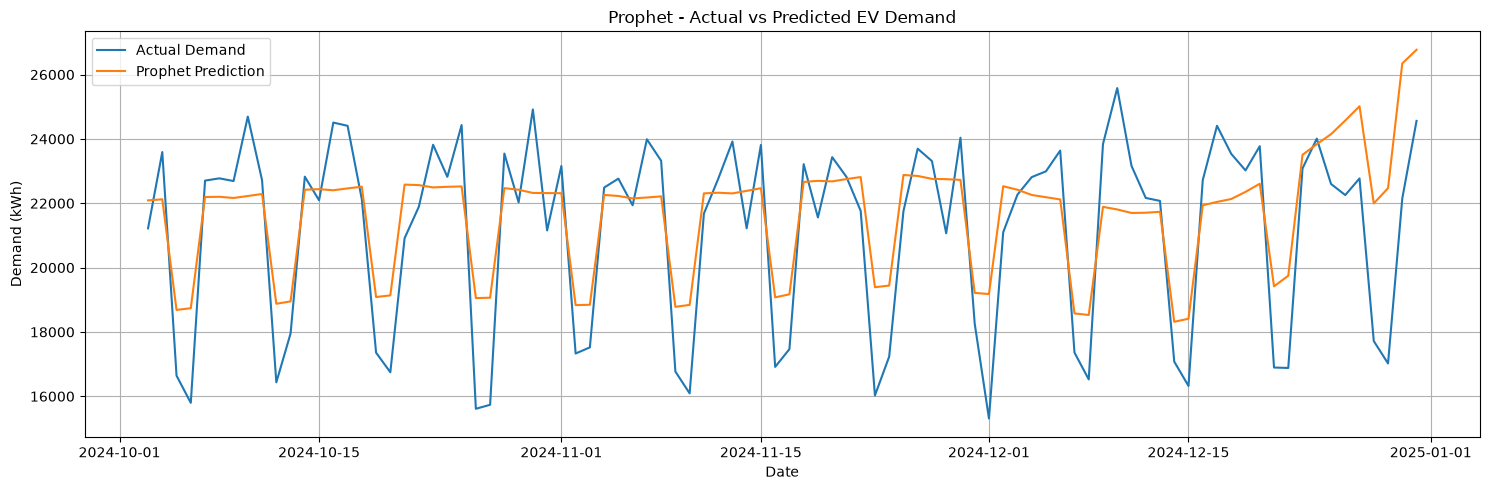

In [52]:
plt.figure(figsize=(15,5))

plt.plot(prophet_test["ds"], prophet_test["y"], label="Actual Demand")
plt.plot(prophet_test["ds"], prophet_predictions.values, label="Prophet Prediction")

plt.title("Prophet - Actual vs Predicted EV Demand")
plt.xlabel("Date")
plt.ylabel("Demand (kWh)")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [53]:
prophet_rmse = np.sqrt(
    mean_squared_error(prophet_test["y"], prophet_predictions)
)

prophet_mape = mean_absolute_percentage_error(
    prophet_test["y"], prophet_predictions
) * 100

print("Prophet RMSE:", prophet_rmse)
print("Prophet MAPE:", prophet_mape, "%")

Prophet RMSE: 1858.545466026705
Prophet MAPE: 7.754337118867539 %


In [54]:
prophet_results = pd.DataFrame({
    "date": prophet_test["ds"].values,
    "actual_demand": prophet_test["y"].values,
    "predicted_demand": prophet_predictions.values
})

prophet_results.head()

,date,actual_demand,predicted_demand
0,2024-10-03,21220.4,22089.705232
1,2024-10-04,23590.9,22123.151651
2,2024-10-05,16640.2,18684.797431
3,2024-10-06,15796.8,18738.232894
4,2024-10-07,22704.1,22194.338930


In [55]:
prophet_results.to_csv("prophet_results.csv", index=False)

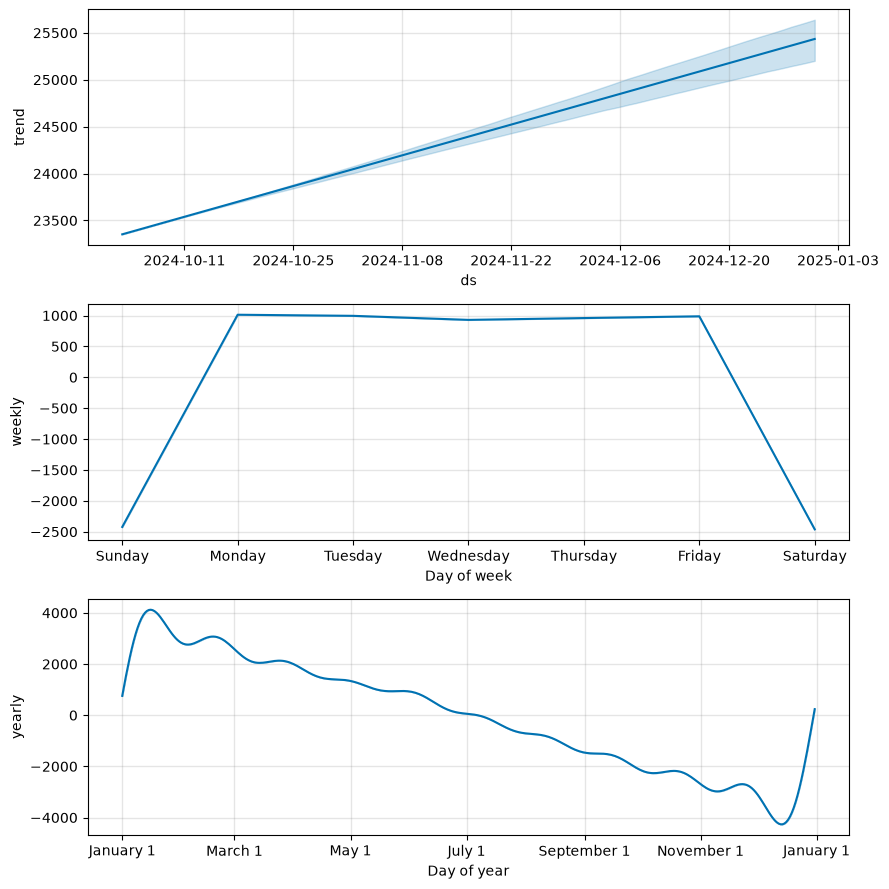

In [56]:
prophet_model.plot_components(prophet_forecast)
plt.show()

In [57]:
xgb_data = daily_data.copy()

xgb_data["day"] = xgb_data["date"].dt.day
xgb_data["month"] = xgb_data["date"].dt.month
xgb_data["year"] = xgb_data["date"].dt.year
xgb_data["day_of_week"] = xgb_data["date"].dt.dayofweek
xgb_data["week_of_year"] = xgb_data["date"].dt.isocalendar().week.astype(int)

xgb_data.head()

,date,demand_kwh,day,month,year,day_of_week,week_of_year
0,2022-01-01,5024.4,1,1,2022,5,52
1,2022-01-02,3861.3,2,1,2022,6,52
2,2022-01-03,6250.3,3,1,2022,0,1
3,2022-01-04,5620.4,4,1,2022,1,1
4,2022-01-05,6104.1,5,1,2022,2,1


In [58]:
xgb_data["lag_1"] = xgb_data["demand_kwh"].shift(1)
xgb_data["lag_7"] = xgb_data["demand_kwh"].shift(7)
xgb_data["lag_14"] = xgb_data["demand_kwh"].shift(14)

xgb_data["rolling_mean_7"] = xgb_data["demand_kwh"].shift(1).rolling(7).mean()

xgb_data.head(15)

,date,demand_kwh,day,month,year,day_of_week,week_of_year,lag_1,lag_7,lag_14,rolling_mean_7
0,2022-01-01,5024.4,1,1,2022,5,52,NaN,NaN,NaN,NaN
1,2022-01-02,3861.3,2,1,2022,6,52,5024.4,NaN,NaN,NaN
2,2022-01-03,6250.3,3,1,2022,0,1,3861.3,NaN,NaN,NaN
3,2022-01-04,5620.4,4,1,2022,1,1,6250.3,NaN,NaN,NaN
4,2022-01-05,6104.1,5,1,2022,2,1,5620.4,NaN,NaN,NaN
5,2022-01-06,6041.6,6,1,2022,3,1,6104.1,NaN,NaN,NaN
6,2022-01-07,6105.7,7,1,2022,4,1,6041.6,NaN,NaN,NaN
7,2022-01-08,3593.9,8,1,2022,5,1,6105.7,5024.4,NaN,5572.542857
8,2022-01-09,3934.2,9,1,2022,6,1,3593.9,3861.3,NaN,5368.185714
9,2022-01-10,6425.7,10,1,2022,0,2,3934.2,6250.3,NaN,5378.600000


In [59]:
xgb_data = xgb_data.dropna().reset_index(drop=True)
xgb_data.isnull().sum()

date              0
demand_kwh        0
day               0
month             0
year              0
day_of_week       0
week_of_year      0
lag_1             0
lag_7             0
lag_14            0
rolling_mean_7    0
dtype: int64

In [60]:
xgb_train = xgb_data.iloc[:-90]
xgb_test = xgb_data.iloc[-90:]

print("Training data:", len(xgb_train))
print("Testing data:", len(xgb_test))

Training data: 992
Testing data: 90


In [61]:
features = [
    "day",
    "month",
    "year",
    "day_of_week",
    "week_of_year",
    "lag_1",
    "lag_7",
    "lag_14",
    "rolling_mean_7"
]

X_train = xgb_train[features]
y_train = xgb_train["demand_kwh"]

X_test = xgb_test[features]
y_test = xgb_test["demand_kwh"]

In [62]:
from xgboost import XGBRegressor
xgb_model = XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=5,
    random_state=42
)
xgb_model.fit(X_train, y_train)

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [63]:
xgb_predictions = xgb_model.predict(X_test)

print(xgb_predictions[:5])

[24099.824 23677.91  16613.895 16843.816 21618.477]


In [64]:
xgb_rmse = np.sqrt(mean_squared_error(y_test, xgb_predictions))

xgb_mape = mean_absolute_percentage_error(y_test, xgb_predictions) * 100

print("XGBoost RMSE:", xgb_rmse)
print("XGBoost MAPE:", xgb_mape, "%")


XGBoost RMSE: 1144.5141376736722
XGBoost MAPE: 4.155522866156171 %


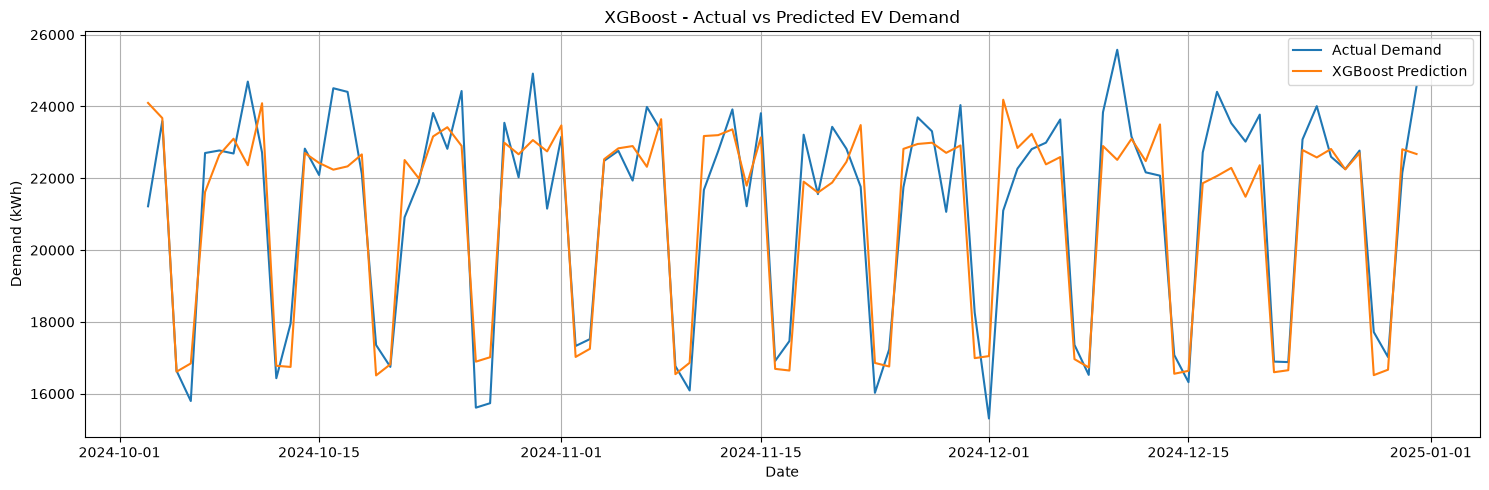

In [65]:
plt.figure(figsize=(15,5))

plt.plot(xgb_test["date"], y_test, label="Actual Demand")
plt.plot(xgb_test["date"], xgb_predictions, label="XGBoost Prediction")

plt.title("XGBoost - Actual vs Predicted EV Demand")
plt.xlabel("Date")
plt.ylabel("Demand (kWh)")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [66]:
xgb_results = pd.DataFrame({
    "date": xgb_test["date"].values,
    "actual_demand": y_test.values,
    "predicted_demand": xgb_predictions
})

xgb_results.to_csv("xgboost_results.csv", index=False)

In [67]:
model_comparison = pd.DataFrame({
    "Model": ["SARIMA", "Prophet", "XGBoost"],
    "RMSE": [rmse, prophet_rmse, xgb_rmse],
    "MAPE (%)": [mape, prophet_mape, xgb_mape]
})

model_comparison

,Model,RMSE,MAPE (%)
0,SARIMA,1860.609959,7.968334
1,Prophet,1858.545466,7.754337
2,XGBoost,1144.514138,4.155523


In [68]:
model_comparison.sort_values(by="RMSE", ascending=True)

,Model,RMSE,MAPE (%)
2,XGBoost,1144.514138,4.155523
1,Prophet,1858.545466,7.754337
0,SARIMA,1860.609959,7.968334


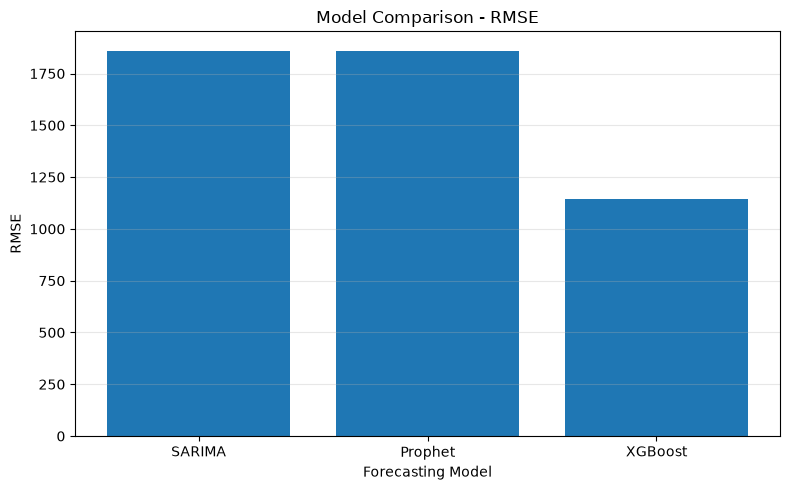

In [69]:
plt.figure(figsize=(8,5))

plt.bar(model_comparison["Model"], model_comparison["RMSE"])

plt.title("Model Comparison - RMSE")
plt.xlabel("Forecasting Model")
plt.ylabel("RMSE")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

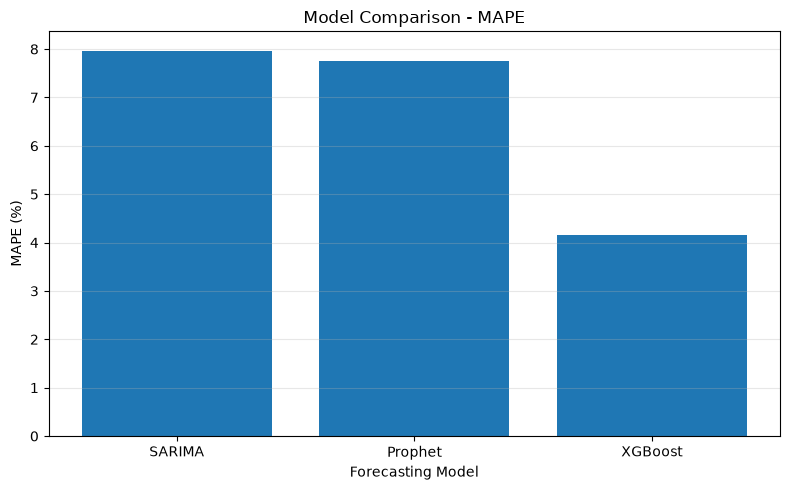

In [70]:
plt.figure(figsize=(8,5))

plt.bar(model_comparison["Model"], model_comparison["MAPE (%)"])

plt.title("Model Comparison - MAPE")
plt.xlabel("Forecasting Model")
plt.ylabel("MAPE (%)")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [71]:
last_date = daily_data["date"].max()

print("Last recorded date:", last_date)

Last recorded date: 2024-12-31 00:00:00


In [72]:
future_dates = pd.date_range(
    start=last_date + pd.Timedelta(days=1),
    periods=365,
    freq="D"
)

future_data = pd.DataFrame({
    "date": future_dates
})

future_data.head()

,date
0,2025-01-01
1,2025-01-02
2,2025-01-03
3,2025-01-04
4,2025-01-05


In [73]:
history = daily_data["demand_kwh"].tolist()

future_predictions = []

for date in future_dates:

    features_future = pd.DataFrame([{
        "day": date.day,
        "month": date.month,
        "year": date.year,
        "day_of_week": date.dayofweek,
        "week_of_year": date.isocalendar().week,
        "lag_1": history[-1],
        "lag_7": history[-7],
        "lag_14": history[-14],
        "rolling_mean_7": np.mean(history[-7:])
    }])

    prediction = xgb_model.predict(features_future)[0]

    future_predictions.append(prediction)
    history.append(prediction)

In [74]:
xgb_forecast = pd.DataFrame({
    "date": future_dates,
    "predicted_demand": future_predictions
})

xgb_forecast.head()


,date,predicted_demand
0,2025-01-01,23165.392578
1,2025-01-02,22359.375000
2,2025-01-03,22791.861328
3,2025-01-04,17104.890625
4,2025-01-05,16736.587891


In [75]:
xgb_forecast.shape

(365, 2)

In [76]:
forecast_30 = xgb_forecast.head(30).copy()
forecast_90 = xgb_forecast.head(90).copy()
forecast_365 = xgb_forecast.copy()

print("30-day forecast:", len(forecast_30))
print("90-day forecast:", len(forecast_90))
print("365-day forecast:", len(forecast_365))

30-day forecast: 30
90-day forecast: 90
365-day forecast: 365


In [77]:
print("30-day total demand:", forecast_30["predicted_demand"].sum(), "kWh")

print("90-day total demand:", forecast_90["predicted_demand"].sum(), "kWh")

print("365-day total demand:", forecast_365["predicted_demand"].sum(), "kWh")

30-day total demand: 642019.56 kWh
90-day total demand: 1.9077461e+06 kWh
365-day total demand: 7.7238615e+06 kWh


In [78]:
print("30-day average demand:", forecast_30["predicted_demand"].mean(), "kWh/day")

print("90-day average demand:", forecast_90["predicted_demand"].mean(), "kWh/day")

print("365-day average demand:", forecast_365["predicted_demand"].mean(), "kWh/day")

30-day average demand: 21400.652 kWh/day
90-day average demand: 21197.18 kWh/day
365-day average demand: 21161.264 kWh/day


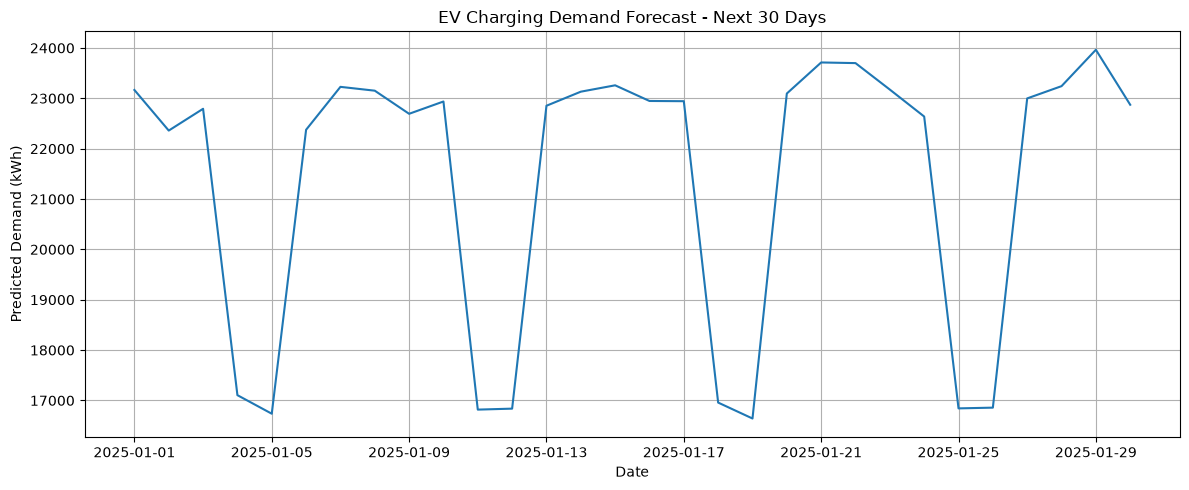

In [79]:
plt.figure(figsize=(12,5))

plt.plot(forecast_30["date"], forecast_30["predicted_demand"])

plt.title("EV Charging Demand Forecast - Next 30 Days")
plt.xlabel("Date")
plt.ylabel("Predicted Demand (kWh)")
plt.grid(True)

plt.tight_layout()
plt.show()

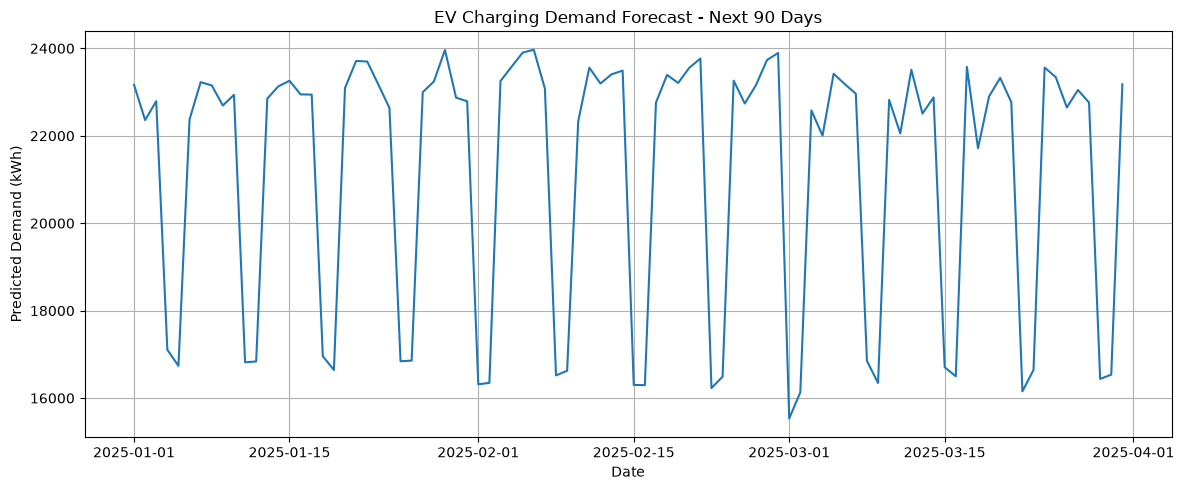

In [80]:
plt.figure(figsize=(12,5))

plt.plot(forecast_90["date"], forecast_90["predicted_demand"])

plt.title("EV Charging Demand Forecast - Next 90 Days")
plt.xlabel("Date")
plt.ylabel("Predicted Demand (kWh)")
plt.grid(True)

plt.tight_layout()
plt.show()

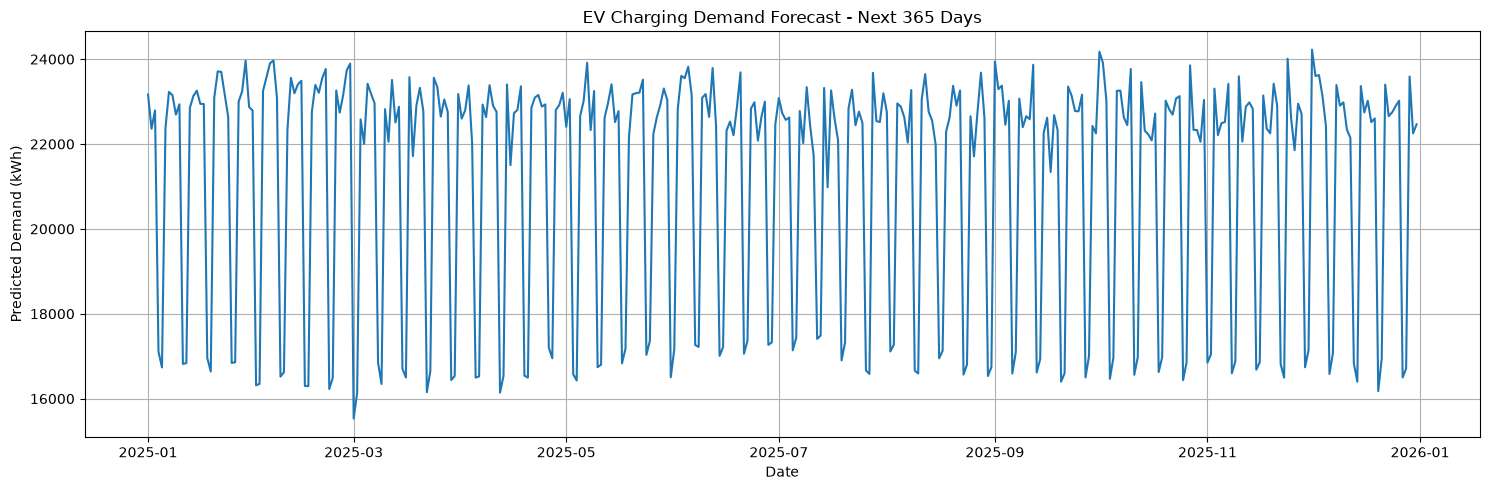

In [81]:
plt.figure(figsize=(15,5))

plt.plot(forecast_365["date"], forecast_365["predicted_demand"])

plt.title("EV Charging Demand Forecast - Next 365 Days")
plt.xlabel("Date")
plt.ylabel("Predicted Demand (kWh)")
plt.grid(True)

plt.tight_layout()
plt.show()

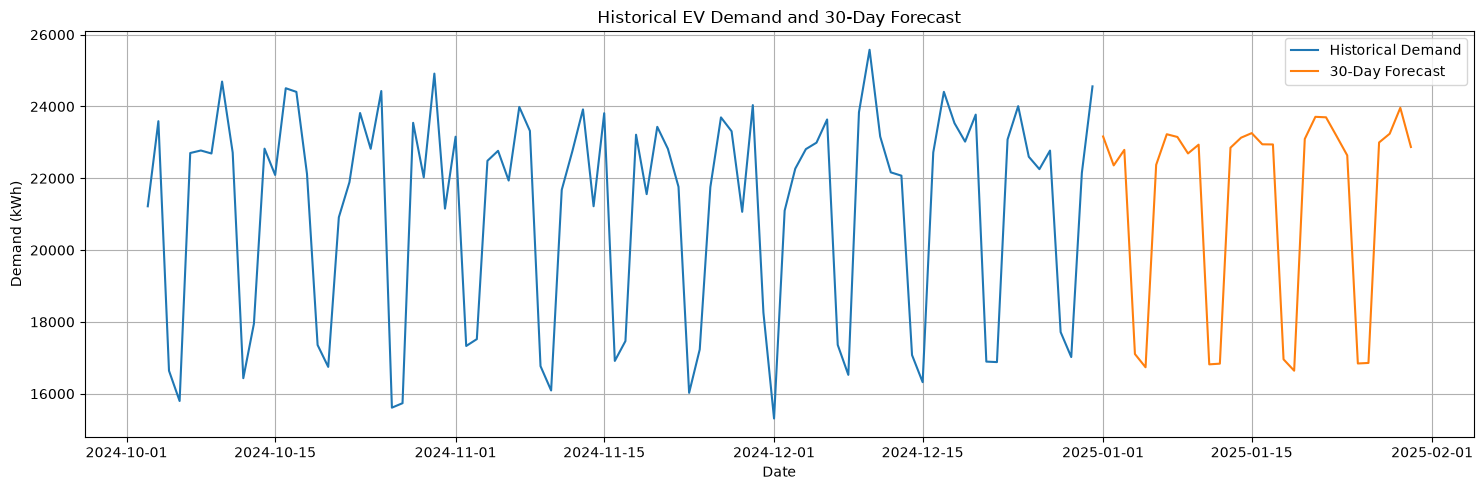

In [82]:
recent_history = daily_data.tail(90)

plt.figure(figsize=(15,5))

plt.plot(
    recent_history["date"],
    recent_history["demand_kwh"],
    label="Historical Demand"
)

plt.plot(
    forecast_30["date"],
    forecast_30["predicted_demand"],
    label="30-Day Forecast"
)

plt.title("Historical EV Demand and 30-Day Forecast")
plt.xlabel("Date")
plt.ylabel("Demand (kWh)")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [83]:
forecast_30.to_csv("forecast_30_days.csv", index=False)
forecast_90.to_csv("forecast_90_days.csv", index=False)
forecast_365.to_csv("forecast_365_days.csv", index=False)

print("Forecast datasets saved successfully!")

Forecast datasets saved successfully!


In [84]:
forecast_summary = pd.DataFrame({
    "Forecast Period": ["30 Days", "90 Days", "365 Days"],
    "Total Demand (kWh)": [
        forecast_30["predicted_demand"].sum(),
        forecast_90["predicted_demand"].sum(),
        forecast_365["predicted_demand"].sum()
    ],
    "Average Daily Demand (kWh)": [
        forecast_30["predicted_demand"].mean(),
        forecast_90["predicted_demand"].mean(),
        forecast_365["predicted_demand"].mean()
    ]
})

forecast_summary

,Forecast Period,Total Demand (kWh),Average Daily Demand (kWh)
0,30 Days,6.420196e+05,21400.652344
1,90 Days,1.907746e+06,21197.179688
2,365 Days,7.723862e+06,21161.263672


In [85]:
historical_dashboard = daily_data.copy()

historical_dashboard.columns = ["date", "demand_kwh"]
historical_dashboard["type"] = "Historical"

future_dashboard = xgb_forecast.copy()

future_dashboard.columns = ["date", "demand_kwh"]
future_dashboard["type"] = "Forecast"

dashboard_data = pd.concat(
    [historical_dashboard, future_dashboard],
    ignore_index=True
)

dashboard_data.head()

,date,demand_kwh,type
0,2022-01-01,5024.4,Historical
1,2022-01-02,3861.3,Historical
2,2022-01-03,6250.3,Historical
3,2022-01-04,5620.4,Historical
4,2022-01-05,6104.1,Historical


In [86]:
dashboard_data.tail()

,date,demand_kwh,type
1456,2025-12-27,16499.666016,Forecast
1457,2025-12-28,16709.175781,Forecast
1458,2025-12-29,23590.009766,Forecast
1459,2025-12-30,22252.080078,Forecast
1460,2025-12-31,22463.103516,Forecast


In [87]:
dashboard_data["type"].value_counts()

type
Historical    1096
Forecast       365
Name: count, dtype: int64

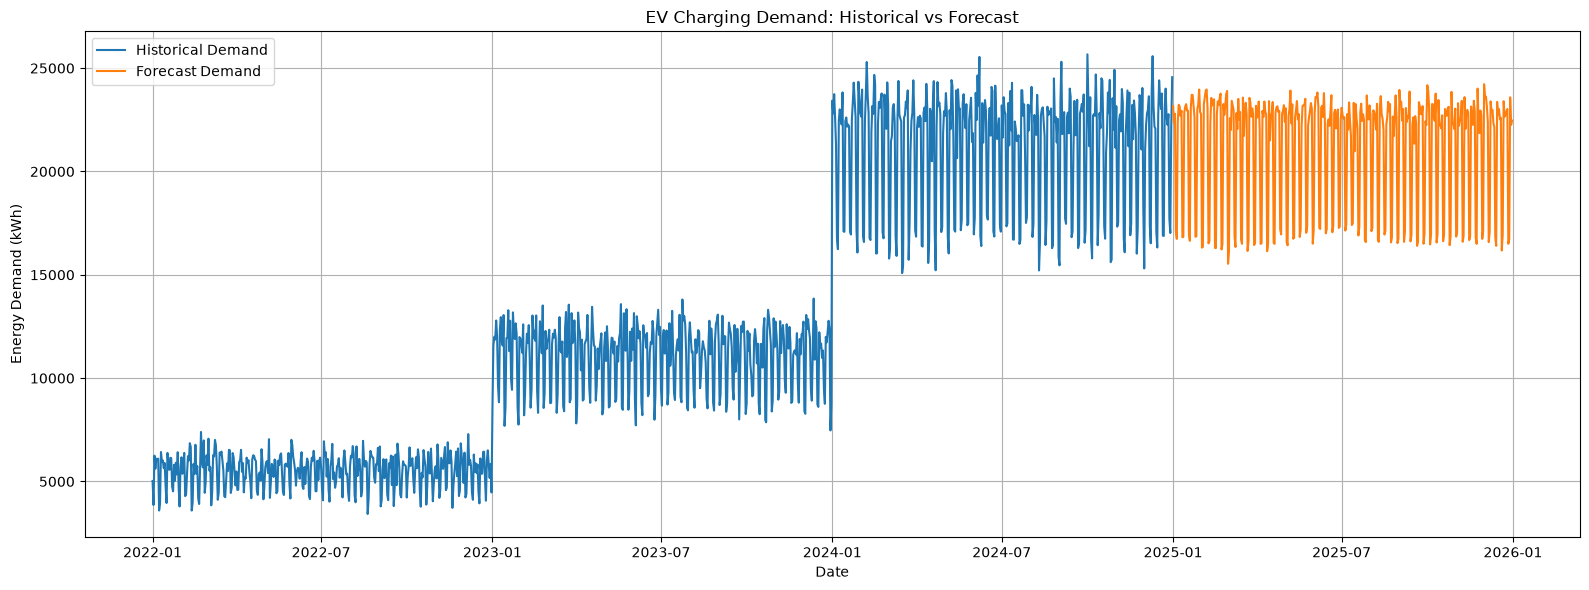

In [88]:
plt.figure(figsize=(16,6))

plt.plot(
    historical_dashboard["date"],
    historical_dashboard["demand_kwh"],
    label="Historical Demand"
)

plt.plot(
    future_dashboard["date"],
    future_dashboard["demand_kwh"],
    label="Forecast Demand"
)

plt.title("EV Charging Demand: Historical vs Forecast")
plt.xlabel("Date")
plt.ylabel("Energy Demand (kWh)")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [89]:
total_historical_demand = daily_data["demand_kwh"].sum()

average_daily_demand = daily_data["demand_kwh"].mean()

peak_daily_demand = daily_data["demand_kwh"].max()

forecast_30_total = forecast_30["predicted_demand"].sum()

forecast_90_total = forecast_90["predicted_demand"].sum()

forecast_365_total = forecast_365["predicted_demand"].sum()

print("Total Historical Demand:", total_historical_demand, "kWh")
print("Average Daily Demand:", average_daily_demand, "kWh")
print("Peak Daily Demand:", peak_daily_demand, "kWh")
print("30-Day Forecast Demand:", forecast_30_total, "kWh")
print("90-Day Forecast Demand:", forecast_90_total, "kWh")
print("365-Day Forecast Demand:", forecast_365_total, "kWh")

Total Historical Demand: 13808745.799999999 kWh
Average Daily Demand: 12599.220620437954 kWh
Peak Daily Demand: 25668.7 kWh
30-Day Forecast Demand: 642019.56 kWh
90-Day Forecast Demand: 1.9077461e+06 kWh
365-Day Forecast Demand: 7.7238615e+06 kWh


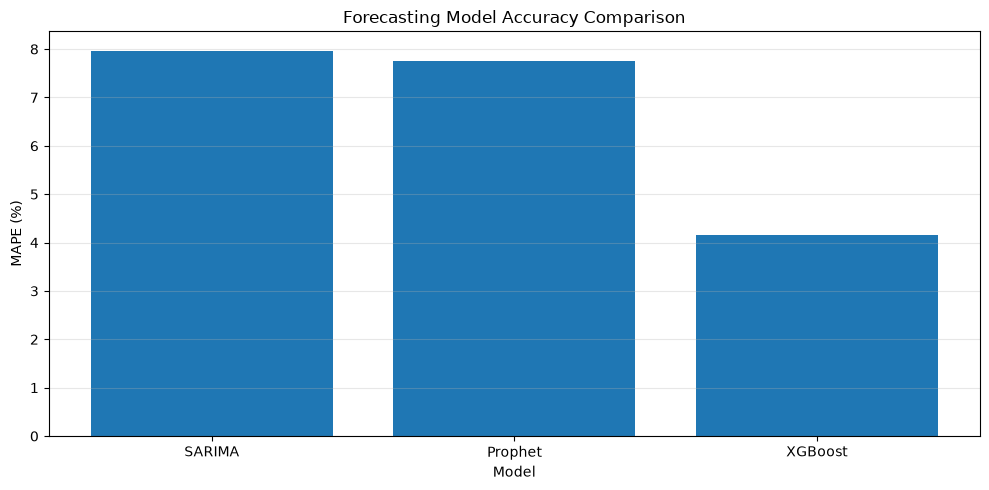

In [90]:
plt.figure(figsize=(10,5))

plt.bar(model_comparison["Model"], model_comparison["MAPE (%)"])

plt.title("Forecasting Model Accuracy Comparison")
plt.xlabel("Model")
plt.ylabel("MAPE (%)")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [91]:
daily_data.to_csv("cleaned_daily_demand.csv", index=False)

model_comparison.to_csv("model_comparison.csv", index=False)

forecast_summary.to_csv("forecast_summary.csv", index=False)

xgb_forecast.to_csv("final_365_day_forecast.csv", index=False)

print("All project datasets saved successfully!")

All project datasets saved successfully!


#### task 2

In [92]:
sessions.head()

,session_id,station_id,charger_id,charger_type,start_timestamp,end_timestamp,session_duration_minutes,energy_kwh,price_per_kwh,total_cost,payment_method,user_type,customer_id,station_region,year,month,day_name,hour
0,S_00000001,STN_001,STN_001_CH_02,DC_150kW,2022-01-01 08:30:00,2022-01-01 08:56:00,26,56.9,0.47,26.74,app,fleet,CUST_00134,North West,2022,1,Saturday,8
1,S_00000002,STN_001,STN_001_CH_02,DC_150kW,2022-01-01 09:20:00,2022-01-01 09:41:00,21,40.7,0.46,18.72,app,delivery,CUST_00195,North West,2022,1,Saturday,9
2,S_00000003,STN_001,STN_001_CH_04,DC_50kW,2022-01-01 09:00:00,2022-01-01 09:48:00,48,30.9,0.47,14.52,rfid,public,CUST_01935,North West,2022,1,Saturday,9
3,S_00000004,STN_001,STN_001_CH_01,DC_50kW,2022-01-01 23:20:00,2022-01-02 00:01:00,41,28.4,0.45,12.78,rfid,public,CUST_00036,North West,2022,1,Saturday,23
4,S_00000005,STN_001,STN_001_CH_01,DC_50kW,2022-01-01 16:10:00,2022-01-01 17:00:00,50,31.7,0.56,17.75,rfid,taxi,CUST_00011,North West,2022,1,Saturday,16


In [93]:
sessions.columns

Index(['session_id', 'station_id', 'charger_id', 'charger_type',
       'start_timestamp', 'end_timestamp', 'session_duration_minutes',
       'energy_kwh', 'price_per_kwh', 'total_cost', 'payment_method',
       'user_type', 'customer_id', 'station_region', 'year', 'month',
       'day_name', 'hour'],
      dtype='str')

In [94]:
sessions['start_timestamp'] = pd.to_datetime(sessions['start_timestamp'])

In [95]:
monthly_data = sessions.groupby(
    sessions['start_timestamp'].dt.to_period('M')
).agg(
    revenue=('total_cost', 'sum'),
    demand=('energy_kwh', 'sum'),
    avg_price=('price_per_kwh', 'mean'),
    sessions=('session_id', 'count')
).reset_index()

monthly_data['start_timestamp'] = monthly_data['start_timestamp'].astype(str)

In [96]:
monthly_data.head()

,start_timestamp,revenue,demand,avg_price,sessions
0,2022-01,85420.18,167166.3,0.510719,3394
1,2022-02,79489.65,155708.9,0.510420,3120
2,2022-03,88864.54,173678.2,0.511567,3497
3,2022-04,83737.74,164041.3,0.510681,3349
4,2022-05,88598.22,172824.0,0.512714,3497


In [97]:
monthly_data.shape

(36, 5)

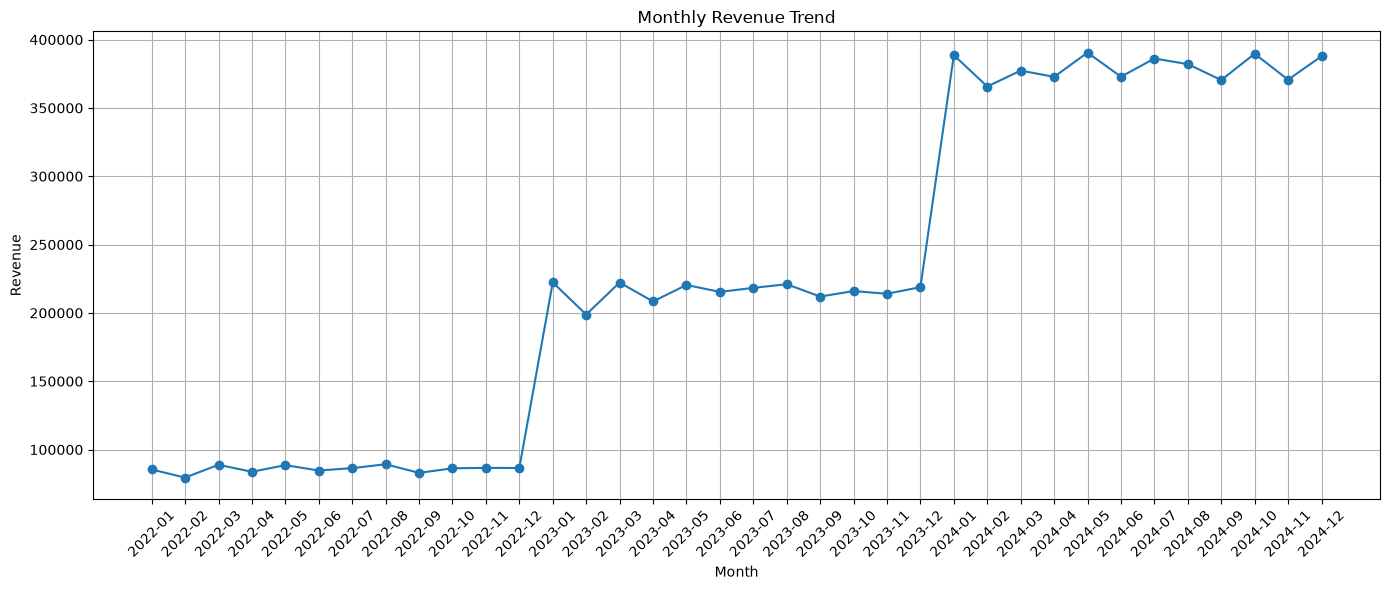

In [98]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))
plt.plot(monthly_data['start_timestamp'], monthly_data['revenue'], marker='o')

plt.title('Monthly Revenue Trend')
plt.xlabel('Month')
plt.ylabel('Revenue')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

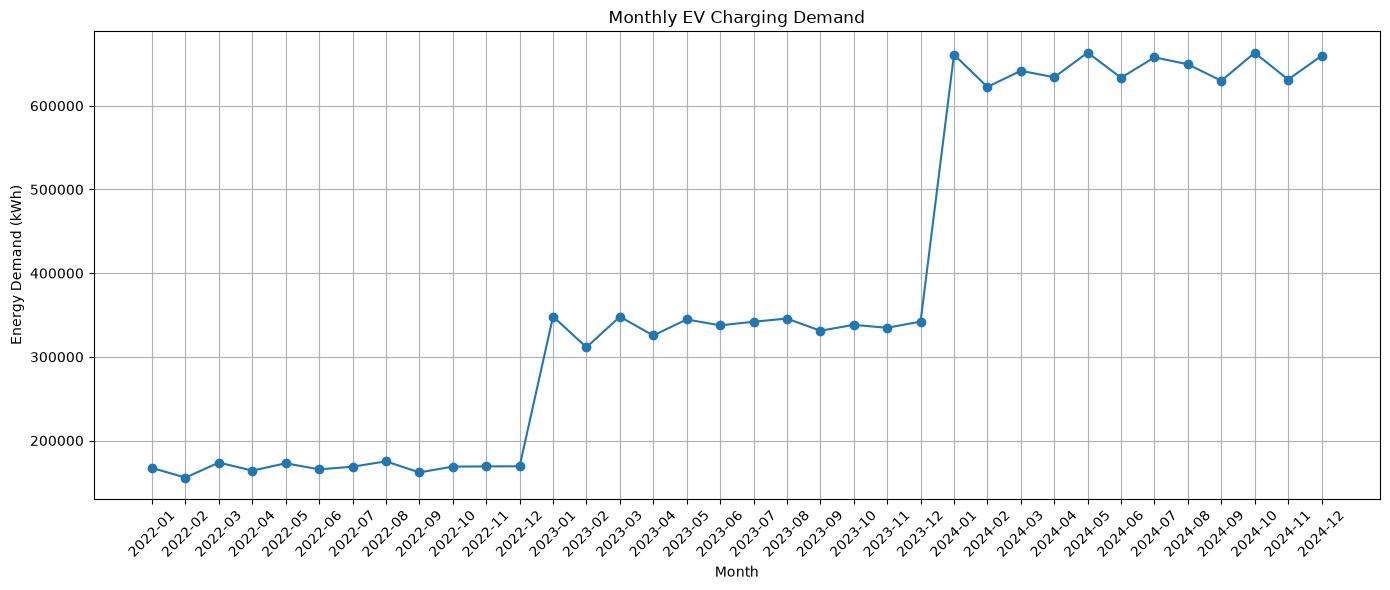

In [99]:
plt.figure(figsize=(14, 6))
plt.plot(monthly_data['start_timestamp'], monthly_data['demand'], marker='o')

plt.title('Monthly EV Charging Demand')
plt.xlabel('Month')
plt.ylabel('Energy Demand (kWh)')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

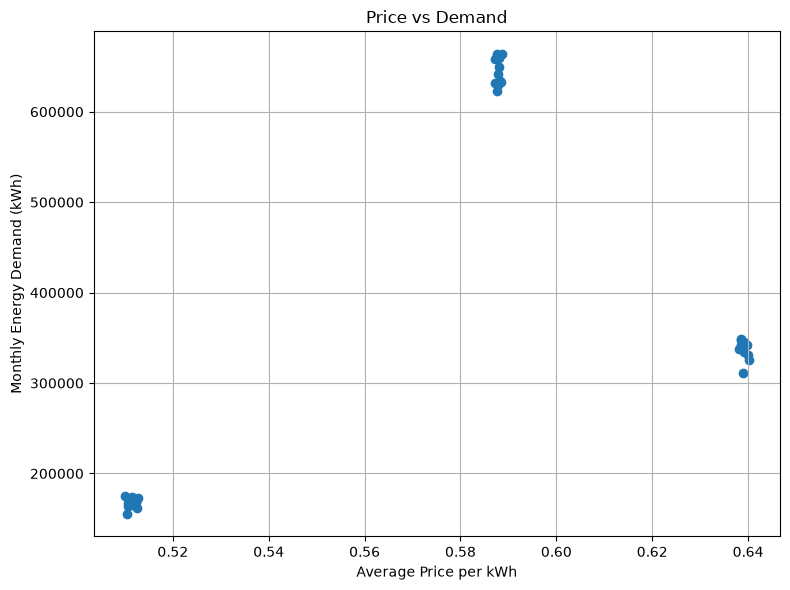

In [100]:
plt.figure(figsize=(8, 6))

plt.scatter(monthly_data['avg_price'], monthly_data['demand'])

plt.title('Price vs Demand')
plt.xlabel('Average Price per kWh')
plt.ylabel('Monthly Energy Demand (kWh)')
plt.grid(True)
plt.tight_layout()
plt.show()

In [101]:
price_demand_corr = monthly_data['avg_price'].corr(monthly_data['demand'])

print("Price-Demand Correlation:", price_demand_corr)

Price-Demand Correlation: 0.45395495528772184


In [102]:
import statsmodels.api as sm

In [103]:
import numpy as np

monthly_data['month_num'] = pd.to_datetime(monthly_data['start_timestamp']).dt.month
monthly_data['time_index'] = range(len(monthly_data))

monthly_data['log_demand'] = np.log(monthly_data['demand'])
monthly_data['log_price'] = np.log(monthly_data['avg_price'])

In [104]:
X = monthly_data[['log_price', 'time_index', 'month_num']]
y = monthly_data['log_demand']

X = sm.add_constant(X)

model = sm.OLS(y, X).fit()

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:             log_demand   R-squared:                       0.997
Model:                            OLS   Adj. R-squared:                  0.997
Method:                 Least Squares   F-statistic:                     4134.
Date:                Sat, 28 Nov 2026   Prob (F-statistic):           1.71e-41
Time:                        17:29:51   Log-Likelihood:                 77.670
No. Observations:                  36   AIC:                            -147.3
Df Residuals:                      32   BIC:                            -141.0
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         12.1847      0.044    278.774      0.0

In [105]:
monthly_data['month'] = pd.to_datetime(
    monthly_data['start_timestamp']
).dt.month

seasonality = pd.get_dummies(
    monthly_data['month'],
    prefix='month',
    drop_first=True,
    dtype=int
)

In [106]:
X = pd.concat(
    [monthly_data[['log_price', 'time_index']], seasonality],
    axis=1
)

y = monthly_data['log_demand']

X = sm.add_constant(X)

model_elasticity = sm.OLS(y, X).fit()

print(model_elasticity.summary())

                            OLS Regression Results                            
Dep. Variable:             log_demand   R-squared:                       1.000
Model:                            OLS   Adj. R-squared:                  0.999
Method:                 Least Squares   F-statistic:                     3678.
Date:                Sat, 28 Nov 2026   Prob (F-statistic):           1.45e-33
Time:                        17:29:51   Log-Likelihood:                 108.67
No. Observations:                  36   AIC:                            -189.3
Df Residuals:                      22   BIC:                            -167.2
Df Model:                          13                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         12.1571      0.024    516.208      0.0

In [107]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

In [108]:
monthly_data['start_timestamp'] = pd.to_datetime(
    monthly_data['start_timestamp']
)

monthly_data = monthly_data.sort_values('start_timestamp')

revenue_series = monthly_data.set_index(
    'start_timestamp'
)['revenue']

revenue_series = revenue_series.asfreq('MS')

In [109]:
forecast_model = ExponentialSmoothing(
    revenue_series,
    trend='add',
    seasonal='add',
    seasonal_periods=12
).fit()

revenue_forecast = forecast_model.forecast(6)

print(revenue_forecast)

2025-01-01    530423.668915
2025-02-01    511154.657362
2025-03-01    533836.169059
2025-04-01    527473.109186
2025-05-01    542608.886834
2025-06-01    534051.083388
Freq: MS, dtype: float64


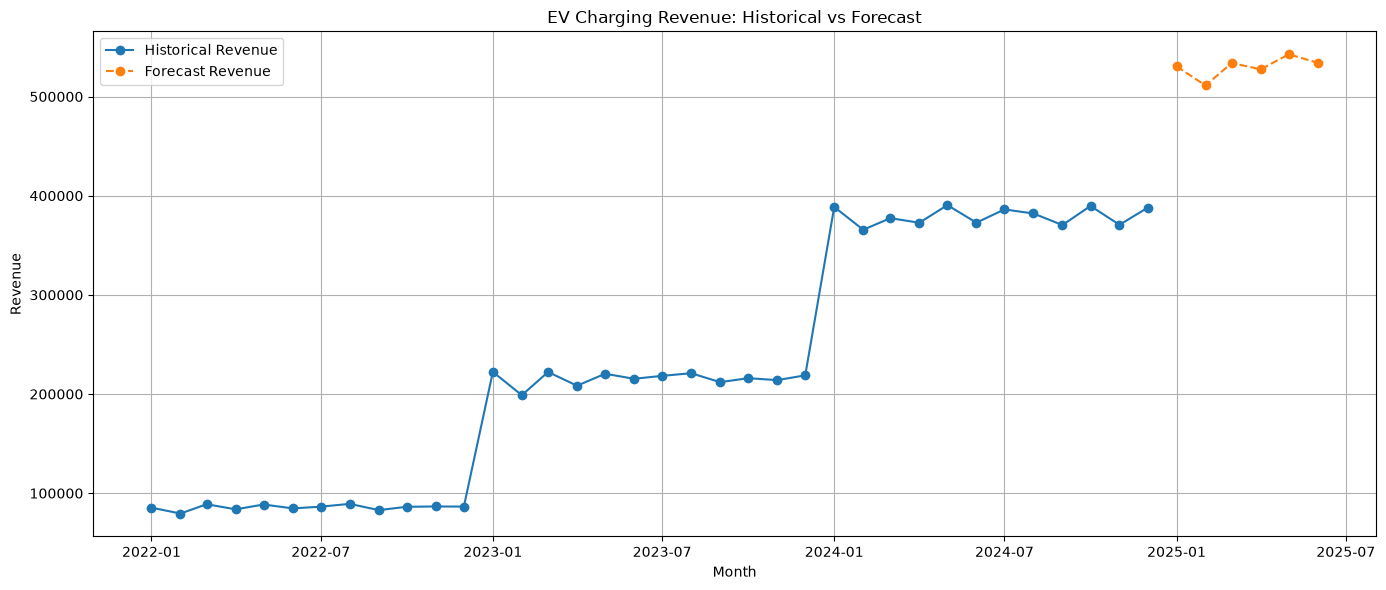

In [110]:
plt.figure(figsize=(14, 6))

plt.plot(
    revenue_series.index,
    revenue_series,
    label='Historical Revenue',
    marker='o'
)

plt.plot(
    revenue_forecast.index,
    revenue_forecast,
    label='Forecast Revenue',
    marker='o',
    linestyle='--'
)

plt.title('EV Charging Revenue: Historical vs Forecast')
plt.xlabel('Month')
plt.ylabel('Revenue')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [111]:
elasticity = model_elasticity.params['log_price']

print("Estimated price elasticity:", elasticity)

Estimated price elasticity: 0.16402101253724047


In [112]:
price_increase = 0.05
price_decrease = -0.10

demand_change_5 = (1 + price_increase)**elasticity - 1
demand_change_10 = (1 + price_decrease)**elasticity - 1

revenue_change_5 = (1 + price_increase) * (1 + demand_change_5) - 1
revenue_change_10 = (1 + price_decrease) * (1 + demand_change_10) - 1

print("Demand change with +5% price:", demand_change_5 * 100, "%")
print("Revenue change with +5% price:", revenue_change_5 * 100, "%")

print("Demand change with -10% price:", demand_change_10 * 100, "%")
print("Revenue change with -10% price:", revenue_change_10 * 100, "%")

Demand change with +5% price: 0.8034718617483838 %
Revenue change with +5% price: 5.8436454548358 %
Demand change with -10% price: -1.7132872590016723 %
Revenue change with -10% price: -11.541958533101504 %


In [113]:
scenario_data = pd.DataFrame({
    'Baseline': revenue_forecast,
    'Price_Increase_5%': revenue_forecast * (1 + revenue_change_5),
    'Price_Decrease_10%': revenue_forecast * (1 + revenue_change_10)
})

print(scenario_data.round(2))


             Baseline  Price_Increase_5%  Price_Decrease_10%
2025-01-01  530423.67          561419.75           469202.39
2025-02-01  511154.66          541024.72           452157.40
2025-03-01  533836.17          565031.66           472221.02
2025-04-01  527473.11          558296.77           466592.38
2025-05-01  542608.89          574317.03           479981.19
2025-06-01  534051.08          565259.14           472411.13


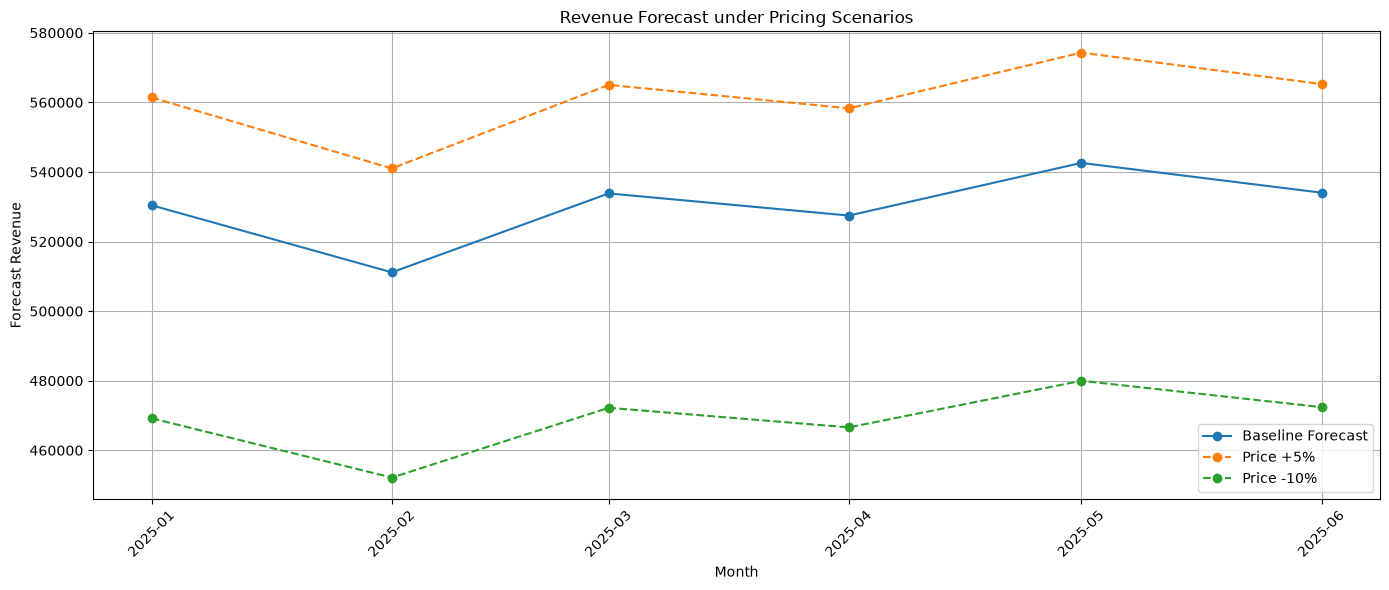

In [114]:
plt.figure(figsize=(14, 6))

plt.plot(scenario_data.index, scenario_data['Baseline'],
         marker='o', label='Baseline Forecast')

plt.plot(scenario_data.index, scenario_data['Price_Increase_5%'],
         marker='o', linestyle='--', label='Price +5%')

plt.plot(scenario_data.index, scenario_data['Price_Decrease_10%'],
         marker='o', linestyle='--', label='Price -10%')

plt.title('Revenue Forecast under Pricing Scenarios')
plt.xlabel('Month')
plt.ylabel('Forecast Revenue')
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [115]:
print("===== REVENUE FORECASTING & PRICE SENSITIVITY =====")

print("\nEstimated Price Elasticity:", round(elasticity, 4))

print("\nRevenue Impact of 5% Price Increase:",
      round(revenue_change_5 * 100, 2), "%")

print("Revenue Impact of 10% Price Decrease:",
      round(revenue_change_10 * 100, 2), "%")

print("\nAverage Baseline Forecast Revenue:",
      round(revenue_forecast.mean(), 2))

print("\nAverage Revenue with 5% Price Increase:",
      round(scenario_data['Price_Increase_5%'].mean(), 2))

print("\nAverage Revenue with 10% Price Decrease:",
      round(scenario_data['Price_Decrease_10%'].mean(), 2))

===== REVENUE FORECASTING & PRICE SENSITIVITY =====

Estimated Price Elasticity: 0.164

Revenue Impact of 5% Price Increase: 5.84 %
Revenue Impact of 10% Price Decrease: -11.54 %

Average Baseline Forecast Revenue: 529924.6

Average Revenue with 5% Price Increase: 560891.51

Average Revenue with 10% Price Decrease: 468760.92


## Executive Summary: Revenue Forecasting & Price Sensitivity

This project analyzed EV charging revenue trends, demand patterns, and pricing sensitivity using charging-session data from 2022 to 2024. Monthly revenue and energy demand were aggregated to examine historical performance, and a time-series model was used to forecast revenue for the next six months (January–June 2025).

The price sensitivity analysis estimated a price elasticity of **0.164**, indicating a positive association between price and demand in the dataset. However, this relationship should not be interpreted as causal, as the analysis is based on observational data and a relatively small monthly sample.

A seasonal forecasting model estimated average monthly baseline revenue of approximately **529,924.60** for the forecast period.

Scenario simulations indicated:
- **5% price increase:** Estimated revenue increase of **5.84%**, with average forecast revenue of approximately **560,891.51**.
- **10% price decrease:** Estimated revenue decrease of **11.54%**, with average forecast revenue of approximately **468,760.92**.

The results suggest that, under the model's assumptions, a 5% price increase could potentially improve revenue. However, the estimated positive demand elasticity is unusual and may reflect market growth, seasonal patterns, or other factors rather than customers responding positively to higher prices.

### Conclusion
The analysis demonstrates how time-series forecasting and scenario modeling can support revenue planning and pricing decisions in the EV charging industry. While the simulated 5% price increase produced the highest projected revenue, real-world pricing decisions should consider customer behavior, competition, charging utilization, and further validation of the elasticity model.

#### Task 3

In [116]:
sessions.columns

Index(['session_id', 'station_id', 'charger_id', 'charger_type',
       'start_timestamp', 'end_timestamp', 'session_duration_minutes',
       'energy_kwh', 'price_per_kwh', 'total_cost', 'payment_method',
       'user_type', 'customer_id', 'station_region', 'year', 'month',
       'day_name', 'hour'],
      dtype='str')

In [117]:
sessions['start_timestamp'] = pd.to_datetime(sessions['start_timestamp'])
sessions['end_timestamp'] = pd.to_datetime(sessions['end_timestamp'])

sessions['session_duration_minutes'] = pd.to_numeric(
    sessions['session_duration_minutes'], errors='coerce'
)

print("Data types updated successfully!")
print(sessions[['start_timestamp', 'end_timestamp',
                'session_duration_minutes']].dtypes)

Data types updated successfully!
start_timestamp             datetime64[us]
end_timestamp               datetime64[us]
session_duration_minutes             int64
dtype: object


In [118]:
print("Missing values:")
print(sessions[['charger_id', 'station_id', 'start_timestamp',
                'end_timestamp', 'session_duration_minutes']].isnull().sum())

print("\nNegative session durations:",
      (sessions['session_duration_minutes'] < 0).sum())

print("\nZero session durations:",
      (sessions['session_duration_minutes'] == 0).sum())

print("\nDuplicate session IDs:",
      sessions['session_id'].duplicated().sum())

Missing values:
charger_id                  0
station_id                  0
start_timestamp             0
end_timestamp               0
session_duration_minutes    0
dtype: int64

Negative session durations: 0

Zero session durations: 0

Duplicate session IDs: 0


In [119]:
observation_days = (
    sessions['end_timestamp'].max() - sessions['start_timestamp'].min()
).days

observation_hours = observation_days * 24

charger_utilisation = sessions.groupby('charger_id').agg(
    total_charging_hours=('session_duration_minutes',
                         lambda x: x.sum() / 60),
    total_sessions=('session_id', 'count'),
    total_energy=('energy_kwh', 'sum'),
    avg_session_duration=('session_duration_minutes', 'mean')
).reset_index()

charger_utilisation['utilisation_rate'] = (
    charger_utilisation['total_charging_hours'] / observation_hours
) * 100

charger_utilisation.head()

,charger_id,total_charging_hours,total_sessions,total_energy,avg_session_duration,utilisation_rate
0,STN_001_CH_01,3080.983333,3731,123295.5,49.546770,11.723681
1,STN_001_CH_02,1509.833333,3706,181117.4,24.444145,5.745180
2,STN_001_CH_03,1580.550000,3877,189580.8,24.460408,6.014269
3,STN_001_CH_04,3172.466667,3848,126957.9,49.466736,12.071791
4,STN_002_CH_01,2542.650000,3084,101707.9,49.467899,9.675228


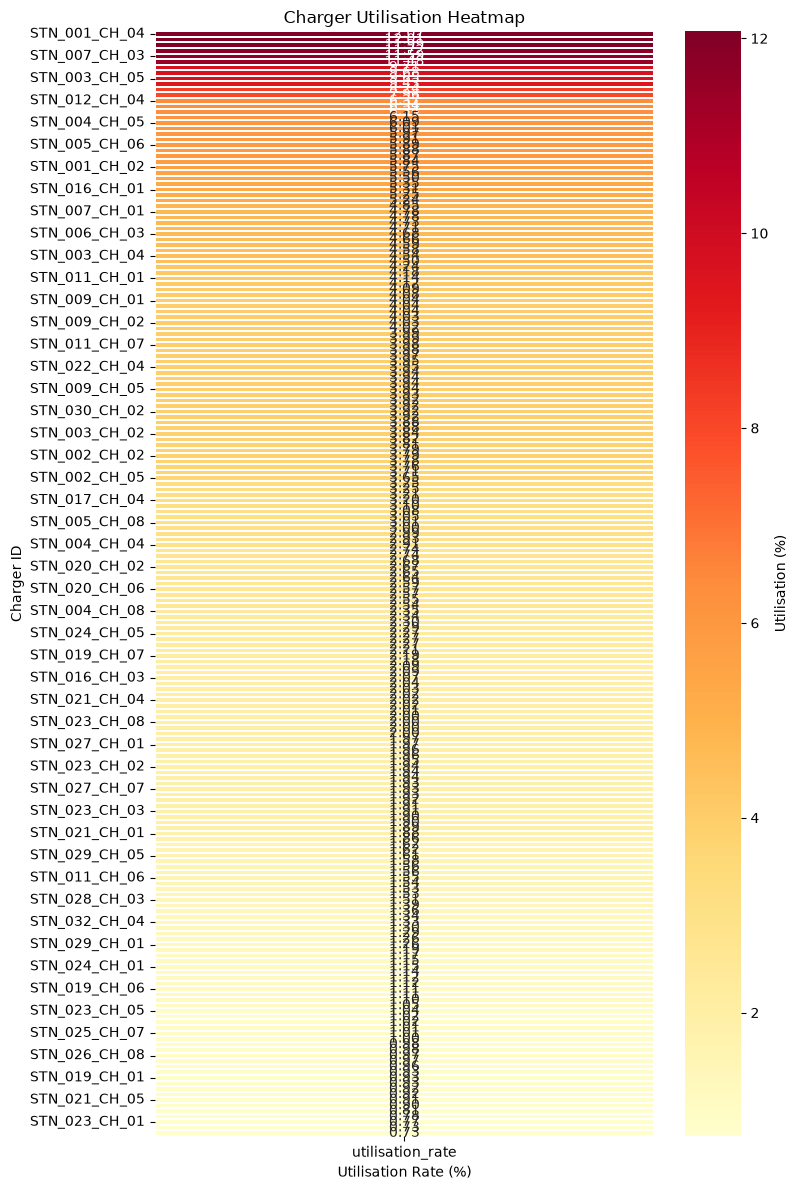

In [120]:
import seaborn as sns
import matplotlib.pyplot as plt

util_heatmap = charger_utilisation.set_index('charger_id')[
    ['utilisation_rate']
].sort_values('utilisation_rate', ascending=False)

plt.figure(figsize=(8, 12))

sns.heatmap(
    util_heatmap,
    annot=True,
    fmt='.2f',
    cmap='YlOrRd',
    linewidths=0.3,
    cbar_kws={'label': 'Utilisation (%)'}
)

plt.title('Charger Utilisation Heatmap')
plt.xlabel('Utilisation Rate (%)')
plt.ylabel('Charger ID')
plt.tight_layout()
plt.show()

In [121]:
station_utilisation = sessions.groupby('station_id').agg(
    total_sessions=('session_id', 'count'),
    total_energy=('energy_kwh', 'sum'),
    total_charging_hours=('session_duration_minutes',
                         lambda x: x.sum() / 60)
).reset_index()

station_utilisation['utilisation_rate'] = (
    station_utilisation['total_charging_hours'] / observation_hours
) * 100

station_utilisation = station_utilisation.sort_values(
    'utilisation_rate', ascending=False
)

station_utilisation.head(10)

,station_id,total_sessions,total_energy,total_charging_hours,utilisation_rate
6,STN_007,15218,666315.7,10611.350000,40.378044
0,STN_001,15162,620951.6,9343.833333,35.554921
3,STN_004,15121,720723.5,9008.316667,34.278222
2,STN_003,15321,733802.6,8564.966667,32.591197
4,STN_005,15160,702048.5,8383.633333,31.901192
8,STN_009,10159,335024.2,8382.666667,31.897514
15,STN_016,10170,406923.6,7549.833333,28.728437
5,STN_006,15045,778478.1,7351.133333,27.972349
7,STN_008,15154,854549.0,6928.700000,26.364916
1,STN_002,15276,940999.0,6756.683333,25.710363


C:\Users\pranjali sharma\AppData\Local\Temp\ipykernel_10168\3545175022.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


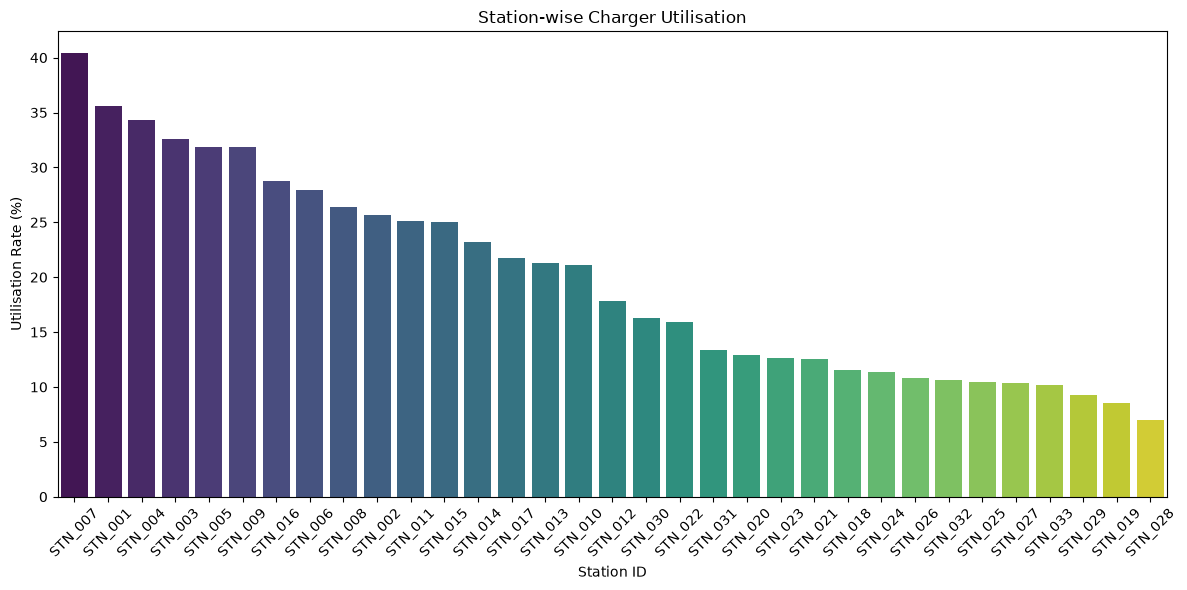

In [122]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))

sns.barplot(
    data=station_utilisation,
    x='station_id',
    y='utilisation_rate',
    order=station_utilisation['station_id'],
    palette='viridis'
)

plt.title('Station-wise Charger Utilisation')
plt.xlabel('Station ID')
plt.ylabel('Utilisation Rate (%)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [123]:
sessions = sessions.sort_values(['charger_id', 'start_timestamp'])

sessions['next_session_start'] = (
    sessions.groupby('charger_id')['start_timestamp'].shift(-1)
)

sessions['idle_minutes'] = (
    sessions['next_session_start'] - sessions['end_timestamp']
).dt.total_seconds() / 60

idle_analysis = sessions.dropna(subset=['idle_minutes']).copy()

idle_analysis = idle_analysis[idle_analysis['idle_minutes'] >= 0]

idle_summary = idle_analysis.groupby('charger_id').agg(
    avg_idle_minutes=('idle_minutes', 'mean'),
    total_idle_hours=('idle_minutes', lambda x: x.sum() / 60),
    idle_intervals=('idle_minutes', 'count')
).reset_index()

idle_summary.head()

,charger_id,avg_idle_minutes,total_idle_hours,idle_intervals
0,STN_001_CH_01,447.401780,23458.766667,3146
1,STN_001_CH_02,440.817617,24854.766667,3383
2,STN_001_CH_03,418.085795,24771.583333,3555
3,STN_001_CH_04,434.313622,23380.550000,3230
4,STN_002_CH_01,529.880089,23862.266667,2702


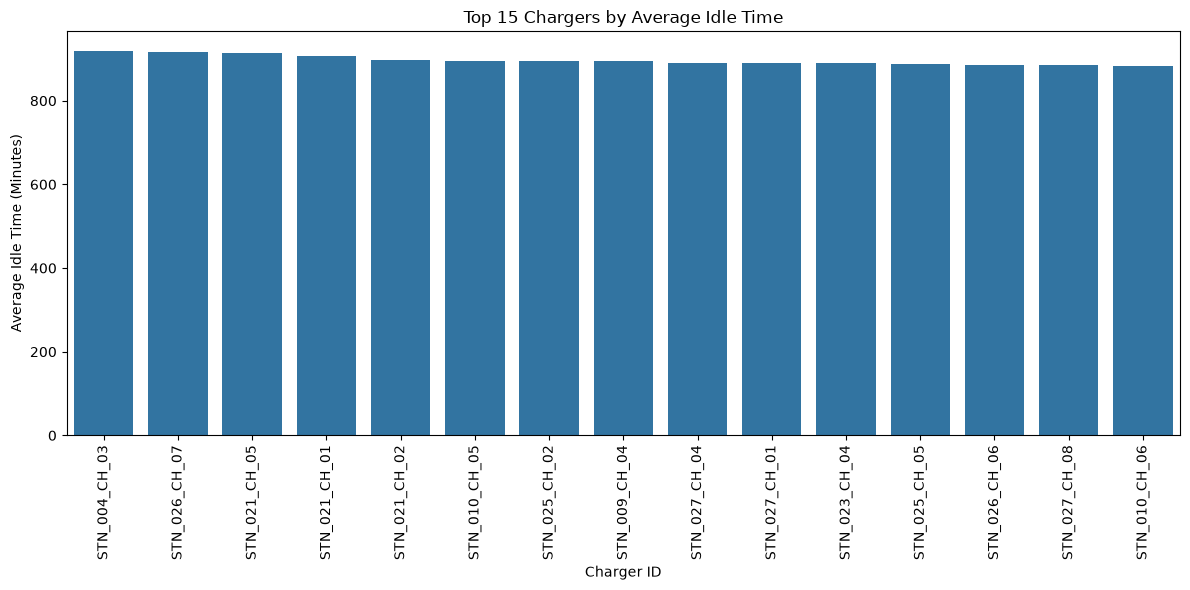

In [124]:
idle_top = idle_summary.sort_values(
    'avg_idle_minutes', ascending=False
).head(15)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=idle_top,
    x='charger_id',
    y='avg_idle_minutes'
)

plt.title('Top 15 Chargers by Average Idle Time')
plt.xlabel('Charger ID')
plt.ylabel('Average Idle Time (Minutes)')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

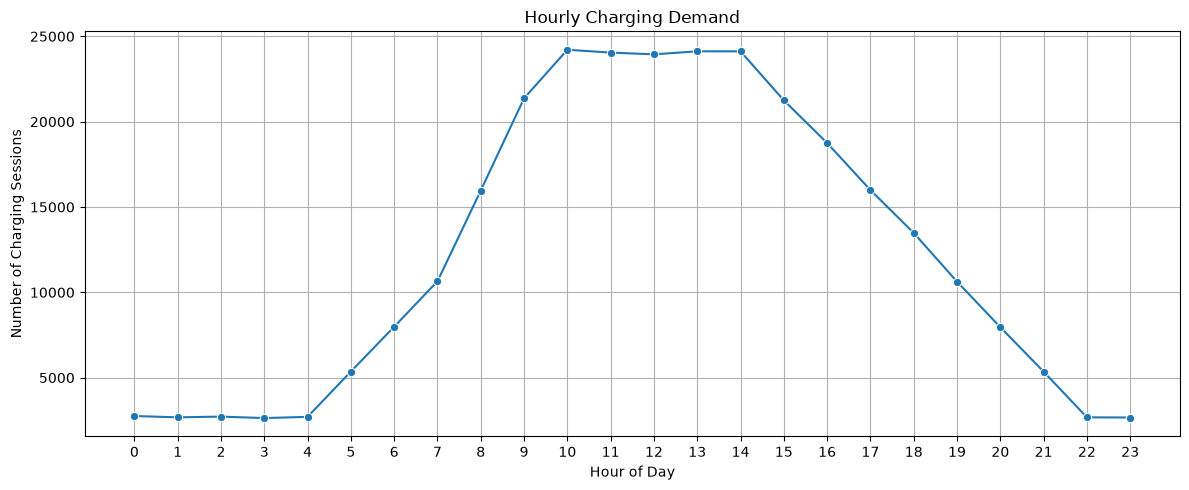

In [125]:
sessions['hour'] = sessions['start_timestamp'].dt.hour

hourly_demand = sessions.groupby('hour').agg(
    total_sessions=('session_id', 'count'),
    total_energy=('energy_kwh', 'sum')
).reset_index()

plt.figure(figsize=(12, 5))

sns.lineplot(
    data=hourly_demand,
    x='hour',
    y='total_sessions',
    marker='o'
)

plt.title('Hourly Charging Demand')
plt.xlabel('Hour of Day')
plt.ylabel('Number of Charging Sessions')
plt.xticks(range(24))
plt.grid(True)
plt.tight_layout()
plt.show()

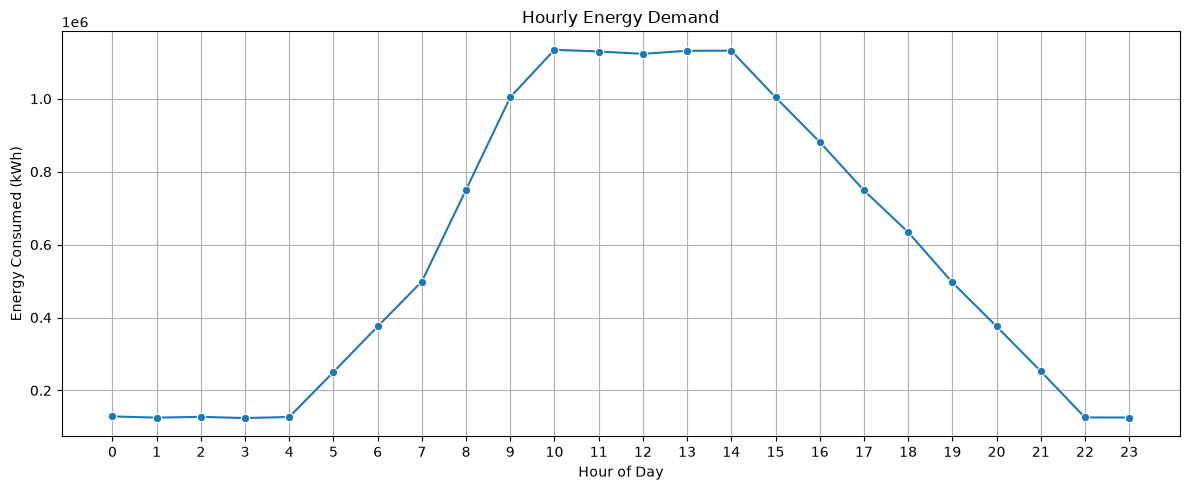

In [126]:
plt.figure(figsize=(12, 5))

sns.lineplot(
    data=hourly_demand,
    x='hour',
    y='total_energy',
    marker='o'
)

plt.title('Hourly Energy Demand')
plt.xlabel('Hour of Day')
plt.ylabel('Energy Consumed (kWh)')
plt.xticks(range(24))
plt.grid(True)
plt.tight_layout()
plt.show()

In [127]:
top_chargers = charger_utilisation.sort_values(
    'utilisation_rate', ascending=False
).head(10)

top_chargers[
    ['charger_id', 'total_sessions', 'total_energy',
     'total_charging_hours', 'utilisation_rate']
]

,charger_id,total_sessions,total_energy,total_charging_hours,utilisation_rate
3,STN_001_CH_04,3848,126957.9,3172.466667,12.071791
35,STN_007_CH_02,3839,126245.6,3157.250000,12.013889
37,STN_007_CH_04,3817,126216.4,3150.850000,11.989536
0,STN_001_CH_01,3731,123295.5,3080.983333,11.723681
36,STN_007_CH_03,3697,121755.3,3047.150000,11.594939
33,STN_006_CH_04,3662,120353.7,3018.250000,11.484970
9,STN_003_CH_01,3101,102133.1,2552.550000,9.712900
4,STN_002_CH_01,3084,101707.9,2542.650000,9.675228
13,STN_003_CH_05,3081,101451.6,2536.850000,9.653158
38,STN_008_CH_01,3003,99249.3,2478.800000,9.432268


In [128]:
low_chargers = charger_utilisation.sort_values(
    'utilisation_rate', ascending=True
).head(10)

low_chargers[
    ['charger_id', 'total_sessions', 'total_energy',
     'total_charging_hours', 'utilisation_rate']
]

,charger_id,total_sessions,total_energy,total_charging_hours,utilisation_rate
147,STN_025_CH_02,598,44921.5,192.650000,0.733067
165,STN_027_CH_04,593,44932.8,193.150000,0.734970
131,STN_023_CH_01,620,46923.8,201.716667,0.767567
148,STN_025_CH_03,632,47575.4,204.700000,0.778919
167,STN_027_CH_06,658,49630.2,213.283333,0.811580
109,STN_019_CH_04,726,54771.6,235.566667,0.896372
123,STN_021_CH_05,586,28587.7,238.766667,0.908549
160,STN_026_CH_07,590,28945.9,240.700000,0.915906
151,STN_025_CH_06,596,29034.1,242.800000,0.923896
120,STN_021_CH_02,594,29080.7,243.600000,0.926941


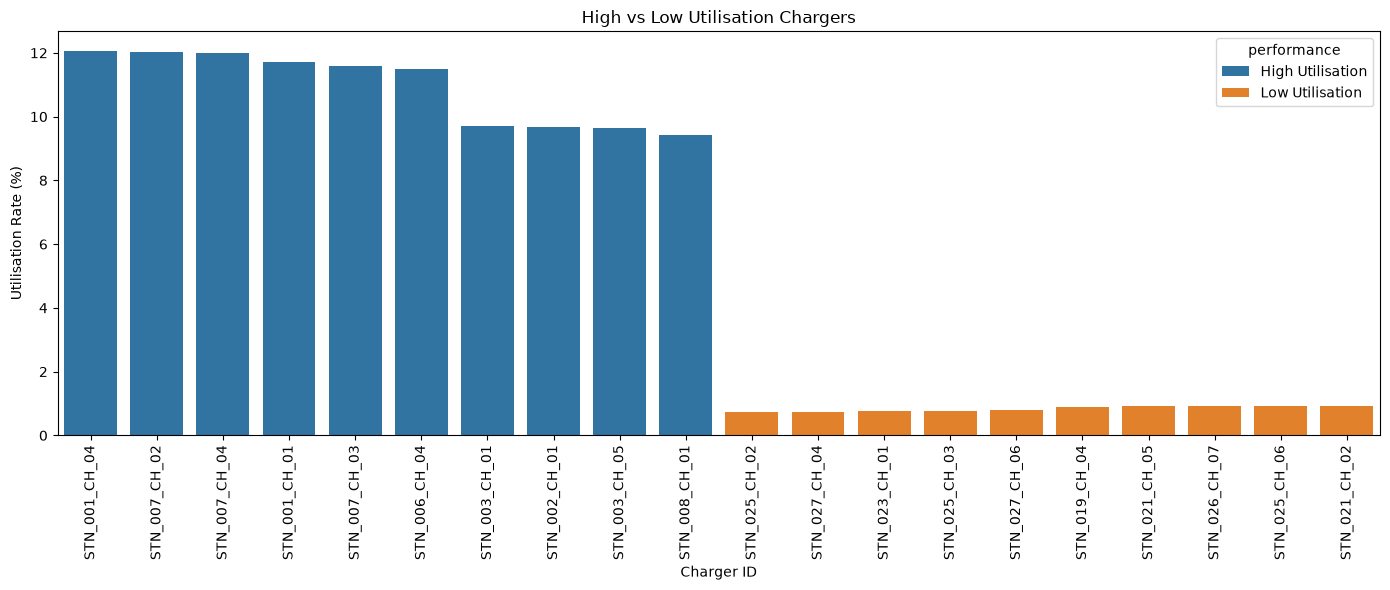

In [129]:
comparison = pd.concat([
    top_chargers.assign(performance='High Utilisation'),
    low_chargers.assign(performance='Low Utilisation')
])

plt.figure(figsize=(14, 6))

sns.barplot(
    data=comparison,
    x='charger_id',
    y='utilisation_rate',
    hue='performance'
)

plt.title('High vs Low Utilisation Chargers')
plt.xlabel('Charger ID')
plt.ylabel('Utilisation Rate (%)')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

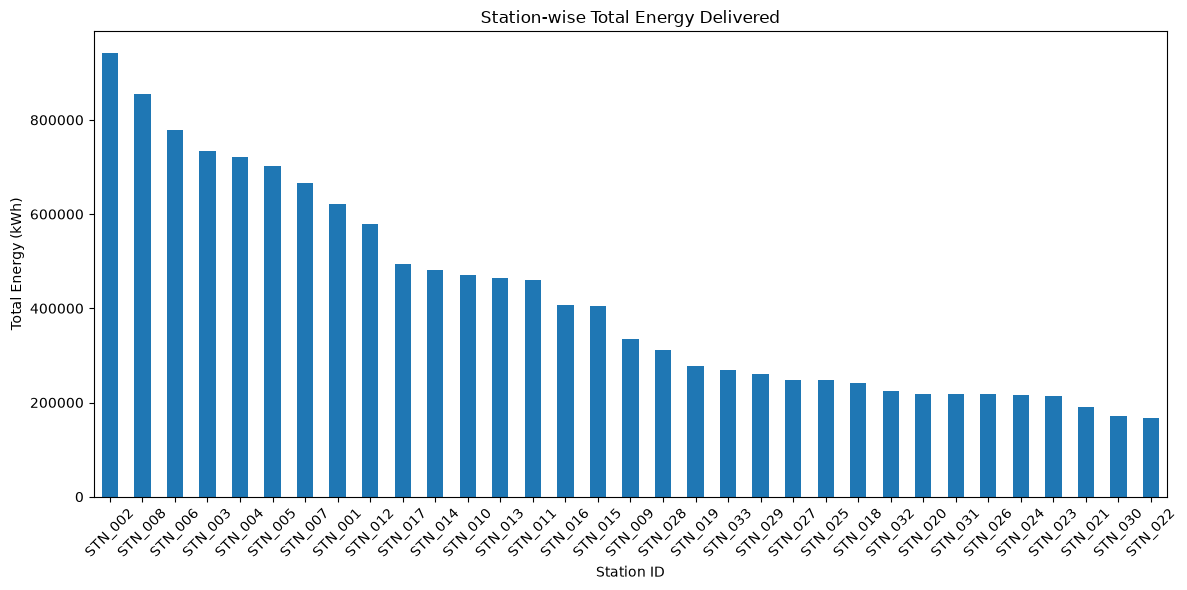

In [130]:
station_energy = sessions.groupby('station_id')['energy_kwh'].sum().sort_values(ascending=False)

plt.figure(figsize=(12, 6))

station_energy.plot(kind='bar')

plt.title('Station-wise Total Energy Delivered')
plt.xlabel('Station ID')
plt.ylabel('Total Energy (kWh)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [131]:
sessions['customer_id'].isnull().sum()

np.int64(0)

In [132]:
sessions['customer_id'].nunique()

8000

In [133]:
sessions['user_type'].value_counts(dropna=False)

user_type
public      73754
fleet       73696
delivery    73339
taxi        73235
Name: count, dtype: int64

In [134]:
customer_data = sessions.groupby('customer_id').agg(
    total_sessions=('session_id', 'count'),
    total_energy=('energy_kwh', 'sum'),
    total_revenue=('total_cost', 'sum'),
    avg_session_duration=('session_duration_minutes', 'mean'),
    avg_energy_per_session=('energy_kwh', 'mean'),
    avg_cost_per_session=('total_cost', 'mean'),
    unique_stations=('station_id', 'nunique'),
    unique_chargers=('charger_id', 'nunique')
).reset_index()

In [135]:
customer_data.head()

,customer_id,total_sessions,total_energy,total_revenue,avg_session_duration,avg_energy_per_session,avg_cost_per_session,unique_stations,unique_chargers
0,CUST_00001,267,12299.8,7257.86,35.179775,46.066667,27.182996,33,135
1,CUST_00002,243,11619.2,6784.02,34.419753,47.815638,27.917778,33,128
2,CUST_00003,282,13163.2,7819.69,35.574468,46.678014,27.729397,33,146
3,CUST_00004,253,12144.4,7122.30,34.043478,48.001581,28.151383,33,128
4,CUST_00005,246,11713.1,6882.25,35.313008,47.614228,27.976626,32,126


In [136]:
sessions['start_timestamp'] = pd.to_datetime(sessions['start_timestamp'])

sessions['hour'] = sessions['start_timestamp'].dt.hour
sessions['day'] = sessions['start_timestamp'].dt.day
sessions['weekday'] = sessions['start_timestamp'].dt.dayofweek
sessions['month'] = sessions['start_timestamp'].dt.month

In [137]:
time_features = sessions.groupby('customer_id').agg(
    avg_charging_hour=('hour', 'mean'),
    avg_charging_day=('weekday', 'mean'),
    active_months=('month', 'nunique')
).reset_index()

In [138]:
customer_data = customer_data.merge(time_features, on='customer_id', how='left')

In [139]:
customer_data.head()

,customer_id,total_sessions,total_energy,total_revenue,avg_session_duration,avg_energy_per_session,avg_cost_per_session,unique_stations,unique_chargers,avg_charging_hour,avg_charging_day,active_months
0,CUST_00001,267,12299.8,7257.86,35.179775,46.066667,27.182996,33,135,11.883895,2.846442,12
1,CUST_00002,243,11619.2,6784.02,34.419753,47.815638,27.917778,33,128,12.534979,2.925926,12
2,CUST_00003,282,13163.2,7819.69,35.574468,46.678014,27.729397,33,146,12.851064,2.776596,12
3,CUST_00004,253,12144.4,7122.30,34.043478,48.001581,28.151383,33,128,12.790514,2.853755,12
4,CUST_00005,246,11713.1,6882.25,35.313008,47.614228,27.976626,32,126,12.398374,2.910569,12


In [140]:
preferred_station = sessions.groupby('customer_id')['station_id'].agg(
    lambda x: x.mode()[0]
).reset_index()

preferred_station.columns = ['customer_id', 'preferred_station']

In [141]:
customer_data = customer_data.merge(preferred_station, on='customer_id', how='left')

In [142]:
customer_data.head()

,customer_id,total_sessions,total_energy,total_revenue,avg_session_duration,avg_energy_per_session,avg_cost_per_session,unique_stations,unique_chargers,avg_charging_hour,avg_charging_day,active_months,preferred_station
0,CUST_00001,267,12299.8,7257.86,35.179775,46.066667,27.182996,33,135,11.883895,2.846442,12,STN_008
1,CUST_00002,243,11619.2,6784.02,34.419753,47.815638,27.917778,33,128,12.534979,2.925926,12,STN_002
2,CUST_00003,282,13163.2,7819.69,35.574468,46.678014,27.729397,33,146,12.851064,2.776596,12,STN_007
3,CUST_00004,253,12144.4,7122.30,34.043478,48.001581,28.151383,33,128,12.790514,2.853755,12,STN_008
4,CUST_00005,246,11713.1,6882.25,35.313008,47.614228,27.976626,32,126,12.398374,2.910569,12,STN_002


In [143]:
customer_type = sessions.groupby('customer_id')['user_type'].agg(
    lambda x: x.mode()[0]
).reset_index()

customer_type.columns = ['customer_id', 'customer_type']

In [144]:
customer_data = customer_data.merge(customer_type, on='customer_id', how='left')

In [145]:
customer_data.head()

,customer_id,total_sessions,total_energy,total_revenue,avg_session_duration,avg_energy_per_session,avg_cost_per_session,unique_stations,unique_chargers,avg_charging_hour,avg_charging_day,active_months,preferred_station,customer_type
0,CUST_00001,267,12299.8,7257.86,35.179775,46.066667,27.182996,33,135,11.883895,2.846442,12,STN_008,taxi
1,CUST_00002,243,11619.2,6784.02,34.419753,47.815638,27.917778,33,128,12.534979,2.925926,12,STN_002,delivery
2,CUST_00003,282,13163.2,7819.69,35.574468,46.678014,27.729397,33,146,12.851064,2.776596,12,STN_007,public
3,CUST_00004,253,12144.4,7122.30,34.043478,48.001581,28.151383,33,128,12.790514,2.853755,12,STN_008,public
4,CUST_00005,246,11713.1,6882.25,35.313008,47.614228,27.976626,32,126,12.398374,2.910569,12,STN_002,public


In [146]:
customer_data.to_csv("customer_behaviour_features.csv", index=False)

In [147]:
customer_data.shape

(8000, 14)

In [148]:
customer_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   customer_id             8000 non-null   str    
 1   total_sessions          8000 non-null   int64  
 2   total_energy            8000 non-null   float64
 3   total_revenue           8000 non-null   float64
 4   avg_session_duration    8000 non-null   float64
 5   avg_energy_per_session  8000 non-null   float64
 6   avg_cost_per_session    8000 non-null   float64
 7   unique_stations         8000 non-null   int64  
 8   unique_chargers         8000 non-null   int64  
 9   avg_charging_hour       8000 non-null   float64
 10  avg_charging_day        8000 non-null   float64
 11  active_months           8000 non-null   int64  
 12  preferred_station       8000 non-null   str    
 13  customer_type           8000 non-null   str    
dtypes: float64(7), int64(4), str(3)
memory usage: 1.0 M

In [149]:
features = customer_data[
    [
        'total_sessions',
        'total_energy',
        'total_revenue',
        'avg_session_duration',
        'avg_energy_per_session',
        'avg_cost_per_session',
        'unique_stations',
        'unique_chargers',
        'avg_charging_hour',
        'avg_charging_day',
        'active_months'
    ]
]

In [150]:
features.head()

,total_sessions,total_energy,total_revenue,avg_session_duration,avg_energy_per_session,avg_cost_per_session,unique_stations,unique_chargers,avg_charging_hour,avg_charging_day,active_months
0,267,12299.8,7257.86,35.179775,46.066667,27.182996,33,135,11.883895,2.846442,12
1,243,11619.2,6784.02,34.419753,47.815638,27.917778,33,128,12.534979,2.925926,12
2,282,13163.2,7819.69,35.574468,46.678014,27.729397,33,146,12.851064,2.776596,12
3,253,12144.4,7122.30,34.043478,48.001581,28.151383,33,128,12.790514,2.853755,12
4,246,11713.1,6882.25,35.313008,47.614228,27.976626,32,126,12.398374,2.910569,12


In [151]:
features.shape

(8000, 11)

In [152]:
from sklearn.preprocessing import StandardScaler

In [153]:
scaler = StandardScaler()

scaled_features = scaler.fit_transform(features)

In [154]:
scaled_features.shape

(8000, 11)

In [155]:
from sklearn.cluster import KMeans

In [156]:
inertia = []

for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(scaled_features)
    inertia.append(kmeans.inertia_)

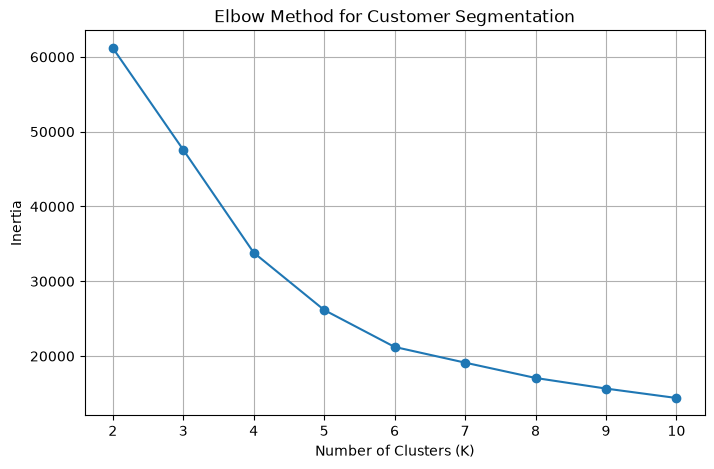

In [157]:
plt.figure(figsize=(8, 5))

plt.plot(range(2, 11), inertia, marker='o')

plt.title('Elbow Method for Customer Segmentation')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.grid(True)

plt.show()

In [158]:
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)

customer_data['cluster'] = kmeans.fit_predict(scaled_features)

In [159]:
customer_data[['customer_id', 'cluster']].head()

,customer_id,cluster
0,CUST_00001,2
1,CUST_00002,2
2,CUST_00003,2
3,CUST_00004,2
4,CUST_00005,2


In [160]:
customer_data['cluster'].value_counts().sort_index()

cluster
0    5549
1     790
2     400
3    1261
Name: count, dtype: int64

In [161]:
cluster_analysis = customer_data.groupby('cluster').agg(
    customers=('customer_id', 'count'),
    total_sessions=('total_sessions', 'mean'),
    total_energy=('total_energy', 'mean'),
    total_revenue=('total_revenue', 'mean'),
    avg_session_duration=('avg_session_duration', 'mean'),
    avg_energy_per_session=('avg_energy_per_session', 'mean'),
    avg_cost_per_session=('avg_cost_per_session', 'mean'),
    unique_stations=('unique_stations', 'mean'),
    unique_chargers=('unique_chargers', 'mean'),
    active_months=('active_months', 'mean')
).round(2)

In [162]:
cluster_analysis

,customers,total_sessions,total_energy,total_revenue,avg_session_duration,avg_energy_per_session,avg_cost_per_session,unique_stations,unique_chargers,active_months
cluster,,,,,,,,,,
0,5549,33.96,1592.69,943.92,35.13,46.85,27.74,17.56,28.97,10.16
1,790,1.17,39.43,20.70,49.63,33.20,17.07,1.14,1.16,1.10
2,400,257.50,12106.67,7163.48,35.13,47.01,27.82,32.81,130.51,12.00
3,1261,1.30,76.97,40.88,22.60,59.88,30.73,1.23,1.29,1.17


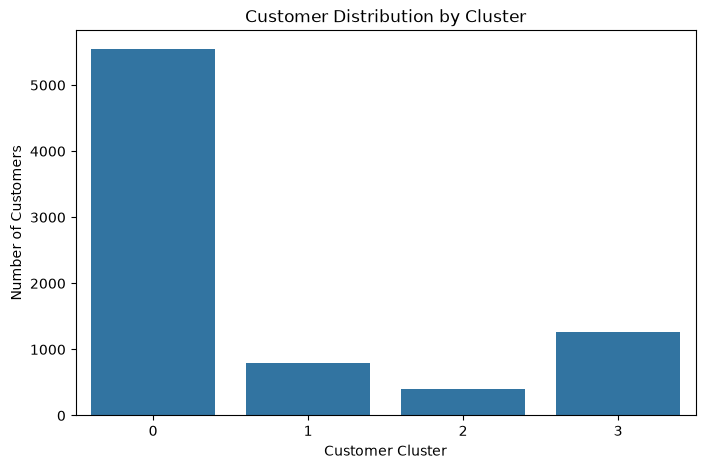

In [163]:
plt.figure(figsize=(8, 5))

sns.countplot(data=customer_data, x='cluster')

plt.title('Customer Distribution by Cluster')
plt.xlabel('Customer Cluster')
plt.ylabel('Number of Customers')

plt.show()

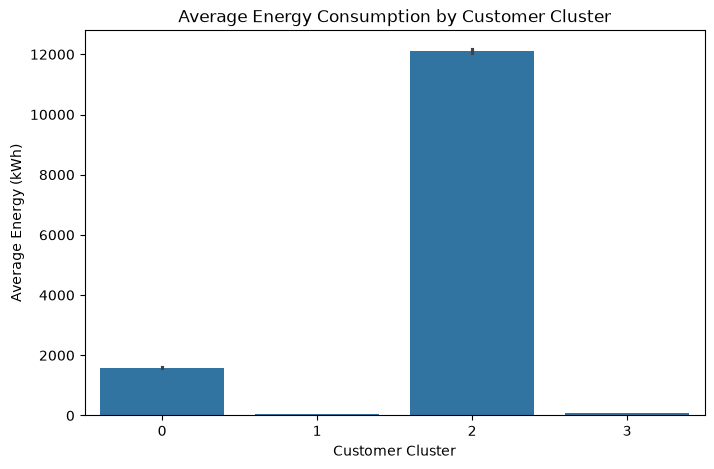

In [164]:
plt.figure(figsize=(8, 5))

sns.barplot(data=customer_data, x='cluster', y='total_energy', estimator='mean')

plt.title('Average Energy Consumption by Customer Cluster')
plt.xlabel('Customer Cluster')
plt.ylabel('Average Energy (kWh)')

plt.show()

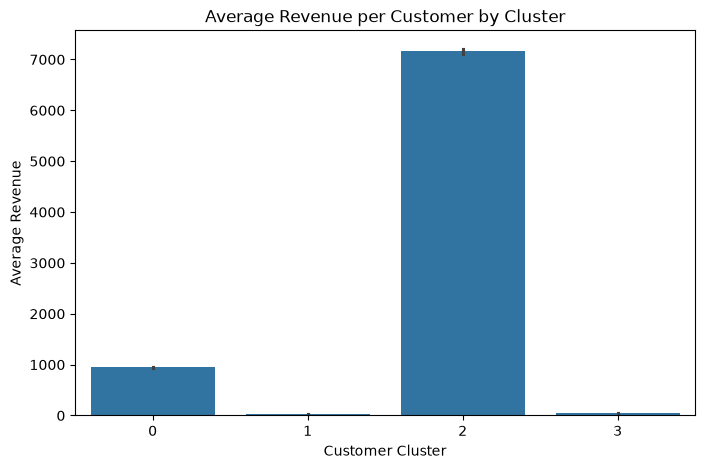

In [165]:
plt.figure(figsize=(8, 5))

sns.barplot(data=customer_data, x='cluster', y='total_revenue', estimator='mean')

plt.title('Average Revenue per Customer by Cluster')
plt.xlabel('Customer Cluster')
plt.ylabel('Average Revenue')

plt.show()

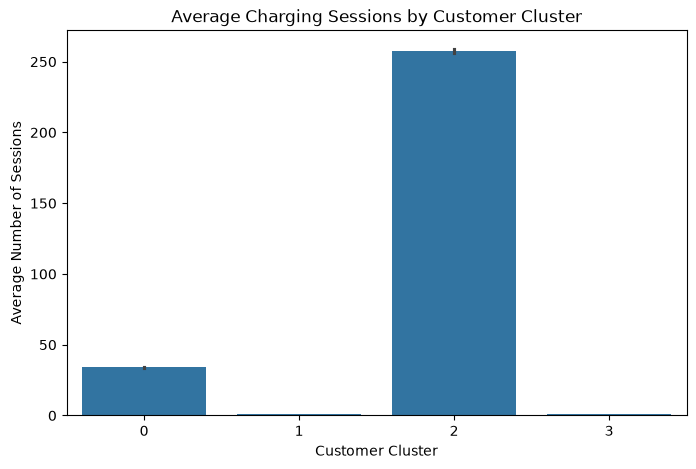

In [166]:
plt.figure(figsize=(8, 5))

sns.barplot(data=customer_data, x='cluster', y='total_sessions', estimator='mean')

plt.title('Average Charging Sessions by Customer Cluster')
plt.xlabel('Customer Cluster')
plt.ylabel('Average Number of Sessions')

plt.show()

In [167]:
persona_mapping = {
    0: 'Regular Chargers',
    1: 'Occasional Users',
    2: 'Power Users',
    3: 'Low-Usage Customers'
}

customer_data['persona'] = customer_data['cluster'].map(persona_mapping)

In [168]:
customer_data[['customer_id', 'cluster', 'persona']].head()

,customer_id,cluster,persona
0,CUST_00001,2,Power Users
1,CUST_00002,2,Power Users
2,CUST_00003,2,Power Users
3,CUST_00004,2,Power Users
4,CUST_00005,2,Power Users


In [169]:
segment_summary = customer_data.groupby('persona').agg(
    customers=('customer_id', 'count'),
    avg_sessions=('total_sessions', 'mean'),
    avg_energy=('total_energy', 'mean'),
    avg_revenue=('total_revenue', 'mean'),
    total_segment_revenue=('total_revenue', 'sum'),
    avg_session_duration=('avg_session_duration', 'mean'),
    avg_energy_per_session=('avg_energy_per_session', 'mean'),
    avg_stations=('unique_stations', 'mean')
).round(2)

In [170]:
segment_summary

,customers,avg_sessions,avg_energy,avg_revenue,total_segment_revenue,avg_session_duration,avg_energy_per_session,avg_stations
persona,,,,,,,,
Low-Usage Customers,1261,1.30,76.97,40.88,51549.42,22.60,59.88,1.23
Occasional Users,790,1.17,39.43,20.70,16350.80,49.63,33.20,1.14
Power Users,400,257.50,12106.67,7163.48,2865391.27,35.13,47.01,32.81
Regular Chargers,5549,33.96,1592.69,943.92,5237808.63,35.13,46.85,17.56


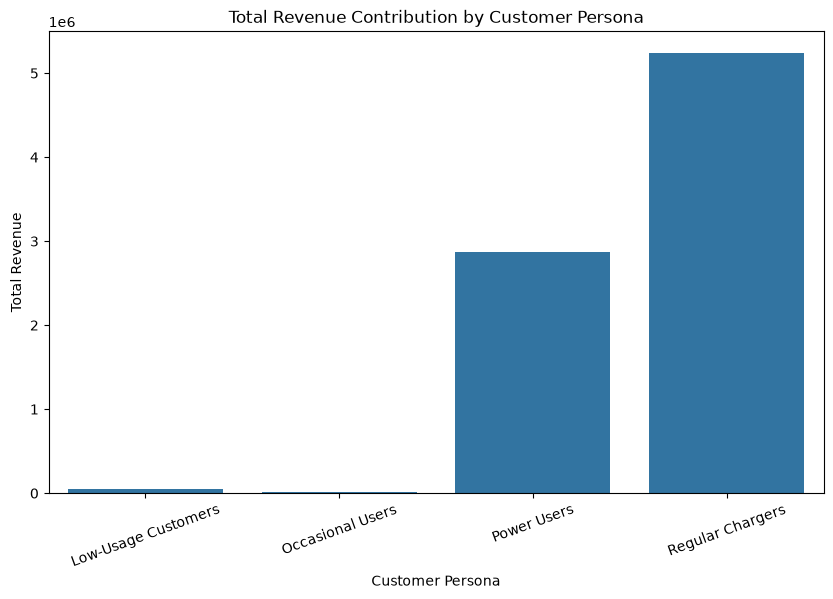

In [171]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=segment_summary,
    x=segment_summary.index,
    y='total_segment_revenue'
)

plt.title('Total Revenue Contribution by Customer Persona')
plt.xlabel('Customer Persona')
plt.ylabel('Total Revenue')
plt.xticks(rotation=20)
plt.show()

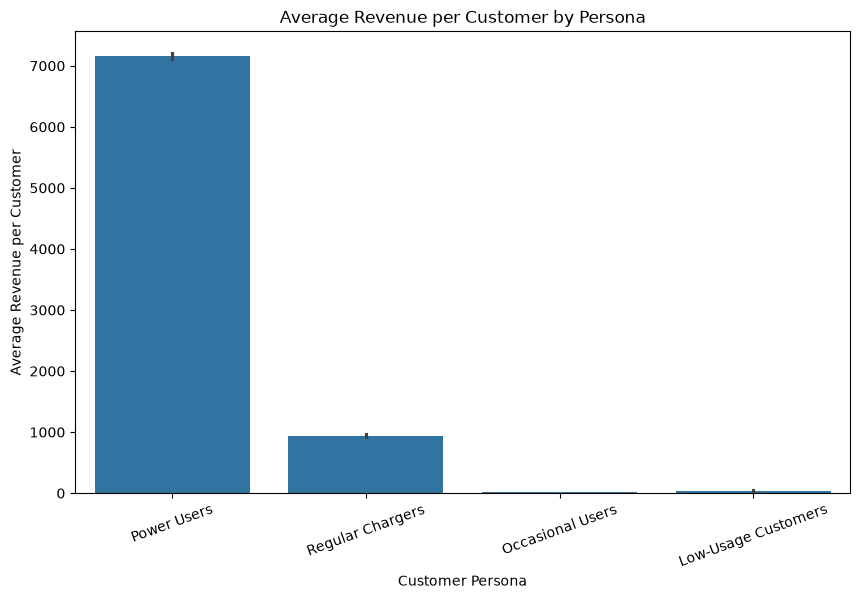

In [172]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=customer_data,
    x='persona',
    y='total_revenue',
    estimator='mean'
)

plt.title('Average Revenue per Customer by Persona')
plt.xlabel('Customer Persona')
plt.ylabel('Average Revenue per Customer')
plt.xticks(rotation=20)
plt.show()

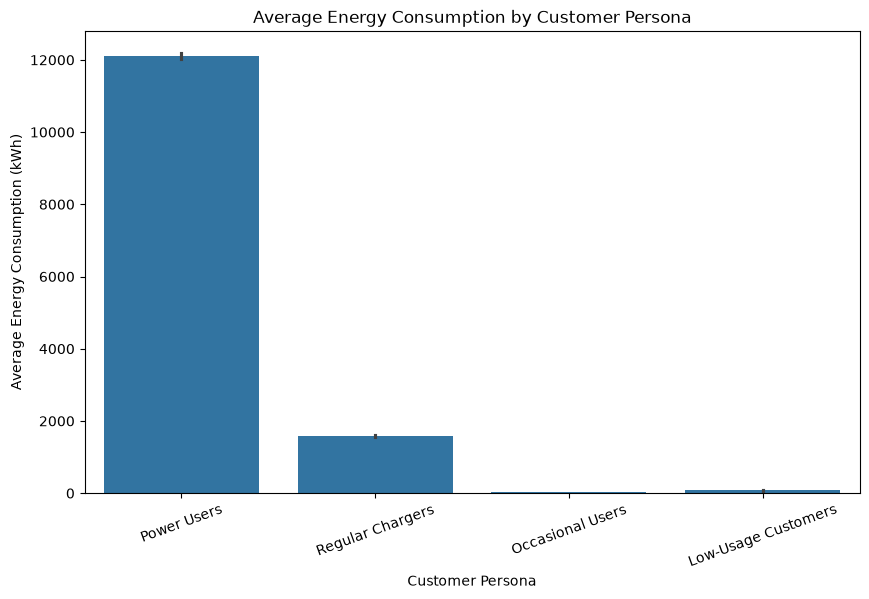

In [173]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=customer_data,
    x='persona',
    y='total_energy',
    estimator='mean'
)

plt.title('Average Energy Consumption by Customer Persona')
plt.xlabel('Customer Persona')
plt.ylabel('Average Energy Consumption (kWh)')
plt.xticks(rotation=20)
plt.show()

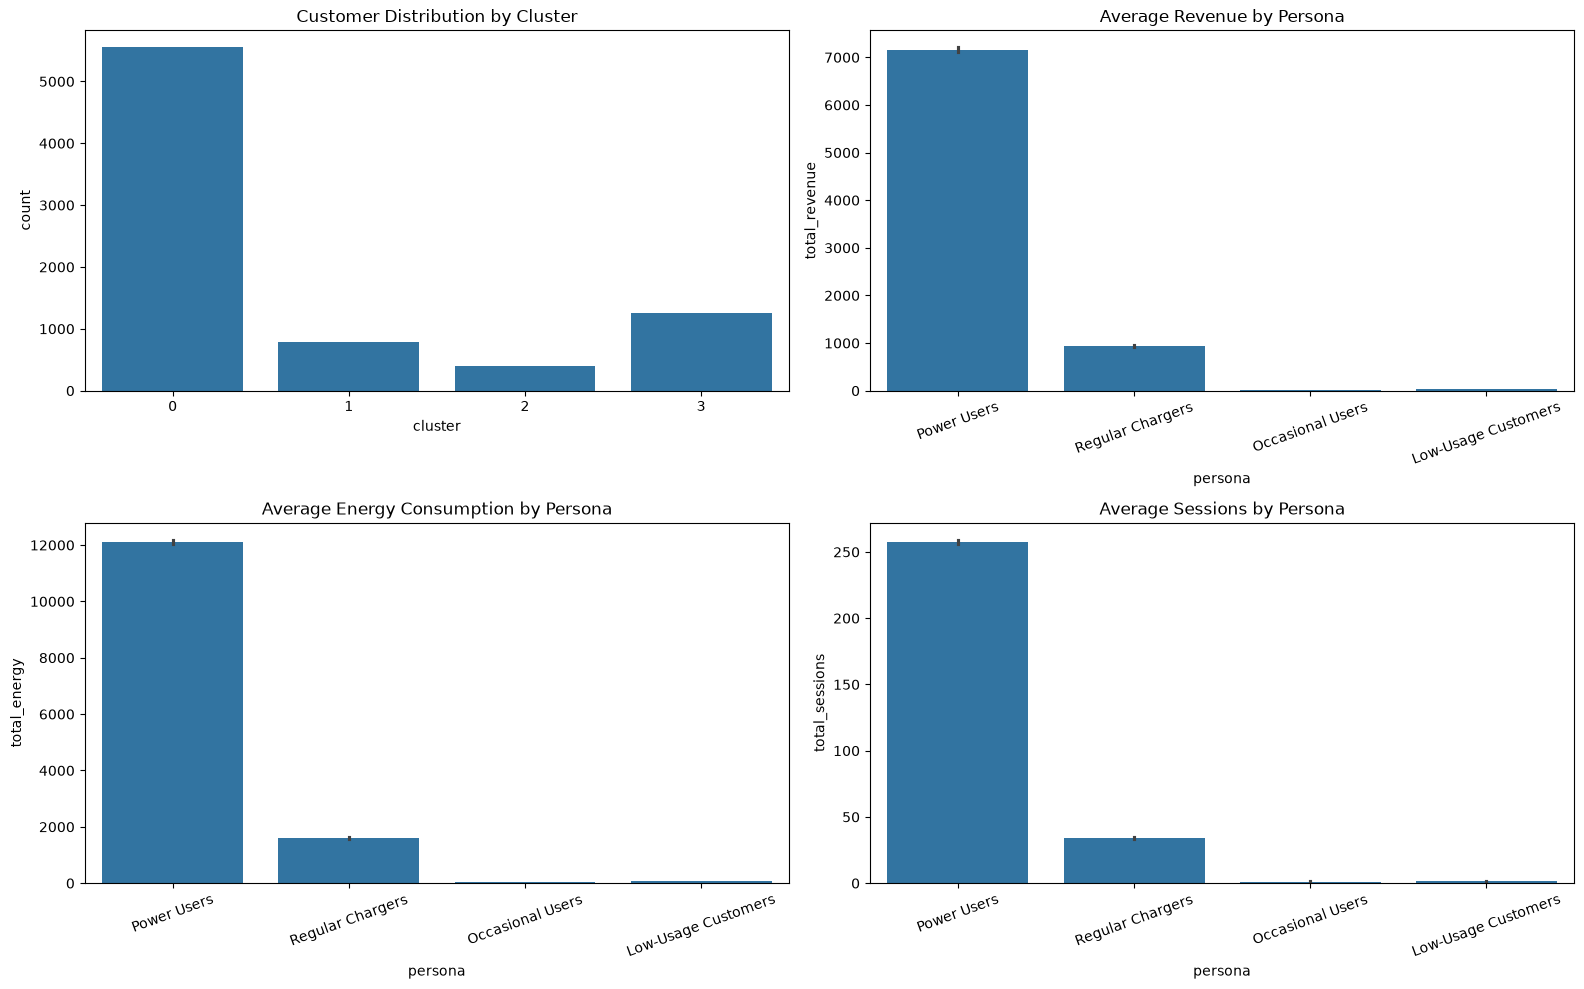

In [174]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Customer distribution
sns.countplot(data=customer_data, x='cluster', ax=axes[0, 0])
axes[0, 0].set_title('Customer Distribution by Cluster')

# Average revenue
sns.barplot(data=customer_data, x='persona', y='total_revenue', estimator='mean', ax=axes[0, 1])
axes[0, 1].set_title('Average Revenue by Persona')
axes[0, 1].tick_params(axis='x', rotation=20)

# Average energy
sns.barplot(data=customer_data, x='persona', y='total_energy', estimator='mean', ax=axes[1, 0])
axes[1, 0].set_title('Average Energy Consumption by Persona')
axes[1, 0].tick_params(axis='x', rotation=20)

# Average sessions
sns.barplot(data=customer_data, x='persona', y='total_sessions', estimator='mean', ax=axes[1, 1])
axes[1, 1].set_title('Average Sessions by Persona')
axes[1, 1].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()

In [175]:
customer_data.to_csv("customer_segmentation_final.csv", index=False)

In [176]:
segment_summary.to_csv("customer_segment_summary.csv")

In [177]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = sessions.copy()

print("Dataset Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:", df.duplicated().sum())

Dataset Shape: (294024, 22)

Columns:
['session_id', 'station_id', 'charger_id', 'charger_type', 'start_timestamp', 'end_timestamp', 'session_duration_minutes', 'energy_kwh', 'price_per_kwh', 'total_cost', 'payment_method', 'user_type', 'customer_id', 'station_region', 'year', 'month', 'day_name', 'hour', 'next_session_start', 'idle_minutes', 'day', 'weekday']

Missing Values:
session_id                    0
station_id                    0
charger_id                    0
charger_type                  0
start_timestamp               0
end_timestamp                 0
session_duration_minutes      0
energy_kwh                    0
price_per_kwh                 0
total_cost                    0
payment_method                0
user_type                     0
customer_id                   0
station_region                0
year                          0
month                         0
day_name                      0
hour                          0
next_session_start          199
idle_minutes

In [178]:
charger_health = df.groupby(
    ['charger_id', 'charger_type']
).agg(
    total_sessions=('session_id', 'count'),
    total_energy=('energy_kwh', 'sum'),
    avg_energy=('energy_kwh', 'mean'),
    avg_duration=('session_duration_minutes', 'mean'),
    total_charging_hours=('session_duration_minutes',
                          lambda x: x.sum()/60),
    avg_idle_minutes=('idle_minutes', 'mean')
).reset_index()

charger_health.head()

,charger_id,charger_type,total_sessions,total_energy,avg_energy,avg_duration,total_charging_hours,avg_idle_minutes
0,STN_001_CH_01,DC_50kW,3731,123295.5,33.046234,49.546770,3080.983333,373.169437
1,STN_001_CH_02,DC_150kW,3706,181117.4,48.871398,24.444145,1509.833333,401.393522
2,STN_001_CH_03,DC_150kW,3877,189580.8,48.898839,24.460408,1580.550000,382.438338
3,STN_001_CH_04,DC_50kW,3848,126957.9,32.993217,49.466736,3172.466667,360.559657
4,STN_002_CH_01,DC_50kW,3084,101707.9,32.979215,49.467899,2542.650000,461.197535


In [179]:
print("Total Chargers:", charger_health['charger_id'].nunique())

print("\nCharger Health Summary:")
display(charger_health.describe())

Total Chargers: 199

Charger Health Summary:


,total_sessions,total_energy,avg_energy,avg_duration,total_charging_hours,avg_idle_minutes
count,199.000000,199.000000,199.000000,199.000000,199.000000,199.000000
mean,1477.507538,69390.682412,46.000595,35.542990,864.212898,638.082813
std,897.038336,53689.097527,15.447449,13.464035,625.663032,169.332192
min,586.000000,19645.500000,32.698143,19.329431,192.650000,340.632789
25%,743.500000,35444.250000,32.986832,24.458344,419.108333,485.534373
50%,1258.000000,47575.400000,48.763329,24.584000,679.566667,684.827493
75%,1879.500000,93478.650000,49.041300,49.467317,1061.316667,792.512630
max,3877.000000,292098.400000,75.772007,49.822660,3172.466667,871.776068


In [180]:
charger_health = df.groupby('charger_id').agg(
    energy_std=('energy_kwh', 'std'),
    duration_std=('session_duration_minutes', 'std'),
    total_sessions=('session_id', 'count')
).reset_index()

charger_health = charger_health.merge(
    df.groupby('charger_id')['charger_type'].first().reset_index(),
    on='charger_id'
)

charger_health['energy_cv'] = (
    charger_health['energy_std'] /
    df.groupby('charger_id')['energy_kwh'].mean().values
)

charger_health['duration_cv'] = (
    charger_health['duration_std'] /
    df.groupby('charger_id')['session_duration_minutes'].mean().values
)

charger_health.head()

,charger_id,energy_std,duration_std,total_sessions,charger_type,energy_cv,duration_cv
0,STN_001_CH_01,3.018165,3.371167,3731,DC_50kW,0.091332,0.068040
1,STN_001_CH_02,4.538079,1.715763,3706,DC_150kW,0.092858,0.070191
2,STN_001_CH_03,4.453408,1.693578,3877,DC_150kW,0.091074,0.069238
3,STN_001_CH_04,3.042138,3.401163,3848,DC_50kW,0.092205,0.068757
4,STN_002_CH_01,2.992461,3.252077,3084,DC_50kW,0.090738,0.065741


In [181]:
print("First Session:", df['start_timestamp'].min())
print("Last Session:", df['start_timestamp'].max())

First Session: 2022-01-01 01:30:00
Last Session: 2024-12-31 23:50:00


In [182]:
# Total observation period
observation_hours = (
    df['end_timestamp'].max() -
    df['start_timestamp'].min()
).total_seconds() / 3600

# Calculate charger utilisation
utilisation = df.groupby('charger_id').agg(
    total_charging_hours=(
        'session_duration_minutes',
        lambda x: x.sum() / 60
    ),
    total_sessions=('session_id', 'count')
).reset_index()

utilisation['utilisation_rate'] = (
    utilisation['total_charging_hours'] /
    observation_hours
) * 100

utilisation = utilisation.sort_values(
    'utilisation_rate', ascending=False
)

display(utilisation.head(10))

,charger_id,total_charging_hours,total_sessions,utilisation_rate
3,STN_001_CH_04,3172.466667,3848,12.061143
35,STN_007_CH_02,3157.250000,3839,12.003292
37,STN_007_CH_04,3150.850000,3817,11.978961
0,STN_001_CH_01,3080.983333,3731,11.713340
36,STN_007_CH_03,3047.150000,3697,11.584712
33,STN_006_CH_04,3018.250000,3662,11.474840
9,STN_003_CH_01,2552.550000,3101,9.704333
4,STN_002_CH_01,2542.650000,3084,9.666695
13,STN_003_CH_05,2536.850000,3081,9.644644
38,STN_008_CH_01,2478.800000,3003,9.423948


In [183]:
display(utilisation.tail(10))

,charger_id,total_charging_hours,total_sessions,utilisation_rate
120,STN_021_CH_02,243.600000,594,0.926123
151,STN_025_CH_06,242.800000,596,0.923082
160,STN_026_CH_07,240.700000,590,0.915098
123,STN_021_CH_05,238.766667,586,0.907748
109,STN_019_CH_04,235.566667,726,0.895582
167,STN_027_CH_06,213.283333,658,0.810865
148,STN_025_CH_03,204.700000,632,0.778232
131,STN_023_CH_01,201.716667,620,0.766890
165,STN_027_CH_04,193.150000,593,0.734321
147,STN_025_CH_02,192.650000,598,0.732420


In [184]:
charger_health = df.groupby(
    ['charger_id', 'charger_type']
).agg(
    total_sessions=('session_id', 'count'),
    total_energy=('energy_kwh', 'sum'),
    avg_energy=('energy_kwh', 'mean'),
    energy_std=('energy_kwh', 'std'),
    avg_duration=('session_duration_minutes', 'mean'),
    duration_std=('session_duration_minutes', 'std'),
    total_charging_hours=('session_duration_minutes',
                          lambda x: x.sum() / 60),
    avg_idle_minutes=('idle_minutes', 'mean')
).reset_index()

# Calculate variability
charger_health['energy_cv'] = (
    charger_health['energy_std'] / charger_health['avg_energy']
)

charger_health['duration_cv'] = (
    charger_health['duration_std'] / charger_health['avg_duration']
)

# Add utilisation
charger_health = charger_health.merge(
    utilisation[['charger_id', 'utilisation_rate']],
    on='charger_id',
    how='left'
)

display(charger_health.head())

,charger_id,charger_type,total_sessions,total_energy,avg_energy,energy_std,avg_duration,duration_std,total_charging_hours,avg_idle_minutes,energy_cv,duration_cv,utilisation_rate
0,STN_001_CH_01,DC_50kW,3731,123295.5,33.046234,3.018165,49.546770,3.371167,3080.983333,373.169437,0.091332,0.068040,11.713340
1,STN_001_CH_02,DC_150kW,3706,181117.4,48.871398,4.538079,24.444145,1.715763,1509.833333,401.393522,0.092858,0.070191,5.740113
2,STN_001_CH_03,DC_150kW,3877,189580.8,48.898839,4.453408,24.460408,1.693578,1580.550000,382.438338,0.091074,0.069238,6.008965
3,STN_001_CH_04,DC_50kW,3848,126957.9,32.993217,3.042138,49.466736,3.401163,3172.466667,360.559657,0.092205,0.068757,12.061143
4,STN_002_CH_01,DC_50kW,3084,101707.9,32.979215,2.992461,49.467899,3.252077,2542.650000,461.197535,0.090738,0.065741,9.666695


In [185]:
# Calculate thresholds
low_util_threshold = charger_health['utilisation_rate'].quantile(0.25)
high_idle_threshold = charger_health['avg_idle_minutes'].quantile(0.75)
high_energy_cv = charger_health['energy_cv'].quantile(0.75)
high_duration_cv = charger_health['duration_cv'].quantile(0.75)

# Create health indicators
charger_health['low_utilisation'] = (
    charger_health['utilisation_rate'] < low_util_threshold
)

charger_health['high_idle_time'] = (
    charger_health['avg_idle_minutes'] > high_idle_threshold
)

charger_health['high_energy_variability'] = (
    charger_health['energy_cv'] > high_energy_cv
)

charger_health['high_duration_variability'] = (
    charger_health['duration_cv'] > high_duration_cv
)

# Calculate risk indicator score
risk_columns = [
    'low_utilisation',
    'high_idle_time',
    'high_energy_variability',
    'high_duration_variability'
]

charger_health['health_risk_score'] = (
    charger_health[risk_columns].sum(axis=1)
)

display(charger_health[
    ['charger_id', 'utilisation_rate',
     'avg_idle_minutes', 'energy_cv',
     'duration_cv', 'health_risk_score']
].head(10))

,charger_id,utilisation_rate,avg_idle_minutes,energy_cv,duration_cv,health_risk_score
0,STN_001_CH_01,11.713340,373.169437,0.091332,0.068040,0
1,STN_001_CH_02,5.740113,401.393522,0.092858,0.070191,1
2,STN_001_CH_03,6.008965,382.438338,0.091074,0.069238,0
3,STN_001_CH_04,12.061143,360.559657,0.092205,0.068757,0
4,STN_002_CH_01,9.666695,461.197535,0.090738,0.065741,0
5,STN_002_CH_02,3.786168,496.026806,0.070052,0.085218,1
6,STN_002_CH_03,4.772106,487.793630,0.092153,0.068786,0
7,STN_002_CH_04,3.817533,490.819799,0.071099,0.086458,1
8,STN_002_CH_05,3.645184,513.177980,0.069058,0.086538,1
9,STN_003_CH_01,9.704333,459.490968,0.091468,0.068058,0


In [186]:
def classify_risk(score):
    if score == 0:
        return 'Low'
    elif score <= 2:
        return 'Medium'
    else:
        return 'High'

charger_health['risk_category'] = (
    charger_health['health_risk_score'].apply(classify_risk)
)

# Count chargers in each category
print("Maintenance Risk Distribution:")
print(charger_health['risk_category'].value_counts())

# Create maintenance priority list
maintenance_priority = charger_health.sort_values(
    by=['health_risk_score', 'utilisation_rate'],
    ascending=[False, True]
)

print("\nTop 15 Chargers Requiring Investigation:")
display(
    maintenance_priority[
        ['charger_id', 'charger_type',
         'health_risk_score', 'risk_category',
         'utilisation_rate', 'avg_idle_minutes']
    ].head(15)
)

Maintenance Risk Distribution:
risk_category
Medium    98
Low       79
High      22
Name: count, dtype: int64

Top 15 Chargers Requiring Investigation:


,charger_id,charger_type,health_risk_score,risk_category,utilisation_rate,avg_idle_minutes
134,STN_023_CH_04,DC_150kW,4,High,0.931129,855.361809
161,STN_026_CH_08,DC_150kW,4,High,0.969844,819.998390
154,STN_026_CH_01,DC_150kW,4,High,1.000322,792.525661
147,STN_025_CH_02,DC_300kW,3,High,0.732420,860.604690
165,STN_027_CH_04,DC_300kW,3,High,0.734321,868.378378
131,STN_023_CH_01,DC_300kW,3,High,0.766890,830.948304
148,STN_025_CH_03,DC_300kW,3,High,0.778232,813.072900
123,STN_021_CH_05,DC_150kW,3,High,0.907748,871.776068
166,STN_027_CH_05,DC_150kW,3,High,0.954573,831.797386
164,STN_027_CH_03,DC_150kW,3,High,0.980489,801.020408


In [187]:
# Count how often each risk indicator is triggered
feature_importance = charger_health[risk_columns].sum().reset_index()

feature_importance.columns = [
    'Health_Indicator',
    'Chargers_Affected'
]

# Calculate percentage of chargers affected
feature_importance['Percentage'] = (
    feature_importance['Chargers_Affected'] /
    len(charger_health) * 100
)

feature_importance = feature_importance.sort_values(
    by='Chargers_Affected',
    ascending=False
)

print("Health Indicator Importance Report:")
display(feature_importance)

Health Indicator Importance Report:


,Health_Indicator,Chargers_Affected,Percentage
0,low_utilisation,50,25.125628
1,high_idle_time,50,25.125628
2,high_energy_variability,50,25.125628
3,high_duration_variability,50,25.125628


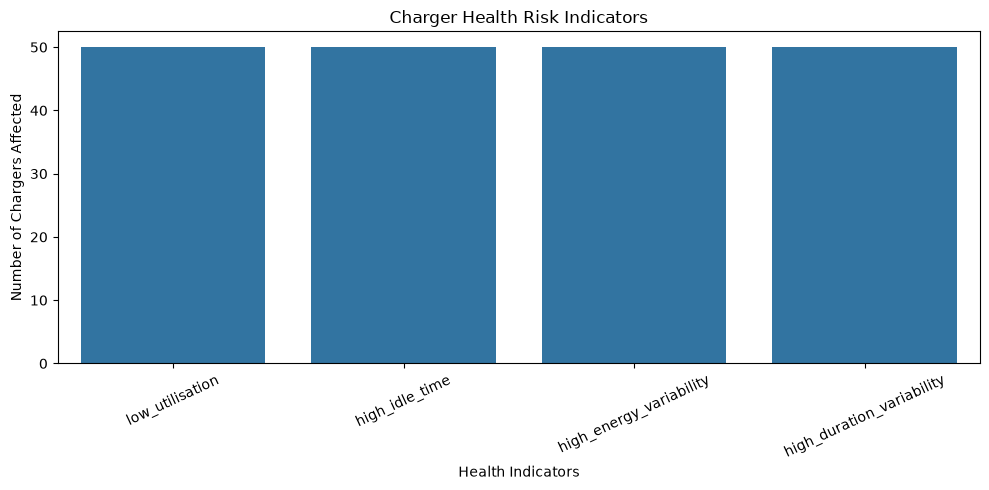

In [188]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=feature_importance,
    x='Health_Indicator',
    y='Chargers_Affected'
)

plt.title('Charger Health Risk Indicators')
plt.xlabel('Health Indicators')
plt.ylabel('Number of Chargers Affected')
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

In [189]:
def maintenance_recommendation(row):

    recommendations = []

    if row['low_utilisation']:
        recommendations.append(
            'Investigate low utilisation and demand patterns'
        )

    if row['high_idle_time']:
        recommendations.append(
            'Inspect idle periods and charger availability'
        )

    if row['high_energy_variability']:
        recommendations.append(
            'Check energy delivery and charging consistency'
        )

    if row['high_duration_variability']:
        recommendations.append(
            'Inspect charging duration variations'
        )

    if row['risk_category'] == 'High':
        recommendations.append(
            'Schedule priority technical inspection'
        )

    elif row['risk_category'] == 'Medium':
        recommendations.append(
            'Schedule preventive inspection'
        )

    else:
        recommendations.append(
            'Continue routine monitoring'
        )

    return '; '.join(recommendations)


charger_health['maintenance_recommendation'] = (
    charger_health.apply(maintenance_recommendation, axis=1)
)

# Final maintenance priority list
final_maintenance_list = maintenance_priority.merge(
    charger_health[
        ['charger_id', 'maintenance_recommendation']
    ],
    on='charger_id',
    how='left'
)

display(
    final_maintenance_list[
        ['charger_id', 'charger_type',
         'risk_category', 'health_risk_score',
         'maintenance_recommendation']
    ].head(20)
)

,charger_id,charger_type,risk_category,health_risk_score,maintenance_recommendation
0,STN_023_CH_04,DC_150kW,High,4,Investigate low utilisation and demand pattern...
1,STN_026_CH_08,DC_150kW,High,4,Investigate low utilisation and demand pattern...
2,STN_026_CH_01,DC_150kW,High,4,Investigate low utilisation and demand pattern...
3,STN_025_CH_02,DC_300kW,High,3,Investigate low utilisation and demand pattern...
4,STN_027_CH_04,DC_300kW,High,3,Investigate low utilisation and demand pattern...
5,STN_023_CH_01,DC_300kW,High,3,Investigate low utilisation and demand pattern...
6,STN_025_CH_03,DC_300kW,High,3,Investigate low utilisation and demand pattern...
7,STN_021_CH_05,DC_150kW,High,3,Investigate low utilisation and demand pattern...
8,STN_027_CH_05,DC_150kW,High,3,Investigate low utilisation and demand pattern...
9,STN_027_CH_03,DC_150kW,High,3,Investigate low utilisation and demand pattern...


In [190]:
# Export charger health indicators
charger_health.to_csv(
    'charger_health_indicators.csv',
    index=False
)

# Export maintenance priority list
final_maintenance_list.to_csv(
    'maintenance_priority_list.csv',
    index=False
)

# Export health indicator report
feature_importance.to_csv(
    'health_indicator_report.csv',
    index=False
)

print("All Task 5 files exported successfully!")

All Task 5 files exported successfully!


In [191]:
# Check dataset
print("Dataset Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nAvailable Regions:")
print(df['station_region'].unique())

print("\nNumber of Unique Stations:",
      df['station_id'].nunique())

print("\nNumber of Unique Customers:",
      df['customer_id'].nunique())

print("\nMissing Values:")
print(df[['station_region', 'station_id',
          'customer_id', 'energy_kwh']].isnull().sum())

Dataset Shape: (294024, 22)

Columns:
['session_id', 'station_id', 'charger_id', 'charger_type', 'start_timestamp', 'end_timestamp', 'session_duration_minutes', 'energy_kwh', 'price_per_kwh', 'total_cost', 'payment_method', 'user_type', 'customer_id', 'station_region', 'year', 'month', 'day_name', 'hour', 'next_session_start', 'idle_minutes', 'day', 'weekday']

Available Regions:
<ArrowStringArray>
[        'North West',             'London',           'Midlands',
         'South West',         'North East',              'Wales',
           'Scotland', 'Yorkshire & Humber',         'South East']
Length: 9, dtype: str

Number of Unique Stations: 33

Number of Unique Customers: 8000

Missing Values:
station_region    0
station_id        0
customer_id       0
energy_kwh        0
dtype: int64


In [192]:
regional_demand = df.groupby('station_region').agg(
    total_sessions=('session_id', 'count'),
    total_energy=('energy_kwh', 'sum'),
    total_revenue=('total_cost', 'sum'),
    unique_customers=('customer_id', 'nunique'),
    avg_energy_per_session=('energy_kwh', 'mean')
).reset_index()

regional_demand = regional_demand.sort_values(
    by='total_energy',
    ascending=False
)

display(regional_demand)

,station_region,total_sessions,total_energy,total_revenue,unique_customers,avg_energy_per_session
3,North West,65789,3005135.1,1749659.79,6667,45.678382
1,Midlands,50598,2576709.8,1512888.72,6369,50.925131
0,London,40760,1978090.6,1167892.57,5939,48.530191
6,South West,30401,1580496.2,936566.78,5675,51.988296
2,North East,30439,1398050.3,827839.36,5646,45.929574
5,South East,25168,1088495.1,650189.40,5161,43.249170
4,Scotland,20242,947010.5,568971.33,4891,46.784433
8,Yorkshire & Humber,20468,899734.0,551615.57,4875,43.958081
7,Wales,10159,335024.2,205476.60,3721,32.978069


In [193]:
regional_supply = df.groupby('station_region').agg(
    total_stations=('station_id', 'nunique'),
    total_chargers=('charger_id', 'nunique')
).reset_index()

regional_analysis = regional_demand.merge(
    regional_supply,
    on='station_region'
)

regional_analysis['energy_per_station'] = (
    regional_analysis['total_energy'] /
    regional_analysis['total_stations']
)

regional_analysis['sessions_per_station'] = (
    regional_analysis['total_sessions'] /
    regional_analysis['total_stations']
)

regional_analysis = regional_analysis.sort_values(
    by='energy_per_station',
    ascending=False
)

display(regional_analysis)

,station_region,total_sessions,total_energy,total_revenue,unique_customers,avg_energy_per_session,total_stations,total_chargers,energy_per_station,sessions_per_station
3,South West,30401,1580496.2,936566.78,5675,51.988296,3,15,526832.066667,10133.666667
1,Midlands,50598,2576709.8,1512888.72,6369,50.925131,5,26,515341.960000,10119.600000
4,North East,30439,1398050.3,827839.36,5646,45.929574,3,17,466016.766667,10146.333333
7,Yorkshire & Humber,20468,899734.0,551615.57,4875,43.958081,2,12,449867.000000,10234.000000
0,North West,65789,3005135.1,1749659.79,6667,45.678382,7,48,429305.014286,9398.428571
2,London,40760,1978090.6,1167892.57,5939,48.530191,5,25,395618.120000,8152.000000
8,Wales,10159,335024.2,205476.60,3721,32.978069,1,8,335024.200000,10159.000000
6,Scotland,20242,947010.5,568971.33,4891,46.784433,3,22,315670.166667,6747.333333
5,South East,25168,1088495.1,650189.40,5161,43.249170,4,26,272123.775000,6292.000000


In [194]:
gap_analysis = regional_analysis.copy()

total_energy = gap_analysis['total_energy'].sum()
total_stations = gap_analysis['total_stations'].sum()

gap_analysis['demand_share'] = (
    gap_analysis['total_energy'] / total_energy * 100
)

gap_analysis['supply_share'] = (
    gap_analysis['total_stations'] / total_stations * 100
)

gap_analysis['demand_supply_gap'] = (
    gap_analysis['demand_share'] - gap_analysis['supply_share']
)

gap_analysis = gap_analysis.sort_values(
    by='demand_supply_gap',
    ascending=False
)

display(gap_analysis[[
    'station_region',
    'demand_share',
    'supply_share',
    'demand_supply_gap'
]])

,station_region,demand_share,supply_share,demand_supply_gap
1,Midlands,18.659984,15.151515,3.508469
3,South West,11.445617,9.090909,2.354708
4,North East,10.124383,9.090909,1.033474
0,North West,21.762549,21.212121,0.550428
7,Yorkshire & Humber,6.515682,6.060606,0.455076
8,Wales,2.426174,3.030303,-0.604129
2,London,14.324911,15.151515,-0.826604
6,Scotland,6.858049,9.090909,-2.232860
5,South East,7.882650,12.121212,-4.238562


In [195]:
location_scores = gap_analysis.copy()

# Normalize each indicator to a 0–100 scale
location_scores['demand_score'] = (
    location_scores['total_energy'] /
    location_scores['total_energy'].max() * 100
)

location_scores['customer_score'] = (
    location_scores['unique_customers'] /
    location_scores['unique_customers'].max() * 100
)

# Shift the gap to a positive scale before normalization
min_gap = location_scores['demand_supply_gap'].min()

location_scores['gap_score'] = (
    (location_scores['demand_supply_gap'] - min_gap) /
    (location_scores['demand_supply_gap'].max() - min_gap) * 100
)

# Weighted location score
location_scores['location_score'] = (
    0.40 * location_scores['demand_score'] +
    0.30 * location_scores['customer_score'] +
    0.30 * location_scores['gap_score']
)

location_scores = location_scores.sort_values(
    by='location_score',
    ascending=False
).reset_index(drop=True)

location_scores['expansion_rank'] = (
    location_scores.index + 1
)

display(location_scores[[
    'expansion_rank',
    'station_region',
    'demand_score',
    'customer_score',
    'gap_score',
    'location_score'
]])

,expansion_rank,station_region,demand_score,customer_score,gap_score,location_score
0,1,Midlands,85.743559,95.530223,100.000000,92.956491
1,2,North West,100.000000,100.000000,61.817101,88.545130
2,3,South West,52.593183,85.120744,85.107057,72.105614
3,4,London,65.823683,89.080546,44.042140,66.266279
4,5,North East,46.522045,84.685766,68.052338,64.430249
5,6,Yorkshire & Humber,29.939885,73.121344,60.586283,52.088242
6,7,Scotland,31.513076,73.361332,25.889939,42.380611
7,8,South East,36.221170,77.411129,0.000000,37.711807
8,9,Wales,11.148391,55.812209,46.913882,35.277184


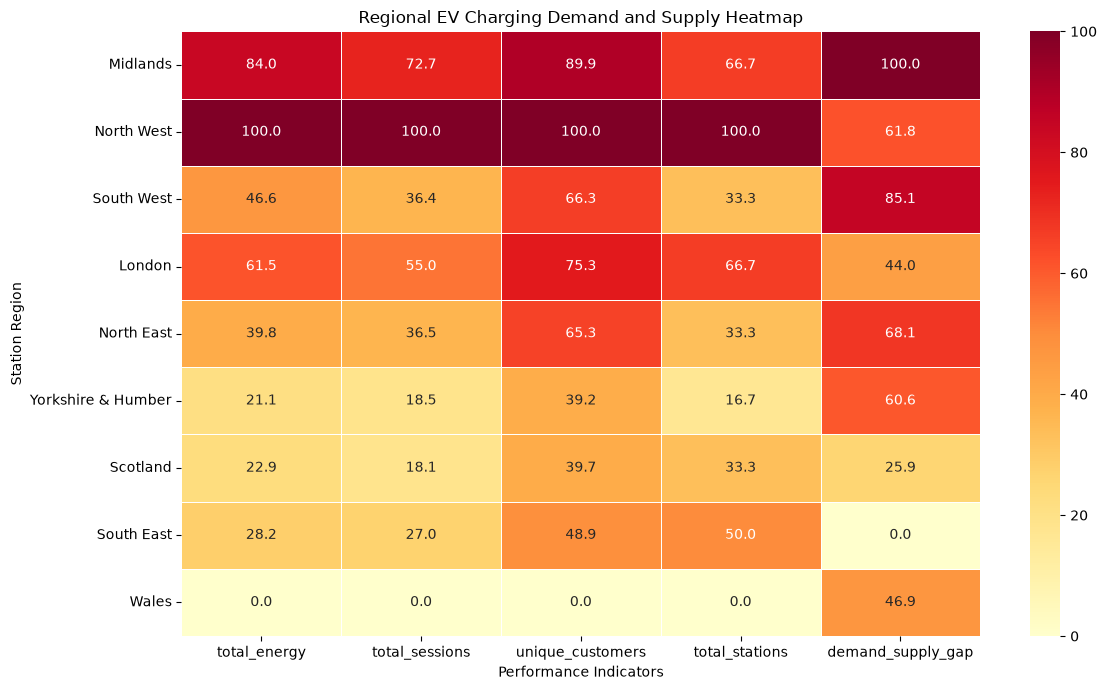

In [196]:
import matplotlib.pyplot as plt
import seaborn as sns

heatmap_data = location_scores.set_index('station_region')[[
    'total_energy',
    'total_sessions',
    'unique_customers',
    'total_stations',
    'demand_supply_gap'
]]

# Normalize values between 0 and 100
heatmap_scaled = (
    (heatmap_data - heatmap_data.min()) /
    (heatmap_data.max() - heatmap_data.min())
) * 100

plt.figure(figsize=(12, 7))

sns.heatmap(
    heatmap_scaled,
    annot=True,
    fmt='.1f',
    cmap='YlOrRd',
    linewidths=0.5
)

plt.title('Regional EV Charging Demand and Supply Heatmap')
plt.xlabel('Performance Indicators')
plt.ylabel('Station Region')
plt.tight_layout()
plt.show()

In [197]:
import folium

print("Folium version:", folium.__version__)

Folium version: 0.20.0


In [198]:
import folium

# Approximate geographical centres of UK regions
region_coordinates = {
    'North West': [53.8, -2.7],
    'Midlands': [52.8, -1.5],
    'London': [51.5, -0.12],
    'South West': [50.9, -3.5],
    'North East': [54.9, -1.8],
    'South East': [51.2, 0.7],
    'Scotland': [56.5, -4.0],
    'Yorkshire & Humber': [53.9, -1.3],
    'Wales': [52.3, -3.7]
}

# Create map
uk_map = folium.Map(
    location=[54.0, -2.5],
    zoom_start=6,
    tiles='CartoDB positron'
)

# Add regional markers
for _, row in location_scores.iterrows():

    region = row['station_region']
    latitude, longitude = region_coordinates[region]

    score = row['location_score']

    folium.CircleMarker(
        location=[latitude, longitude],
        radius=8 + score / 12,
        popup=f"""
        Region: {region}<br>
        Expansion Rank: {row['expansion_rank']}<br>
        Location Score: {score:.2f}
        """,
        tooltip=f"{region} - Score: {score:.2f}",
        color='blue',
        fill=True,
        fill_opacity=0.7
    ).add_to(uk_map)

uk_map

In [199]:
# Export regional demand analysis
regional_analysis.to_csv(
    'regional_demand_analysis.csv',
    index=False
)

# Export demand-supply gap analysis
gap_analysis.to_csv(
    'regional_gap_analysis.csv',
    index=False
)

# Export location scoring model
location_scores.to_csv(
    'location_scoring_model.csv',
    index=False
)

# Save interactive map
uk_map.save('uk_expansion_priority_map.html')

print("Task 6 files exported successfully!")

Task 6 files exported successfully!


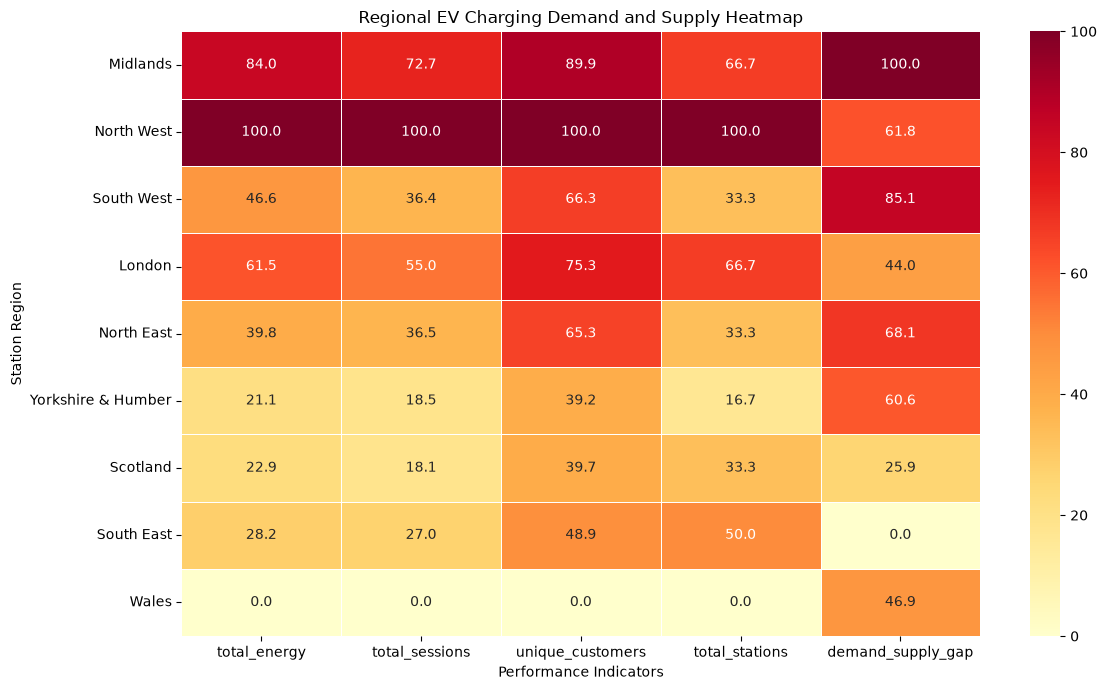

Heatmap saved successfully!


In [200]:
plt.figure(figsize=(12, 7))

sns.heatmap(
    heatmap_scaled,
    annot=True,
    fmt='.1f',
    cmap='YlOrRd',
    linewidths=0.5
)

plt.title('Regional EV Charging Demand and Supply Heatmap')
plt.xlabel('Performance Indicators')
plt.ylabel('Station Region')
plt.tight_layout()

plt.savefig(
    'regional_demand_heatmap.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

print("Heatmap saved successfully!")

In [201]:
top_regions = location_scores.head(3)

print("=" * 60)
print("EV CHARGING STATION EXPANSION STRATEGY REPORT")
print("=" * 60)

print("\nTOP 3 RECOMMENDED REGIONS")

for _, row in top_regions.iterrows():
    print(
        f"\nRank {row['expansion_rank']}: {row['station_region']}"
        f"\nLocation Score: {row['location_score']:.2f}"
        f"\nDemand Score: {row['demand_score']:.2f}"
        f"\nCustomer Score: {row['customer_score']:.2f}"
        f"\nSupply Gap Score: {row['gap_score']:.2f}"
    )

print("\n\nKEY FINDINGS")

print("\nHighest demand region:",
      regional_analysis.loc[
          regional_analysis['total_energy'].idxmax(),
          'station_region'
      ])

print("\nHighest demand-supply gap:",
      gap_analysis.iloc[0]['station_region'])

print("\nHighest energy per station:",
      regional_analysis.loc[
          regional_analysis['energy_per_station'].idxmax(),
          'station_region'
      ])

print("\n\nRECOMMENDATION")
print(
    "Prioritise Midlands, North West and South West "
    "for further investigation and potential EV charging "
    "infrastructure expansion."
)

EV CHARGING STATION EXPANSION STRATEGY REPORT

TOP 3 RECOMMENDED REGIONS

Rank 1: Midlands
Location Score: 92.96
Demand Score: 85.74
Customer Score: 95.53
Supply Gap Score: 100.00

Rank 2: North West
Location Score: 88.55
Demand Score: 100.00
Customer Score: 100.00
Supply Gap Score: 61.82

Rank 3: South West
Location Score: 72.11
Demand Score: 52.59
Customer Score: 85.12
Supply Gap Score: 85.11


KEY FINDINGS

Highest demand region: North West

Highest demand-supply gap: Midlands

Highest energy per station: South West


RECOMMENDATION
Prioritise Midlands, North West and South West for further investigation and potential EV charging infrastructure expansion.


In [202]:
print("Dataset Shape:", df.shape)

print("\nRequired Columns:")
required_columns = [
    'start_timestamp',
    'energy_kwh',
    'session_id',
    'station_region',
    'charger_type',
    'hour',
    'day_name',
    'month',
    'year'
]

for col in required_columns:
    print(col, ":", col in df.columns)

print("\nSample Data:")
display(df[required_columns].head())

Dataset Shape: (294024, 22)

Required Columns:
start_timestamp : True
energy_kwh : True
session_id : True
station_region : True
charger_type : True
hour : True
day_name : True
month : True
year : True

Sample Data:


,start_timestamp,energy_kwh,session_id,station_region,charger_type,hour,day_name,month,year
4,2022-01-01 16:10:00,31.7,S_00000005,North West,DC_50kW,16,Saturday,1,2022
7,2022-01-01 16:10:00,30.5,S_00000008,North West,DC_50kW,16,Saturday,1,2022
8,2022-01-01 19:40:00,35.0,S_00000009,North West,DC_50kW,19,Saturday,1,2022
3,2022-01-01 23:20:00,28.4,S_00000004,North West,DC_50kW,23,Saturday,1,2022
97,2022-01-02 07:10:00,27.0,S_00000098,North West,DC_50kW,7,Sunday,1,2022


In [203]:
hourly_demand = df.groupby('hour').agg(
    total_sessions=('session_id', 'count'),
    total_energy=('energy_kwh', 'sum'),
    avg_energy=('energy_kwh', 'mean')
).reset_index()

hourly_demand = hourly_demand.sort_values('hour')

display(hourly_demand)

,hour,total_sessions,total_energy,avg_energy
0,0,2754,128740.8,46.746841
1,1,2677,125309.7,46.809750
2,2,2719,127569.8,46.917911
3,3,2633,124141.6,47.148348
4,4,2705,127238.3,47.038189
5,5,5360,250529.5,46.740578
6,6,7985,375601.5,47.038384
7,7,10648,498779.7,46.842571
8,8,15967,750802.3,47.022127
9,9,21370,1004475.5,47.004001


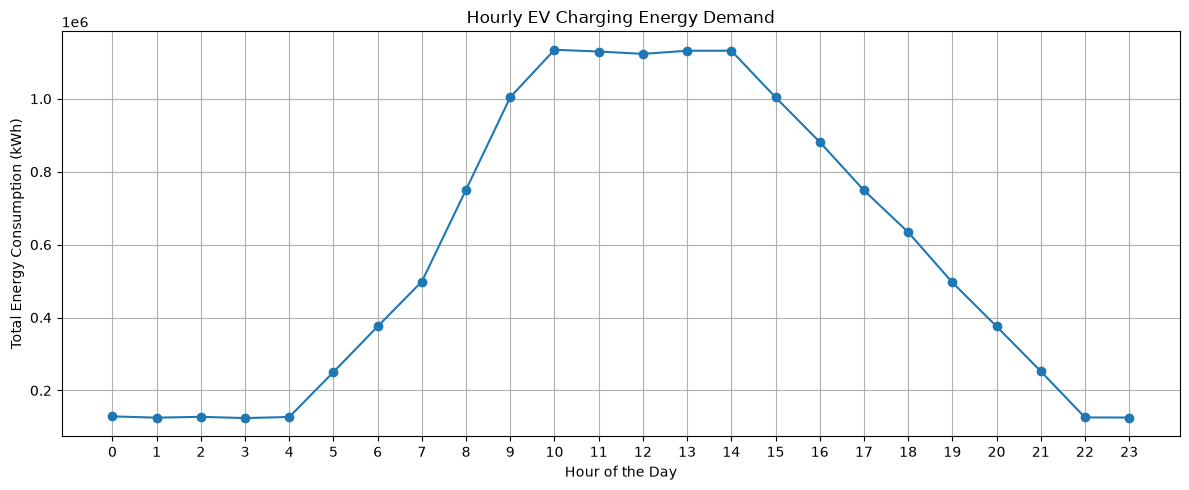

In [204]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    hourly_demand['hour'],
    hourly_demand['total_energy'],
    marker='o'
)

plt.title('Hourly EV Charging Energy Demand')
plt.xlabel('Hour of the Day')
plt.ylabel('Total Energy Consumption (kWh)')
plt.xticks(range(24))
plt.grid(True)
plt.tight_layout()

plt.savefig('hourly_demand.png', dpi=300)
plt.show()

In [205]:
day_order = [
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
]

daily_demand = df.groupby('day_name').agg(
    total_sessions=('session_id', 'count'),
    total_energy=('energy_kwh', 'sum'),
    avg_energy=('energy_kwh', 'mean')
).reindex(day_order).reset_index()

display(daily_demand)

,day_name,total_sessions,total_energy,avg_energy
0,Monday,45733,2142123.0,46.839766
1,Tuesday,45922,2150639.0,46.832433
2,Wednesday,45106,2124099.9,47.091294
3,Thursday,45070,2122028.4,47.082947
4,Friday,45529,2136010.7,46.915388
5,Saturday,33335,1564654.5,46.937288
6,Sunday,33329,1569190.3,47.081830


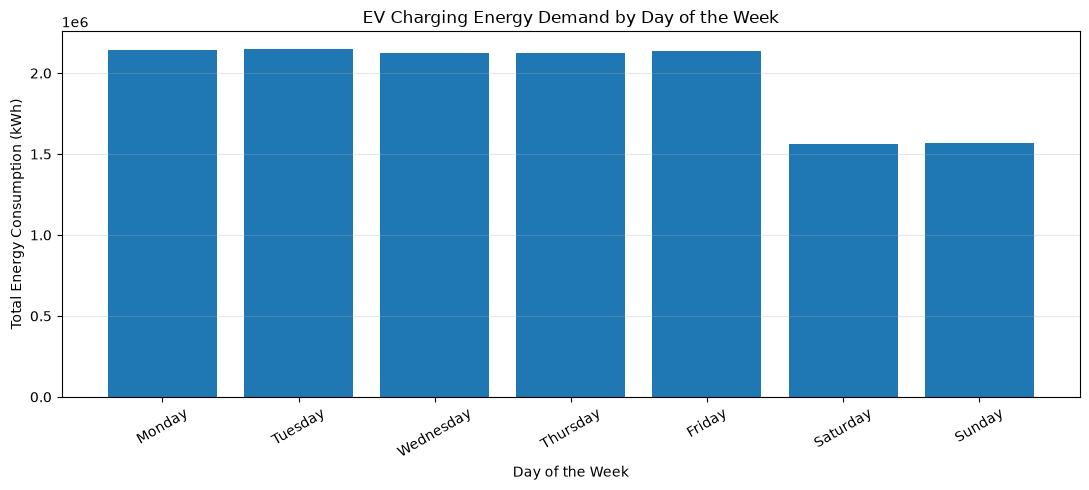

In [206]:
plt.figure(figsize=(11, 5))

plt.bar(
    daily_demand['day_name'],
    daily_demand['total_energy']
)

plt.title('EV Charging Energy Demand by Day of the Week')
plt.xlabel('Day of the Week')
plt.ylabel('Total Energy Consumption (kWh)')
plt.xticks(rotation=30)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()

plt.savefig('weekly_demand.png', dpi=300)
plt.show()

In [207]:
df['day_type'] = df['weekday'].apply(
    lambda x: 'Weekend' if x >= 5 else 'Weekday'
)

week_comparison = df.groupby('day_type').agg(
    total_sessions=('session_id', 'count'),
    total_energy=('energy_kwh', 'sum'),
    avg_energy_per_session=('energy_kwh', 'mean')
).reset_index()

display(week_comparison)

,day_type,total_sessions,total_energy,avg_energy_per_session
0,Weekday,227360,10674901.0,46.951535
1,Weekend,66664,3133844.8,47.009552


In [208]:
peak_hour = hourly_demand.loc[
    hourly_demand['total_energy'].idxmax()
]

off_peak_hour = hourly_demand.loc[
    hourly_demand['total_energy'].idxmin()
]

print("PEAK HOUR")
print(peak_hour)

print("\nOFF-PEAK HOUR")
print(off_peak_hour)

PEAK HOUR
hour              1.000000e+01
total_sessions    2.421400e+04
total_energy      1.134524e+06
avg_energy        4.685405e+01
Name: 10, dtype: float64

OFF-PEAK HOUR
hour                   3.000000
total_sessions      2633.000000
total_energy      124141.600000
avg_energy            47.148348
Name: 3, dtype: float64


In [209]:
monthly_demand = df.groupby('month').agg(
    total_sessions=('session_id', 'count'),
    total_energy=('energy_kwh', 'sum'),
    avg_energy=('energy_kwh', 'mean')
).reset_index()

month_names = {
    1: 'January', 2: 'February', 3: 'March',
    4: 'April', 5: 'May', 6: 'June',
    7: 'July', 8: 'August', 9: 'September',
    10: 'October', 11: 'November', 12: 'December'
}

monthly_demand['month_name'] = monthly_demand['month'].map(month_names)

display(monthly_demand)

,month,total_sessions,total_energy,avg_energy,month_name
0,1,25088,1176434.1,46.892303,January
1,2,23156,1089574.6,47.053662,February
2,3,24792,1163381.7,46.925690,March
3,4,23967,1123577.9,46.880206,April
4,5,25128,1181017.5,47.000060,May
5,6,24071,1136593.6,47.218379,June
6,7,24861,1168469.0,47.000080,July
7,8,24956,1170360.9,46.896975,August
8,9,23846,1122961.8,47.092250,September
9,10,24982,1170337.5,46.847230,October


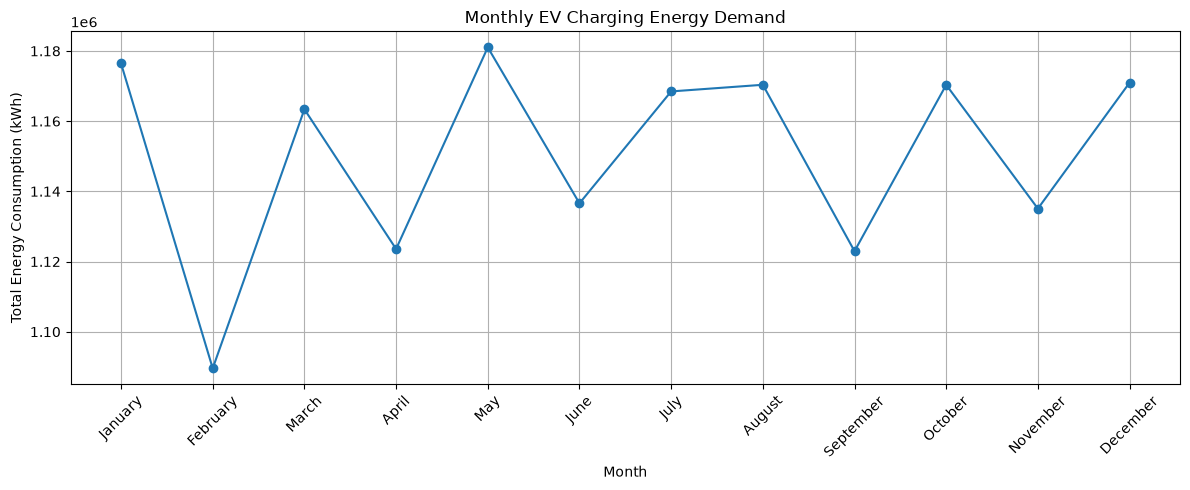

In [210]:
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_demand['month_name'],
    monthly_demand['total_energy'],
    marker='o'
)

plt.title('Monthly EV Charging Energy Demand')
plt.xlabel('Month')
plt.ylabel('Total Energy Consumption (kWh)')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()

plt.savefig('monthly_seasonal_demand.png', dpi=300)
plt.show()

In [211]:
yearly_monthly_demand = df.groupby(
    ['year', 'month']
).agg(
    total_sessions=('session_id', 'count'),
    total_energy=('energy_kwh', 'sum')
).reset_index()

display(yearly_monthly_demand)

,year,month,total_sessions,total_energy
0,2022,1,3394,167166.3
1,2022,2,3120,155708.9
2,2022,3,3497,173678.2
3,2022,4,3349,164041.3
4,2022,5,3497,172824.0
5,2022,6,3334,165544.1
6,2022,7,3419,168716.2
7,2022,8,3518,175107.3
8,2022,9,3278,161900.3
9,2022,10,3412,168846.0


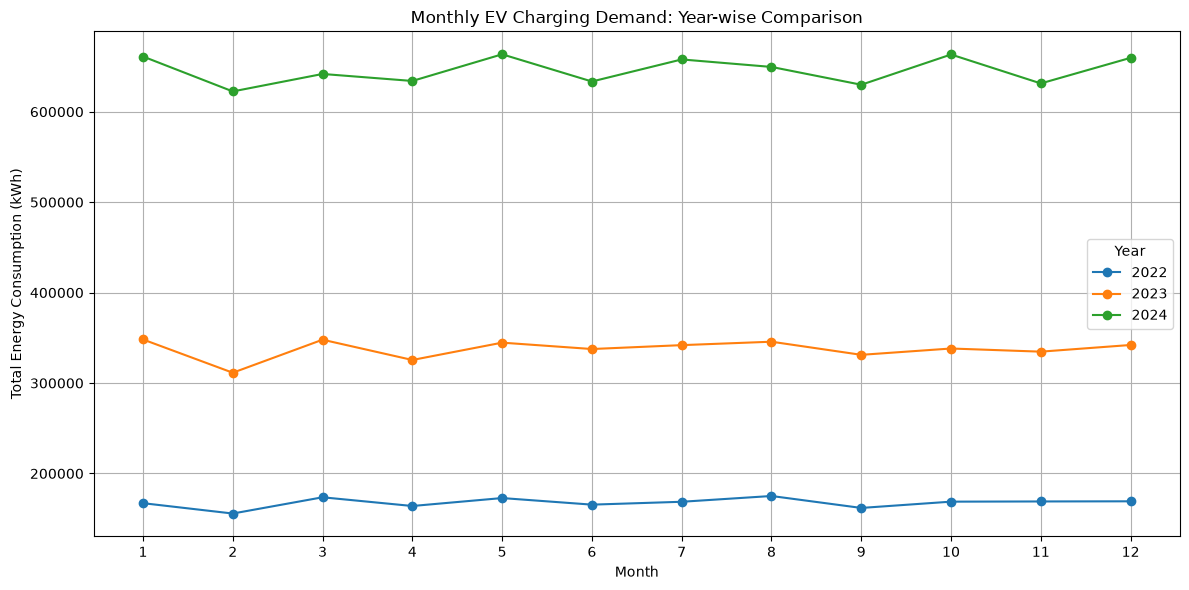

In [212]:
yearly_pivot = yearly_monthly_demand.pivot(
    index='month',
    columns='year',
    values='total_energy'
)

plt.figure(figsize=(12, 6))

for year in yearly_pivot.columns:
    plt.plot(
        yearly_pivot.index,
        yearly_pivot[year],
        marker='o',
        label=str(year)
    )

plt.title('Monthly EV Charging Demand: Year-wise Comparison')
plt.xlabel('Month')
plt.ylabel('Total Energy Consumption (kWh)')
plt.xticks(range(1, 13))
plt.legend(title='Year')
plt.grid(True)
plt.tight_layout()

plt.savefig('yearly_seasonal_comparison.png', dpi=300)
plt.show()

In [213]:
region_hourly = df.pivot_table(
    index='station_region',
    columns='hour',
    values='energy_kwh',
    aggfunc='sum',
    fill_value=0
)

display(region_hourly)

hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
station_region,,,,,,,,,,,,,,,,,,,,,
London,18072.8,17396.4,18917.1,17581.1,18487.4,34309.1,54079.9,71460.9,105319.9,142800.4,...,163787.5,145499.2,124706.4,110653.1,91659.7,71149.3,56239.4,35587.6,19516.2,18681.4
Midlands,24365.6,24252.6,25187.1,23369.0,24082.6,45532.2,68737.0,90152.4,137832.1,185418.6,...,210290.5,184297.3,167838.6,136938.4,121107.6,91593.1,71048.0,46563.4,22411.7,22329.1
North East,12368.2,13026.0,12962.8,12849.8,13780.2,26175.4,38971.8,53053.8,78687.5,103061.9,...,110537.7,101570.6,86243.4,78112.8,64097.6,49804.8,34533.5,25652.2,13624.7,13034.1
North West,28409.4,27419.6,27144.1,26025.9,27694.2,57230.3,84142.9,107596.6,161088.0,217044.1,...,248896.2,217040.8,188538.2,161999.7,134826.0,110805.4,84931.8,55916.6,27595.0,26710.7
Scotland,9277.1,8025.3,7787.3,7844.6,8728.2,15294.8,24774.7,33722.5,53733.4,70608.8,...,78247.2,69372.2,63979.7,53054.3,44489.7,34070.1,24202.3,16452.2,8814.8,7584.1
South East,9961.4,9271.8,9761.2,9790.6,9772.6,19256.1,30735.6,40370.8,58898.9,79427.7,...,88510.9,79655.6,69712.4,60587.4,48393.3,38181.8,29175.1,20587.3,8425.9,10514.8
South West,14687.6,14051.0,14326.6,15859.4,13620.6,31251.9,41835.9,57031.4,86853.6,115482.9,...,131735.1,117392.6,102451.8,83504.7,75386.6,54300.1,40867.9,28452.4,13838.5,15112.0
Wales,3057.5,3111.8,2788.2,2926.8,3180.4,6401.9,8420.3,12575.5,19030.4,24924.5,...,27224.0,24872.3,22157.6,16812.6,14833.2,12356.2,9016.8,6016.0,3012.0,3016.2
Yorkshire & Humber,8541.2,8755.2,8695.4,7894.4,7892.1,15077.8,23903.4,32815.8,49358.5,65706.6,...,72660.9,64373.1,55935.9,47120.4,39337.7,33934.8,25626.2,17379.8,8630.1,8650.4


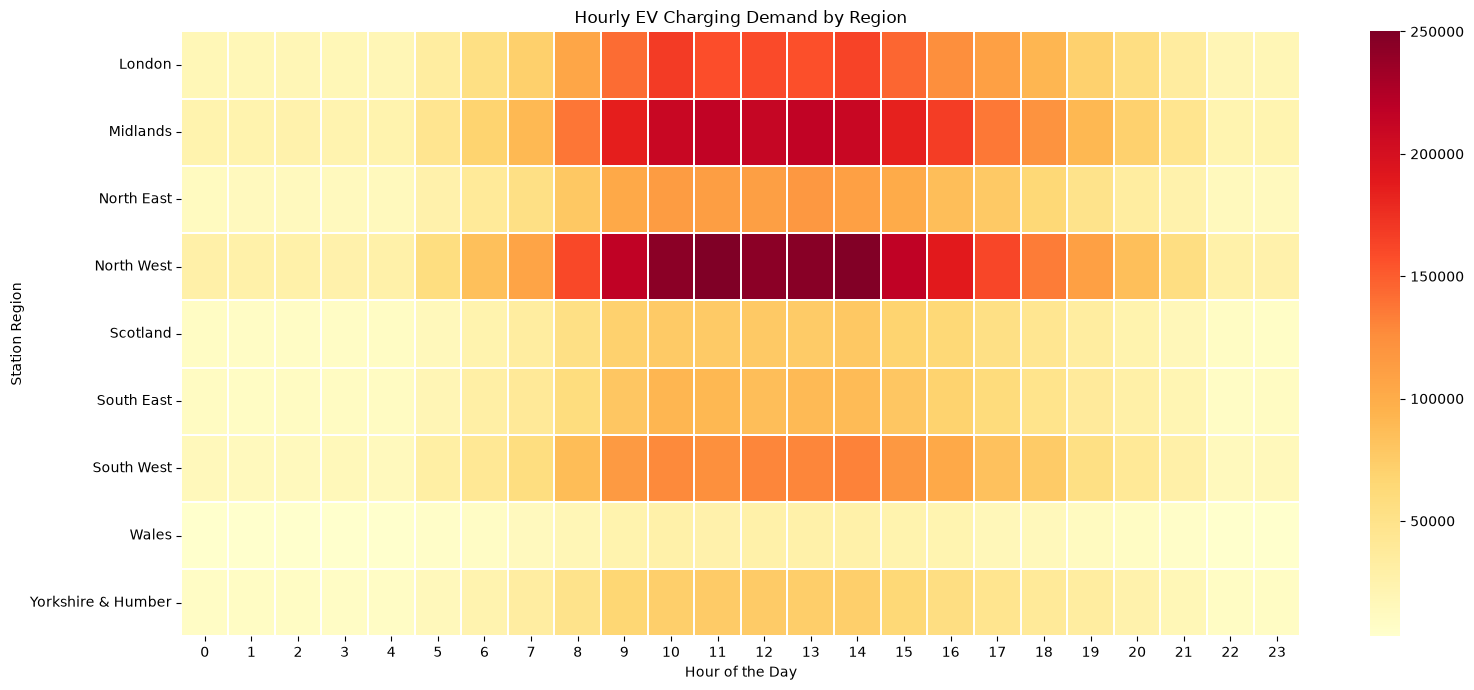

In [214]:
import seaborn as sns

plt.figure(figsize=(16, 7))

sns.heatmap(
    region_hourly,
    cmap='YlOrRd',
    linewidths=0.3,
    annot=False
)

plt.title('Hourly EV Charging Demand by Region')
plt.xlabel('Hour of the Day')
plt.ylabel('Station Region')
plt.tight_layout()

plt.savefig('regional_hourly_heatmap.png', dpi=300)
plt.show()

In [215]:
charger_hourly = df.pivot_table(
    index='charger_type',
    columns='hour',
    values='energy_kwh',
    aggfunc='sum',
    fill_value=0
)

display(charger_hourly)

hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
charger_type,,,,,,,,,,,,,,,,,,,,,
DC_150kW,46515.1,41485.3,42373.7,42722.9,41629.8,86285.8,134704.2,171601.3,257445.1,352476.1,...,388392.3,338779.3,302171.5,258776.6,211233.4,169482.0,130733.3,88171.6,44726.4,41272.3
DC_300kW,40103.3,42010.2,42901.7,41319.4,43260.3,80676.7,121584.9,163457.1,249424.3,328396.5,...,372374.7,342510.8,291783.5,243364.0,214640.2,160544.4,124662.0,83302.9,40996.2,43486.7
DC_50kW,42122.4,41814.2,42294.4,40099.3,42348.2,83567.0,119312.4,163721.3,243932.9,323602.9,...,371123.0,322783.6,287609.0,246642.8,208257.8,166169.2,120245.7,81133.0,40146.3,40873.8


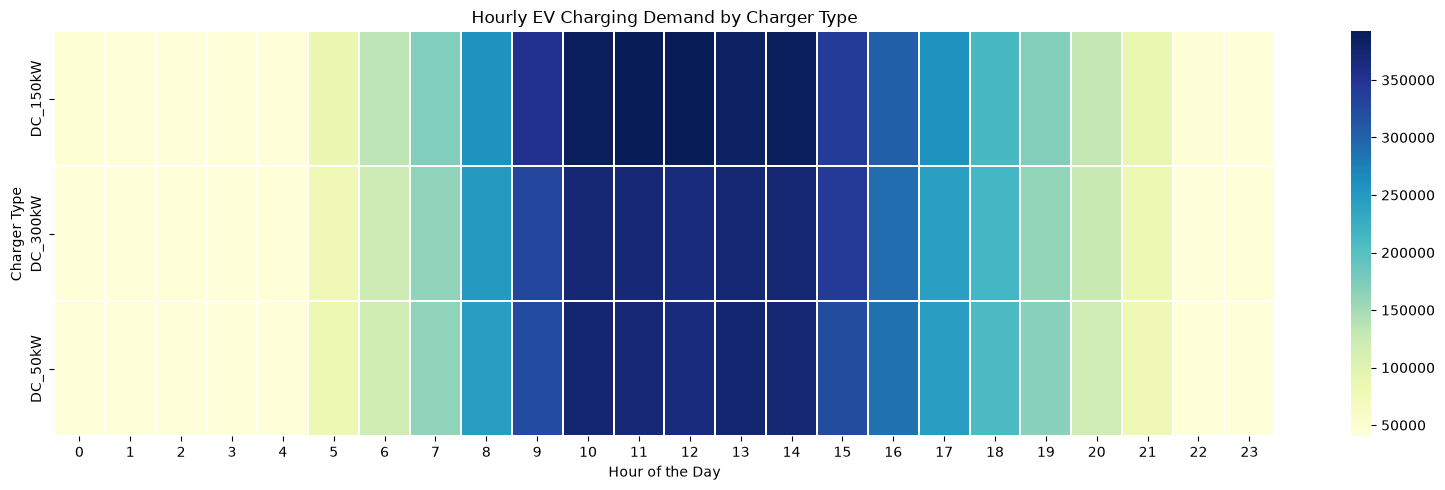

In [216]:
plt.figure(figsize=(16, 5))

sns.heatmap(
    charger_hourly,
    cmap='YlGnBu',
    linewidths=0.3,
    annot=False
)

plt.title('Hourly EV Charging Demand by Charger Type')
plt.xlabel('Hour of the Day')
plt.ylabel('Charger Type')
plt.tight_layout()

plt.savefig('charger_type_hourly_heatmap.png', dpi=300)
plt.show()

In [217]:
charger_summary = df.groupby('charger_type').agg(
    total_sessions=('session_id', 'count'),
    total_energy=('energy_kwh', 'sum'),
    avg_energy_per_session=('energy_kwh', 'mean'),
    avg_duration_minutes=('session_duration_minutes', 'mean')
).reset_index()

display(charger_summary.round(2))

,charger_type,total_sessions,total_energy,avg_energy_per_session,avg_duration_minutes
0,DC_150kW,96977,4748473.8,48.96,24.50
1,DC_300kW,60226,4549226.2,75.54,19.49
2,DC_50kW,136821,4511045.8,32.97,49.48


In [218]:
hourly_demand.to_csv('hourly_demand_summary.csv', index=False)
daily_demand.to_csv('weekly_demand_summary.csv', index=False)
week_comparison.to_csv('weekday_weekend_comparison.csv', index=False)
monthly_demand.to_csv('monthly_seasonal_summary.csv', index=False)
yearly_monthly_demand.to_csv('yearly_monthly_demand.csv', index=False)
region_hourly.to_csv('regional_hourly_demand.csv')
charger_hourly.to_csv('charger_type_hourly_demand.csv')
charger_summary.to_csv('charger_type_summary.csv', index=False)

print("All Task 7 analysis files exported successfully!")

All Task 7 analysis files exported successfully!


In [219]:
import os

chart_files = [
    'hourly_demand.png',
    'weekly_demand.png',
    'monthly_seasonal_demand.png',
    'yearly_seasonal_comparison.png',
    'regional_hourly_heatmap.png',
    'charger_type_hourly_heatmap.png'
]

for file in chart_files:
    print(f"{file}: {'Found' if os.path.exists(file) else 'Missing'}")

hourly_demand.png: Found
weekly_demand.png: Found
monthly_seasonal_demand.png: Found
yearly_seasonal_comparison.png: Found
regional_hourly_heatmap.png: Found
charger_type_hourly_heatmap.png: Found


In [220]:
recommendations = [
    "1. Peak-hour planning: Increase charger availability and operational staffing between 9 AM and 3 PM, with the highest demand around 10 AM.",
    
    "2. Weekday planning: Weekday average daily energy demand is approximately 36% higher than weekend demand. Allocate resources accordingly.",
    
    "3. Off-peak incentives: Consider lower tariffs or promotional offers during overnight hours to encourage flexible charging.",
    
    "4. Maintenance scheduling: Plan routine maintenance during low-demand overnight hours, particularly around 2 AM to 4 AM.",
    
    "5. Regional planning: North West and Midlands show high absolute demand. Evaluate charger capacity and demand per charger before expanding infrastructure.",
    
    "6. Charger-type planning: DC_50kW chargers have the most sessions and longest average duration, while DC_300kW chargers deliver the highest average energy per session.",
    
    "7. Seasonal planning: May shows the highest aggregate monthly energy demand, while February shows the lowest. Monitor year-wise trends before making seasonal decisions."
]

for recommendation in recommendations:
    print(recommendation)
    print()

1. Peak-hour planning: Increase charger availability and operational staffing between 9 AM and 3 PM, with the highest demand around 10 AM.

2. Weekday planning: Weekday average daily energy demand is approximately 36% higher than weekend demand. Allocate resources accordingly.

3. Off-peak incentives: Consider lower tariffs or promotional offers during overnight hours to encourage flexible charging.

4. Maintenance scheduling: Plan routine maintenance during low-demand overnight hours, particularly around 2 AM to 4 AM.

5. Regional planning: North West and Midlands show high absolute demand. Evaluate charger capacity and demand per charger before expanding infrastructure.

6. Charger-type planning: DC_50kW chargers have the most sessions and longest average duration, while DC_300kW chargers deliver the highest average energy per session.

7. Seasonal planning: May shows the highest aggregate monthly energy demand, while February shows the lowest. Monitor year-wise trends before making 

In [221]:
df['start_timestamp'] = pd.to_datetime(df['start_timestamp'])

df['hour'] = df['start_timestamp'].dt.hour
df['day'] = df['start_timestamp'].dt.day_name()
df['month'] = df['start_timestamp'].dt.month
df['year'] = df['start_timestamp'].dt.year

In [222]:
def classify_period(hour):

    if 18 <= hour <= 21:
        return "Peak"

    elif 0 <= hour <= 5:
        return "Off-Peak"

    else:
        return "Normal"

df['time_period'] = df['hour'].apply(classify_period)

In [223]:
df['time_period'].value_counts()

time_period
Normal      237756
Peak         37420
Off-Peak     18848
Name: count, dtype: int64

In [224]:
time_demand = df.groupby('time_period').agg(
    total_sessions=('session_id', 'count'),
    total_energy=('energy_kwh', 'sum'),
    avg_price=('price_per_kwh', 'mean'),
    total_revenue=('total_cost', 'sum')
).reset_index()

time_demand

,time_period,total_sessions,total_energy,avg_price,total_revenue
0,Normal,237756,11166640.6,0.587767,6557039.46
1,Off-Peak,18848,883529.7,0.578997,510944.56
2,Peak,37420,1758575.5,0.627949,1103116.10


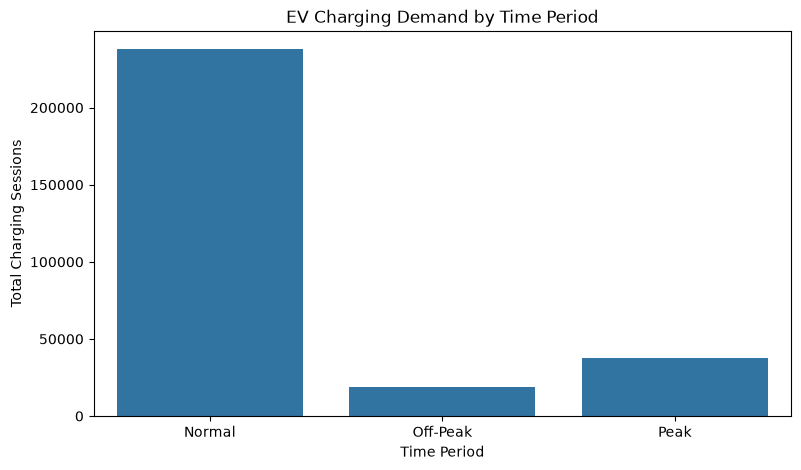

In [225]:
plt.figure(figsize=(9,5))

sns.barplot(
    data=time_demand,
    x='time_period',
    y='total_sessions'
)

plt.title('EV Charging Demand by Time Period')
plt.xlabel('Time Period')
plt.ylabel('Total Charging Sessions')

plt.show()

In [226]:
hourly_demand = df.groupby('hour').agg(
    total_sessions=('session_id', 'count'),
    total_energy=('energy_kwh', 'sum'),
    avg_price=('price_per_kwh', 'mean'),
    total_revenue=('total_cost', 'sum')
).reset_index()

hourly_demand

,hour,total_sessions,total_energy,avg_price,total_revenue
0,0,2754,128740.8,0.579648,74539.92
1,1,2677,125309.7,0.578532,72460.92
2,2,2719,127569.8,0.579264,73800.06
3,3,2633,124141.6,0.579229,71830.48
4,4,2705,127238.3,0.580384,73769.08
5,5,5360,250529.5,0.577944,144544.10
6,6,7985,375601.5,0.578725,217232.60
7,7,10648,498779.7,0.578604,288222.62
8,8,15967,750802.3,0.579218,434377.18
9,9,21370,1004475.5,0.579158,581180.64


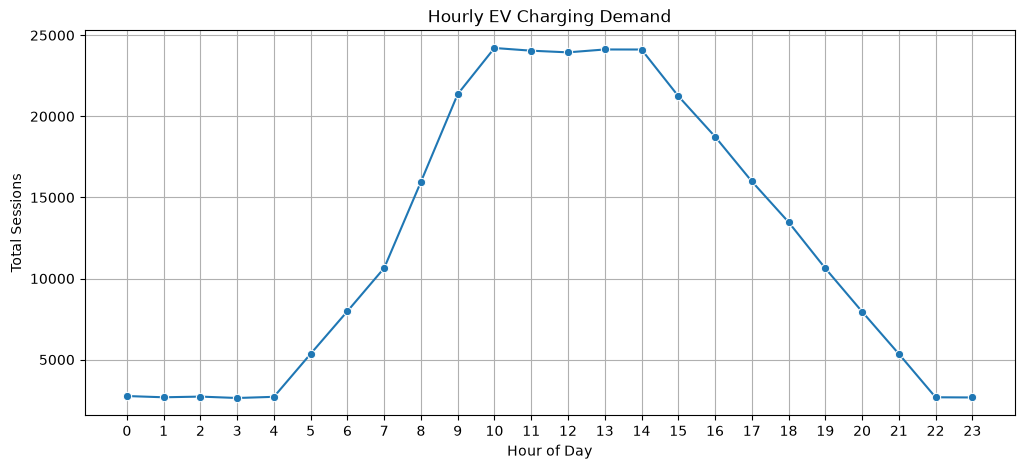

In [227]:
plt.figure(figsize=(12,5))

sns.lineplot(
    data=hourly_demand,
    x='hour',
    y='total_sessions',
    marker='o'
)

plt.title('Hourly EV Charging Demand')
plt.xlabel('Hour of Day')
plt.ylabel('Total Sessions')
plt.xticks(range(0,24))
plt.grid()
plt.show()

In [228]:
region_demand = df.groupby('station_region').agg(
    total_sessions=('session_id', 'count'),
    total_energy=('energy_kwh', 'sum'),
    avg_price=('price_per_kwh', 'mean'),
    total_revenue=('total_cost', 'sum')
).reset_index()

region_demand

,station_region,total_sessions,total_energy,avg_price,total_revenue
0,London,40760,1978090.6,0.591380,1167892.57
1,Midlands,50598,2576709.8,0.587834,1512888.72
2,North East,30439,1398050.3,0.591773,827839.36
3,North West,65789,3005135.1,0.582161,1749659.79
4,Scotland,20242,947010.5,0.600892,568971.33
5,South East,25168,1088495.1,0.598166,650189.40
6,South West,30401,1580496.2,0.591893,936566.78
7,Wales,10159,335024.2,0.613346,205476.60
8,Yorkshire & Humber,20468,899734.0,0.613267,551615.57


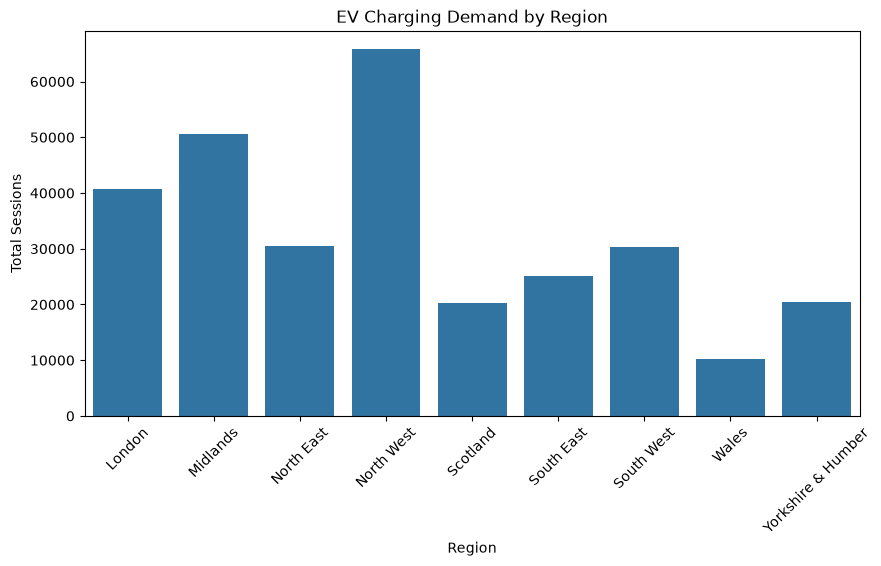

In [229]:
plt.figure(figsize=(10,5))

sns.barplot(
    data=region_demand,
    x='station_region',
    y='total_sessions'
)

plt.title('EV Charging Demand by Region')
plt.xlabel('Region')
plt.ylabel('Total Sessions')
plt.xticks(rotation=45)
plt.show()

In [230]:
charger_demand = df.groupby('charger_type').agg(
    total_sessions=('session_id', 'count'),
    total_energy=('energy_kwh', 'sum'),
    avg_price=('price_per_kwh', 'mean'),
    total_revenue=('total_cost', 'sum')
).reset_index()

charger_demand

,charger_type,total_sessions,total_energy,avg_price,total_revenue
0,DC_150kW,96977,4748473.8,0.591151,2807082.52
1,DC_300kW,60226,4549226.2,0.589959,2683669.03
2,DC_50kW,136821,4511045.8,0.594185,2680348.57


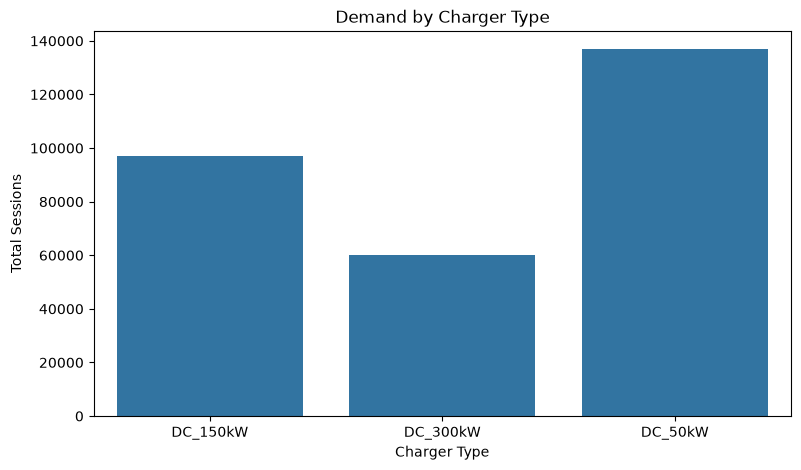

In [231]:
plt.figure(figsize=(9,5))

sns.barplot(
    data=charger_demand,
    x='charger_type',
    y='total_sessions'
)

plt.title('Demand by Charger Type')
plt.xlabel('Charger Type')
plt.ylabel('Total Sessions')
plt.show()

In [232]:
low_threshold = hourly_demand['total_sessions'].quantile(0.33)
high_threshold = hourly_demand['total_sessions'].quantile(0.67)

def demand_level(sessions):

    if sessions <= low_threshold:
        return "Low"

    elif sessions <= high_threshold:
        return "Medium"

    else:
        return "High"

hourly_demand['demand_level'] = hourly_demand['total_sessions'].apply(demand_level)

hourly_demand

,hour,total_sessions,total_energy,avg_price,total_revenue,demand_level
0,0,2754,128740.8,0.579648,74539.92,Low
1,1,2677,125309.7,0.578532,72460.92,Low
2,2,2719,127569.8,0.579264,73800.06,Low
3,3,2633,124141.6,0.579229,71830.48,Low
4,4,2705,127238.3,0.580384,73769.08,Low
5,5,5360,250529.5,0.577944,144544.10,Medium
6,6,7985,375601.5,0.578725,217232.60,Medium
7,7,10648,498779.7,0.578604,288222.62,Medium
8,8,15967,750802.3,0.579218,434377.18,Medium
9,9,21370,1004475.5,0.579158,581180.64,High


In [233]:
demand_multiplier = {
    'Low': 0.95,
    'Medium': 1.00,
    'High': 1.05
}

hourly_demand['demand_multiplier'] = hourly_demand['demand_level'].map(demand_multiplier)

hourly_demand

,hour,total_sessions,total_energy,avg_price,total_revenue,demand_level,demand_multiplier
0,0,2754,128740.8,0.579648,74539.92,Low,0.95
1,1,2677,125309.7,0.578532,72460.92,Low,0.95
2,2,2719,127569.8,0.579264,73800.06,Low,0.95
3,3,2633,124141.6,0.579229,71830.48,Low,0.95
4,4,2705,127238.3,0.580384,73769.08,Low,0.95
5,5,5360,250529.5,0.577944,144544.10,Medium,1.00
6,6,7985,375601.5,0.578725,217232.60,Medium,1.00
7,7,10648,498779.7,0.578604,288222.62,Medium,1.00
8,8,15967,750802.3,0.579218,434377.18,Medium,1.00
9,9,21370,1004475.5,0.579158,581180.64,High,1.05


In [234]:
df = df.merge(
    hourly_demand[['hour', 'demand_level', 'demand_multiplier']],
    on='hour',
    how='left'
)

df.head()

,session_id,station_id,charger_id,charger_type,start_timestamp,end_timestamp,session_duration_minutes,energy_kwh,price_per_kwh,total_cost,...,day_name,hour,next_session_start,idle_minutes,day,weekday,day_type,time_period,demand_level,demand_multiplier
0,S_00000005,STN_001,STN_001_CH_01,DC_50kW,2022-01-01 16:10:00,2022-01-01 17:00:00,50,31.7,0.56,17.75,...,Saturday,16,2022-01-01 16:10:00,-50.0,Saturday,5,Weekend,Normal,High,1.05
1,S_00000008,STN_001,STN_001_CH_01,DC_50kW,2022-01-01 16:10:00,2022-01-01 16:59:00,49,30.5,0.51,15.55,...,Saturday,16,2022-01-01 19:40:00,161.0,Saturday,5,Weekend,Normal,High,1.05
2,S_00000009,STN_001,STN_001_CH_01,DC_50kW,2022-01-01 19:40:00,2022-01-01 20:28:00,48,35.0,0.52,18.20,...,Saturday,19,2022-01-01 23:20:00,172.0,Saturday,5,Weekend,Peak,Medium,1.00
3,S_00000004,STN_001,STN_001_CH_01,DC_50kW,2022-01-01 23:20:00,2022-01-02 00:01:00,41,28.4,0.45,12.78,...,Saturday,23,2022-01-02 07:10:00,429.0,Saturday,5,Weekend,Normal,Low,0.95
4,S_00000098,STN_001,STN_001_CH_01,DC_50kW,2022-01-02 07:10:00,2022-01-02 07:57:00,47,27.0,0.52,14.04,...,Sunday,7,2022-01-02 11:50:00,233.0,Sunday,6,Weekend,Normal,Medium,1.00


In [235]:
region_demand['regional_demand_ratio'] = (
    region_demand['total_sessions'] /
    region_demand['total_sessions'].mean()
)

region_demand['regional_multiplier'] = np.where(
    region_demand['regional_demand_ratio'] > 1.1,
    1.02,
    np.where(
        region_demand['regional_demand_ratio'] < 0.9,
        0.98,
        1.00
    )
)

region_demand

,station_region,total_sessions,total_energy,avg_price,total_revenue,regional_demand_ratio,regional_multiplier
0,London,40760,1978090.6,0.591380,1167892.57,1.247653,1.02
1,Midlands,50598,2576709.8,0.587834,1512888.72,1.548792,1.02
2,North East,30439,1398050.3,0.591773,827839.36,0.931730,1.00
3,North West,65789,3005135.1,0.582161,1749659.79,2.013785,1.02
4,Scotland,20242,947010.5,0.600892,568971.33,0.619602,0.98
5,South East,25168,1088495.1,0.598166,650189.40,0.770386,0.98
6,South West,30401,1580496.2,0.591893,936566.78,0.930567,1.00
7,Wales,10159,335024.2,0.613346,205476.60,0.310964,0.98
8,Yorkshire & Humber,20468,899734.0,0.613267,551615.57,0.626520,0.98


In [236]:
charger_demand['charger_multiplier'] = np.where(
    charger_demand['charger_type'].str.contains('DC', case=False),
    1.02,
    1.00
)

charger_demand

,charger_type,total_sessions,total_energy,avg_price,total_revenue,charger_multiplier
0,DC_150kW,96977,4748473.8,0.591151,2807082.52,1.02
1,DC_300kW,60226,4549226.2,0.589959,2683669.03,1.02
2,DC_50kW,136821,4511045.8,0.594185,2680348.57,1.02


In [237]:
df = df.merge(
    region_demand[['station_region', 'regional_multiplier']],
    on='station_region',
    how='left'
)

df = df.merge(
    charger_demand[['charger_type', 'charger_multiplier']],
    on='charger_type',
    how='left'
)

In [238]:
df['combined_multiplier'] = (
    df['demand_multiplier'] *
    df['regional_multiplier'] *
    df['charger_multiplier']
)

df['recommended_price'] = (
    df['price_per_kwh'] *
    df['combined_multiplier']
)

df['recommended_price'] = np.clip(
    df['recommended_price'],
    df['price_per_kwh'] * 0.90,
    df['price_per_kwh'] * 1.10
)

df[['price_per_kwh', 'recommended_price',
    'demand_level', 'time_period',
    'station_region', 'charger_type']].head(10)

,price_per_kwh,recommended_price,demand_level,time_period,station_region,charger_type
0,0.56,0.611755,High,Normal,North West,DC_50kW
1,0.51,0.557134,High,Normal,North West,DC_50kW
2,0.52,0.541008,Medium,Peak,North West,DC_50kW
3,0.45,0.444771,Low,Normal,North West,DC_50kW
4,0.52,0.541008,Medium,Normal,North West,DC_50kW
5,0.53,0.578983,High,Normal,North West,DC_50kW
6,0.53,0.578983,High,Normal,North West,DC_50kW
7,0.59,0.644528,High,Normal,North West,DC_50kW
8,0.58,0.633604,High,Normal,North West,DC_50kW
9,0.54,0.561816,Medium,Peak,North West,DC_50kW


In [239]:
price_elasticity = -0.164

df['price_change_pct'] = (
    df['recommended_price'] / df['price_per_kwh']
)

df['expected_demand_change'] = (
    df['price_change_pct'] ** price_elasticity
)

df[['price_per_kwh',
    'recommended_price',
    'expected_demand_change']].head(10)

,price_per_kwh,recommended_price,expected_demand_change
0,0.56,0.611755,0.985608
1,0.51,0.557134,0.985608
2,0.52,0.541008,0.993526
3,0.45,0.444771,1.001919
4,0.52,0.541008,0.993526
5,0.53,0.578983,0.985608
6,0.53,0.578983,0.985608
7,0.59,0.644528,0.985608
8,0.58,0.633604,0.985608
9,0.54,0.561816,0.993526


In [240]:
df['baseline_revenue'] = df['total_cost']

df['simulated_revenue'] = (
    df['baseline_revenue'] *
    df['price_change_pct'] *
    df['expected_demand_change']
)

df[['baseline_revenue',
    'simulated_revenue']].head(10)

,baseline_revenue,simulated_revenue
0,17.75,19.111382
1,15.55,16.742648
2,18.20,18.812689
3,12.78,12.655732
4,14.04,14.512646
5,17.12,18.433063
6,17.07,18.379228
7,21.54,23.192066
8,16.53,17.797811
9,16.58,17.138153


In [241]:
baseline_total = df['baseline_revenue'].sum()

simulated_total = df['simulated_revenue'].sum()

revenue_increase = simulated_total - baseline_total

revenue_uplift = (
    revenue_increase / baseline_total
) * 100

print("Baseline Revenue:", round(baseline_total, 2))

print("Simulated Revenue:", round(simulated_total, 2))

print("Revenue Increase:", round(revenue_increase, 2))

print("Revenue Uplift (%):", round(revenue_uplift, 2))

Baseline Revenue: 8171100.12
Simulated Revenue: 8533259.0
Revenue Increase: 362158.88
Revenue Uplift (%): 4.43


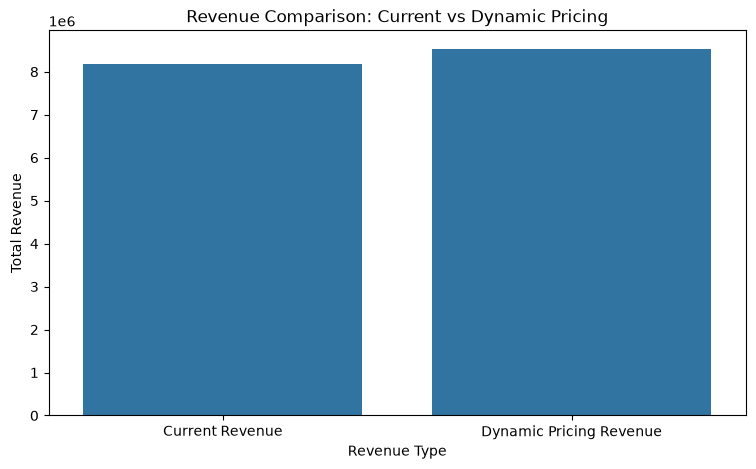

In [242]:
revenue_comparison = pd.DataFrame({
    'Revenue Type': ['Current Revenue', 'Dynamic Pricing Revenue'],
    'Revenue': [baseline_total, simulated_total]
})

plt.figure(figsize=(9,5))

sns.barplot(
    data=revenue_comparison,
    x='Revenue Type',
    y='Revenue'
)

plt.title('Revenue Comparison: Current vs Dynamic Pricing')
plt.ylabel('Total Revenue')

plt.show()

In [243]:
time_revenue = df.groupby('time_period').agg(
    current_revenue=('baseline_revenue', 'sum'),
    dynamic_revenue=('simulated_revenue', 'sum')
).reset_index()

time_revenue['revenue_uplift_pct'] = (
    (time_revenue['dynamic_revenue'] -
     time_revenue['current_revenue']) /
    time_revenue['current_revenue']
) * 100

time_revenue

,time_period,current_revenue,dynamic_revenue,revenue_uplift_pct
0,Normal,6557039.46,6.905830e+06,5.319335
1,Off-Peak,510944.56,5.064268e+05,-0.884200
2,Peak,1103116.10,1.121002e+06,1.621387


In [244]:
period_analysis = df.groupby('time_period').agg(
    total_sessions=('session_id', 'count'),
    total_energy=('energy_kwh', 'sum'),
    avg_current_price=('price_per_kwh', 'mean'),
    avg_recommended_price=('recommended_price', 'mean'),
    current_revenue=('baseline_revenue', 'sum'),
    dynamic_revenue=('simulated_revenue', 'sum')
).reset_index()

period_analysis

,time_period,total_sessions,total_energy,avg_current_price,avg_recommended_price,current_revenue,dynamic_revenue
0,Normal,237756,11166640.6,0.587767,0.624959,6557039.46,6.905830e+06
1,Off-Peak,18848,883529.7,0.578997,0.572561,510944.56,5.064268e+05
2,Peak,37420,1758575.5,0.627949,0.639736,1103116.10,1.121002e+06


In [245]:
def time_pricing(period):

    if period == 'Peak':
        return 1.05

    elif period == 'Off-Peak':
        return 0.95

    else:
        return 1.00


df['time_multiplier'] = df['time_period'].apply(time_pricing)

df['time_based_price'] = (
    df['price_per_kwh'] * df['time_multiplier']
)

df[['time_period', 'price_per_kwh',
    'time_based_price']].head(10)

,time_period,price_per_kwh,time_based_price
0,Normal,0.56,0.560
1,Normal,0.51,0.510
2,Peak,0.52,0.546
3,Normal,0.45,0.450
4,Normal,0.52,0.520
5,Normal,0.53,0.530
6,Normal,0.53,0.530
7,Normal,0.59,0.590
8,Normal,0.58,0.580
9,Peak,0.54,0.567


In [246]:
df['time_price_ratio'] = (
    df['time_based_price'] / df['price_per_kwh']
)

df['time_demand_factor'] = (
    df['time_price_ratio'] ** price_elasticity
)

df['time_simulated_revenue'] = (
    df['baseline_revenue'] *
    df['time_price_ratio'] *
    df['time_demand_factor']
)

time_baseline_revenue = df['baseline_revenue'].sum()

time_dynamic_revenue = df['time_simulated_revenue'].sum()

time_uplift = (
    (time_dynamic_revenue - time_baseline_revenue)
    / time_baseline_revenue
) * 100

print("Current Revenue:", round(time_baseline_revenue, 2))

print("Time-Based Revenue:", round(time_dynamic_revenue, 2))

print("Revenue Uplift:", round(time_uplift, 2), "%")

Current Revenue: 8171100.12
Time-Based Revenue: 8195578.1
Revenue Uplift: 0.3 %


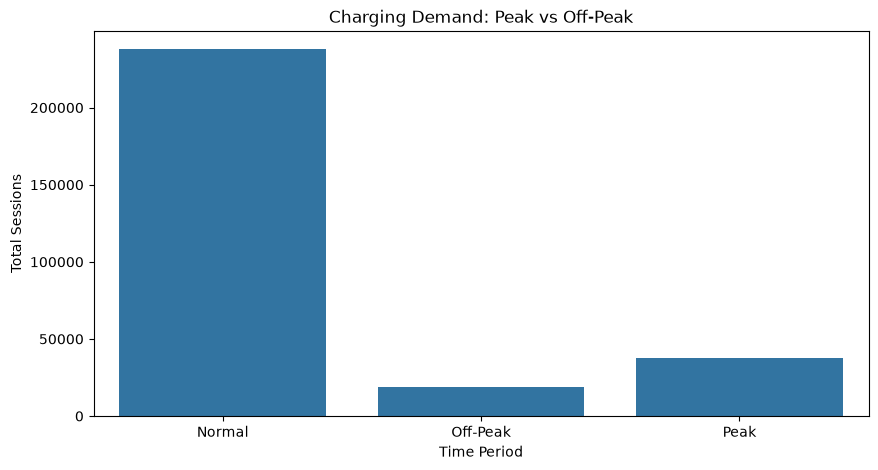

In [247]:
plt.figure(figsize=(10,5))

sns.barplot(
    data=period_analysis,
    x='time_period',
    y='total_sessions'
)

plt.title('Charging Demand: Peak vs Off-Peak')
plt.xlabel('Time Period')
plt.ylabel('Total Sessions')

plt.show()

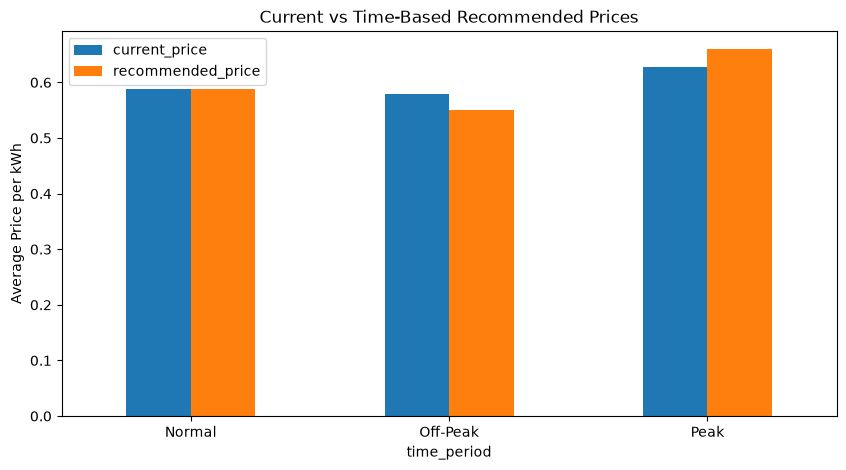

In [248]:
price_comparison = df.groupby('time_period').agg(
    current_price=('price_per_kwh', 'mean'),
    recommended_price=('time_based_price', 'mean')
).reset_index()

price_comparison.plot(
    x='time_period',
    kind='bar',
    figsize=(10,5)
)

plt.title('Current vs Time-Based Recommended Prices')
plt.ylabel('Average Price per kWh')
plt.xticks(rotation=0)
plt.show()

In [249]:
pricing_recommendations = df.groupby(
    ['station_region', 'charger_type', 'time_period']
).agg(
    avg_current_price=('price_per_kwh', 'mean'),
    avg_recommended_price=('recommended_price', 'mean'),
    total_sessions=('session_id', 'count'),
    total_energy=('energy_kwh', 'sum'),
    expected_revenue=('simulated_revenue', 'sum')
).reset_index()

pricing_recommendations.head(20)

,station_region,charger_type,time_period,avg_current_price,avg_recommended_price,total_sessions,total_energy,expected_revenue
0,London,DC_150kW,Normal,0.586867,0.633084,7035,344301.0,215264.831445
1,London,DC_150kW,Off-Peak,0.580790,0.582750,544,26672.6,15539.668533
2,London,DC_150kW,Peak,0.628264,0.649573,1152,56454.6,36459.474333
3,London,DC_300kW,Normal,0.582736,0.628500,9385,708596.5,439770.552453
4,London,DC_300kW,Off-Peak,0.577709,0.579121,729,55199.9,31949.550460
5,London,DC_300kW,Peak,0.622487,0.643536,1496,113499.3,72610.814260
6,London,DC_50kW,Normal,0.588876,0.635226,16546,545793.2,342404.448349
7,London,DC_50kW,Off-Peak,0.579255,0.580716,1302,42891.4,24901.710897
8,London,DC_50kW,Peak,0.629024,0.650123,2571,84682.1,54754.929032
9,Midlands,DC_150kW,Normal,0.578715,0.624316,12840,628720.8,387686.761780


In [250]:
pricing_recommendations.to_csv(
    'dynamic_pricing_recommendations.csv',
    index=False
)

print("Pricing recommendations exported successfully!")

Pricing recommendations exported successfully!


In [251]:
dashboard_data = df.groupby(
    ['hour', 'station_region', 'charger_type', 'time_period']
).agg(
    total_sessions=('session_id', 'count'),
    total_energy=('energy_kwh', 'sum'),
    current_price=('price_per_kwh', 'mean'),
    recommended_price=('recommended_price', 'mean'),
    current_revenue=('baseline_revenue', 'sum'),
    dynamic_revenue=('simulated_revenue', 'sum')
).reset_index()

dashboard_data.to_csv(
    'dynamic_pricing_dashboard_data.csv',
    index=False
)

print("Dashboard dataset exported successfully!")

Dashboard dataset exported successfully!


In [252]:
import streamlit as st
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Page configuration
st.set_page_config(
    page_title="EV Dynamic Pricing System",
    page_icon="⚡",
    layout="wide"
)

# Load data
@st.cache_data
def load_data():
    return pd.read_csv("dynamic_pricing_dashboard_data.csv")

df = load_data()

# Title
st.title("⚡ EV Dynamic Pricing Recommendation System")

st.markdown(
    "An intelligent pricing system based on demand, "
    "time, region and charger type."
)

st.divider()

# Sidebar filters
st.sidebar.header("Pricing Filters")

regions = ["All"] + sorted(df['station_region'].dropna().unique().tolist())

chargers = ["All"] + sorted(df['charger_type'].dropna().unique().tolist())

selected_region = st.sidebar.selectbox(
    "Select Region", regions
)

selected_charger = st.sidebar.selectbox(
    "Select Charger Type", chargers
)

# Apply filters
filtered = df.copy()

if selected_region != "All":
    filtered = filtered[
        filtered['station_region'] == selected_region
    ]

if selected_charger != "All":
    filtered = filtered[
        filtered['charger_type'] == selected_charger
    ]

# KPIs
current_revenue = filtered['current_revenue'].sum()

dynamic_revenue = filtered['dynamic_revenue'].sum()

uplift = (
    (dynamic_revenue - current_revenue) /
    current_revenue * 100
    if current_revenue != 0 else 0
)

avg_current = np.average(
    filtered['current_price'],
    weights=filtered['total_sessions']
)

avg_recommended = np.average(
    filtered['recommended_price'],
    weights=filtered['total_sessions']
)

c1, c2, c3, c4 = st.columns(4)

c1.metric(
    "Current Revenue",
    f"₹{current_revenue:,.2f}"
)

c2.metric(
    "Dynamic Revenue",
    f"₹{dynamic_revenue:,.2f}"
)

c3.metric(
    "Revenue Uplift",
    f"{uplift:.2f}%"
)

c4.metric(
    "Recommended Avg Price",
    f"₹{avg_recommended:.2f}/kWh"
)

st.divider()

# Hourly demand
st.subheader("1. Hourly Charging Demand")

hourly = filtered.groupby('hour')['total_sessions'].sum()

st.line_chart(hourly)

# Price comparison
st.subheader("2. Current vs Recommended Pricing")

price_data = filtered.groupby('time_period').agg(
    current_price=('current_price', 'mean'),
    recommended_price=('recommended_price', 'mean')
)

st.bar_chart(price_data)

# Regional analysis
st.subheader("3. Regional Charging Demand")

regional = df.groupby('station_region')['total_sessions'].sum()

st.bar_chart(regional)

# Charger analysis
st.subheader("4. Charger Type Analysis")

charger = filtered.groupby('charger_type').agg(
    sessions=('total_sessions', 'sum'),
    energy=('total_energy', 'sum')
)

st.dataframe(charger, use_container_width=True)

# Pricing recommendations
st.subheader("5. Dynamic Pricing Recommendations")

st.dataframe(
    filtered.sort_values(
        by='recommended_price',
        ascending=False
    ),
    use_container_width=True
)

# Download recommendations
csv = filtered.to_csv(index=False)

st.download_button(
    label="Download Pricing Recommendations",
    data=csv,
    file_name="pricing_recommendations.csv",
    mime="text/csv"
)

st.divider()

st.success(
    "Dynamic Pricing Recommendation System is running successfully!"
)

2026-11-28 17:39:24.950 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-28 17:39:24.951 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager
2026-11-28 17:39:24.955 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager
2026-11-28 17:39:24.956 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-28 17:39:25.001 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-28 17:39:27.614 
  command:

    streamlit run C:\Users\pranjali sharma\anaconda3\Lib\site-packages\ipykernel_launcher.py [ARGUMENTS]
2026-11-28 17:39:27.616 Thread 'MainT

DeltaGenerator()

In [254]:
import os

print("Current folder:", os.getcwd())

print("\nFiles available:")
print(os.listdir())

Current folder: C:\Users\pranjali sharma\EV_Demand_Forecasting

Files available:
['.ipynb_checkpoints', 'app.py', 'charger_health_indicators.csv', 'charger_type_hourly_demand.csv', 'charger_type_hourly_heatmap.png', 'charger_type_summary.csv', 'cleaned_daily_demand.csv', 'customer_behaviour_features.csv', 'customer_segmentation_final.csv', 'customer_segment_summary.csv', 'daily_demand.csv', 'dynamic_pricing_dashboard_data.csv', 'dynamic_pricing_recommendations.csv', 'ev_charging_dataset.xlsx', 'EV_Demand_Forecasting_Analysis.ipynb', 'final_365_day_forecast.csv', 'forecast_30_days.csv', 'forecast_365_days.csv', 'forecast_90_days.csv', 'forecast_summary.csv', 'health_indicator_report.csv', 'hourly_demand.csv', 'hourly_demand.png', 'hourly_demand_summary.csv', 'location_scoring_model.csv', 'maintenance_priority_list.csv', 'model_comparison.csv', 'monthly_seasonal_demand.png', 'monthly_seasonal_summary.csv', 'prophet_results.csv', 'README.md', 'regional_demand_analysis.csv', 'regional_dema